In [1]:
# ============================================================
# CELL 1 — RAW + MENTALBERT EXPERIMENT SETUP
# ============================================================

import os
import re
import gc
import json
import random
import warnings

import numpy as np
import pandas as pd
import torch

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# REPRODUCIBILITY
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ------------------------------------------------------------
# DEVICE
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("=" * 60)
print("RAW + MENTALBERT EXPERIMENT")
print("=" * 60)

print()
print("Device:", device)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

    print(
        "CUDA:",
        torch.version.cuda
    )

# ------------------------------------------------------------
# EXPERIMENT IDENTITY
# ------------------------------------------------------------

EXPERIMENT_NAME = "RAW + MentalBERT"

CLEANING_METHOD = (
    "Raw text after diagnostic anchor removal"
)

MODEL_NAME = "mental/mental-bert-base-uncased"

MAX_LENGTH = 512

print()
print("Model:", MODEL_NAME)
print("Cleaning:", CLEANING_METHOD)
print("Context length:", MAX_LENGTH)

# ------------------------------------------------------------
# MODEL DESCRIPTION
# ------------------------------------------------------------

print()
print("=" * 60)
print("MODEL CONFIGURATION")
print("=" * 60)

print("Architecture: MentalBERT")
print("Expected context length: 512 tokens")
print("Metadata features: 53")
print("Additional text cleaning: None")

# ------------------------------------------------------------
# RESULT DIRECTORIES
# ------------------------------------------------------------

MENTAL_RAW_RESULT_DIR = (
    "/kaggle/working/"
    "mentalbert_raw_results"
)

MENTAL_RAW_CHECKPOINT_DIR = (
    "/kaggle/working/"
    "mentalbert_raw_checkpoints"
)

MENTAL_RAW_BACKUP_DIR = (
    "/kaggle/working/"
    "MentalBERT_RAW_FINAL_BACKUP"
)

os.makedirs(
    MENTAL_RAW_RESULT_DIR,
    exist_ok=True
)

os.makedirs(
    MENTAL_RAW_CHECKPOINT_DIR,
    exist_ok=True
)

os.makedirs(
    MENTAL_RAW_BACKUP_DIR,
    exist_ok=True
)

# ------------------------------------------------------------
# CONFIGURATION
# ------------------------------------------------------------

MENTAL_RAW_CONFIG = {

    "experiment":
        EXPERIMENT_NAME,

    "model":
        "MentalBERT",

    "checkpoint":
        MODEL_NAME,

    "cleaning":
        CLEANING_METHOD,

    "additional_cleaning":
        False,

    "context_length":
        MAX_LENGTH,

    "seed":
        SEED,

    "device":
        str(device),

    "metadata_features":
        53,

    "fixed_controls": [

        "Exact user-level split",

        "Diagnostic anchor detection",

        "Diagnostic anchor removal",

        "D2 preservation",

        "53 metadata features",

        "Train-only StandardScaler",

        "Train-only random undersampling",

        "Held-out test evaluation"
    ]
}

with open(
    os.path.join(
        MENTAL_RAW_RESULT_DIR,
        "mentalbert_raw_experiment_config.json"
    ),
    "w"
) as f:

    json.dump(
        MENTAL_RAW_CONFIG,
        f,
        indent=2
    )

# ------------------------------------------------------------
# FINAL
# ------------------------------------------------------------

print()
print("=" * 60)
print("CELL 1 COMPLETE")
print("=" * 60)

print("✓ MentalBERT selected")
print("✓ RAW condition selected")
print("✓ Context length = 512")
print("✓ Seed = 42")
print("✓ Result directory created")
print("✓ Checkpoint directory created")
print("✓ Backup directory created")
print("✓ No additional text cleaning")
print("✓ E2/E3/E4/RAW outputs remain untouched")

RAW + MENTALBERT EXPERIMENT

Device: cuda
GPU: Tesla T4
CUDA: 12.8

Model: mental/mental-bert-base-uncased
Cleaning: Raw text after diagnostic anchor removal
Context length: 512

MODEL CONFIGURATION
Architecture: MentalBERT
Expected context length: 512 tokens
Metadata features: 53
Additional text cleaning: None

CELL 1 COMPLETE
✓ MentalBERT selected
✓ RAW condition selected
✓ Context length = 512
✓ Seed = 42
✓ Result directory created
✓ Checkpoint directory created
✓ Backup directory created
✓ No additional text cleaning
✓ E2/E3/E4/RAW outputs remain untouched


In [2]:
# ============================================================
# CELL 2 — MENTALBERT RAW: LOAD EXACT USER-LEVEL SPLIT
# SAME SPLIT AS ALL PREVIOUS EXPERIMENTS
# ============================================================

print("=" * 60)
print("MENTALBERT RAW — LOADING EXACT USER-LEVEL SPLIT")
print("=" * 60)


# ------------------------------------------------------------
# SPLIT DATASET
# ------------------------------------------------------------

SPLIT_ROOT = (
    "/kaggle/input/datasets/"
    "vedantnawghare35/"
    "mddl-experiment-1-splits"
)

TRAIN_PATH = os.path.join(
    SPLIT_ROOT,
    "MDDL_train_raw.pkl"
)

VAL_PATH = os.path.join(
    SPLIT_ROOT,
    "MDDL_val_raw.pkl"
)

TEST_PATH = os.path.join(
    SPLIT_ROOT,
    "MDDL_test_raw.pkl"
)

print()
print("TRAIN:", TRAIN_PATH)
print("VAL:  ", VAL_PATH)
print("TEST: ", TEST_PATH)


# ------------------------------------------------------------
# FILE VERIFICATION
# ------------------------------------------------------------

for path in [
    TRAIN_PATH,
    VAL_PATH,
    TEST_PATH
]:

    assert os.path.exists(
        path
    ), (
        f"Missing split file:\n{path}"
    )

print()
print("✓ All split files found")


# ------------------------------------------------------------
# LOAD
# ------------------------------------------------------------

print()
print("Loading TRAIN...")

train_df = pd.read_pickle(
    TRAIN_PATH
)

print("Loading VALIDATION...")

val_df = pd.read_pickle(
    VAL_PATH
)

print("Loading TEST...")

test_df = pd.read_pickle(
    TEST_PATH
)


# ------------------------------------------------------------
# SHAPES
# ------------------------------------------------------------

print()
print("=" * 60)
print("SPLIT SHAPES")
print("=" * 60)

print(
    "Train:",
    train_df.shape
)

print(
    "Validation:",
    val_df.shape
)

print(
    "Test:",
    test_df.shape
)

assert len(train_df) == 6135
assert len(val_df) == 767
assert len(test_df) == 767


# ------------------------------------------------------------
# REQUIRED COLUMNS
# ------------------------------------------------------------

print()
print("=" * 60)
print("REQUIRED COLUMN CHECK")
print("=" * 60)

required_columns = [
    "user_id",
    "username",
    "label",
    "timeline_text"
]

for column in required_columns:

    assert column in train_df.columns
    assert column in val_df.columns
    assert column in test_df.columns

    print(
        f"✓ {column}"
    )


# ------------------------------------------------------------
# USER-LEVEL INTEGRITY
# ------------------------------------------------------------

print()
print("=" * 60)
print("USER-LEVEL INTEGRITY")
print("=" * 60)

train_users = set(
    train_df["user_id"]
)

val_users = set(
    val_df["user_id"]
)

test_users = set(
    test_df["user_id"]
)

print(
    "Train unique users:",
    train_df["user_id"].nunique()
)

print(
    "Validation unique users:",
    val_df["user_id"].nunique()
)

print(
    "Test unique users:",
    test_df["user_id"].nunique()
)

assert train_df["user_id"].is_unique
assert val_df["user_id"].is_unique
assert test_df["user_id"].is_unique


print(
    "TRAIN ↔ VAL:",
    len(
        train_users & val_users
    )
)

print(
    "TRAIN ↔ TEST:",
    len(
        train_users & test_users
    )
)

print(
    "VAL ↔ TEST:",
    len(
        val_users & test_users
    )
)

assert len(
    train_users & val_users
) == 0

assert len(
    train_users & test_users
) == 0

assert len(
    val_users & test_users
) == 0

print()
print("✓ No duplicate users")
print("✓ No cross-split overlap")


# ------------------------------------------------------------
# LABEL DISTRIBUTION
# ------------------------------------------------------------

print()
print("=" * 60)
print("LABEL DISTRIBUTION")
print("=" * 60)

print()
print("TRAIN:")
print(
    train_df["label"]
    .value_counts()
    .sort_index()
)

print()
print("VALIDATION:")
print(
    val_df["label"]
    .value_counts()
    .sort_index()
)

print()
print("TEST:")
print(
    test_df["label"]
    .value_counts()
    .sort_index()
)


assert (
    train_df["label"]
    .value_counts()
    .sort_index()
    .to_dict()
    == {
        0: 4122,
        1: 2013
    }
)

assert (
    val_df["label"]
    .value_counts()
    .sort_index()
    .to_dict()
    == {
        0: 515,
        1: 252
    }
)

assert (
    test_df["label"]
    .value_counts()
    .sort_index()
    .to_dict()
    == {
        0: 516,
        1: 251
    }
)


# ------------------------------------------------------------
# FINAL
# ------------------------------------------------------------

print()
print("=" * 60)
print("CELL 2 COMPLETE")
print("=" * 60)

print("✓ Exact user-level split restored")
print("✓ TRAIN = 6135")
print("✓ VALIDATION = 767")
print("✓ TEST = 767")
print("✓ Same user IDs as previous experiments")
print("✓ Same labels")
print("✓ No cross-split overlap")
print("✓ Timeline text available")

MENTALBERT RAW — LOADING EXACT USER-LEVEL SPLIT

TRAIN: /kaggle/input/datasets/vedantnawghare35/mddl-experiment-1-splits/MDDL_train_raw.pkl
VAL:   /kaggle/input/datasets/vedantnawghare35/mddl-experiment-1-splits/MDDL_val_raw.pkl
TEST:  /kaggle/input/datasets/vedantnawghare35/mddl-experiment-1-splits/MDDL_test_raw.pkl

✓ All split files found

Loading TRAIN...
Loading VALIDATION...
Loading TEST...

SPLIT SHAPES
Train: (6135, 82)
Validation: (767, 82)
Test: (767, 82)

REQUIRED COLUMN CHECK
✓ user_id
✓ username
✓ label
✓ timeline_text

USER-LEVEL INTEGRITY
Train unique users: 6135
Validation unique users: 767
Test unique users: 767
TRAIN ↔ VAL: 0
TRAIN ↔ TEST: 0
VAL ↔ TEST: 0

✓ No duplicate users
✓ No cross-split overlap

LABEL DISTRIBUTION

TRAIN:
label
0    4122
1    2013
Name: count, dtype: int64

VALIDATION:
label
0    515
1    252
Name: count, dtype: int64

TEST:
label
0    516
1    251
Name: count, dtype: int64

CELL 2 COMPLETE
✓ Exact user-level split restored
✓ TRAIN = 6135
✓ VAL

In [3]:
# ============================================================
# CELL 3 — MENTALBERT RAW: EXACT D1 ANCHOR DETECTION
# SAME CONTROL AS E2 / E3 / E4 / RAW
# ============================================================

import os
import re
import json
import glob
from collections import defaultdict

print("=" * 60)
print("MENTALBERT RAW — EXACT D1 ANCHOR DETECTION")
print("=" * 60)

# ------------------------------------------------------------
# ORIGINAL DATASET
# ------------------------------------------------------------

DATASET_ROOT = (
    "/kaggle/input/datasets/"
    "vedantnawghare35/"
    "depression-detection-mddl-final-pbl/"
    "Dataset_MDDL"
)

positive_timeline_dir = os.path.join(
    DATASET_ROOT,
    "labeled",
    "positive",
    "data",
    "timeline"
)

assert os.path.exists(
    positive_timeline_dir
)

positive_timeline_files = glob.glob(
    os.path.join(
        positive_timeline_dir,
        "*.json"
    )
)

print()
print(
    "D1 timeline files found:",
    len(positive_timeline_files)
)

assert len(
    positive_timeline_files
) == 2626


# ------------------------------------------------------------
# EXACT REFINED E3 ANCHOR DETECTOR
# ------------------------------------------------------------

REFINED_ANCHOR_PATTERNS = [

    r"\bi(?:'m| am)\s+diagnosed\s+with\s+(?:major\s+)?depression\b",

    r"\bi\s+(?:was|were)\s+diagnosed\s+with\s+(?:major\s+)?depression\b",

    r"\bi(?:'ve| have)\s+been\s+diagnosed\s+with\s+(?:major\s+)?depression\b",

    r"\bi(?:'m| am)\s+diagnosed\s+with\s+(?:major\s+)?depressive\s+disorder\b",

    r"\bi\s+(?:was|were)\s+diagnosed\s+with\s+(?:major\s+)?depressive\s+disorder\b",

    r"\bi(?:'ve| have)\s+been\s+diagnosed\s+with\s+(?:major\s+)?depressive\s+disorder\b",

    r"\bi\s+have\s+(?:major\s+)?depression\b",

    r"\bi\s+suffer\s+from\s+(?:major\s+)?depression\b",

    r"\bi\s+(?:was|am|'m)\s+diagnosed\b.{0,80}\bdepress",

    r"\b(?:my|a)\s+(?:doctor|psychiatrist)\s+(?:has\s+)?diagnosed\s+me\b.{0,80}\bdepress"
]

REFINED_COMPILED_PATTERNS = [
    re.compile(
        pattern,
        flags=re.IGNORECASE | re.DOTALL
    )
    for pattern in REFINED_ANCHOR_PATTERNS
]


# ------------------------------------------------------------
# EXCLUSIONS
# ------------------------------------------------------------

EXCLUSION_PATTERNS = [

    r"\bmy\s+friend\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+sister\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+brother\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+mother\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+father\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+answer\s+to\s*:",

    r"\banswer\s+to\s*:",

    r"\bquestion\s*:",

    r"\bq\s*:"
]

COMPILED_EXCLUSION_PATTERNS = [
    re.compile(
        pattern,
        flags=re.IGNORECASE | re.DOTALL
    )
    for pattern in EXCLUSION_PATTERNS
]


def is_refined_anchor_tweet(text):

    if text is None:
        return False

    text = str(text).strip()

    if not text:
        return False

    for pattern in COMPILED_EXCLUSION_PATTERNS:

        if pattern.search(text):
            return False

    for pattern in REFINED_COMPILED_PATTERNS:

        if pattern.search(text):
            return True

    return False


# ------------------------------------------------------------
# POSITIVE USERS BY SPLIT
# ------------------------------------------------------------

train_positive_usernames = set(
    train_df.loc[
        train_df["label"] == 1,
        "username"
    ].astype(str)
)

val_positive_usernames = set(
    val_df.loc[
        val_df["label"] == 1,
        "username"
    ].astype(str)
)

test_positive_usernames = set(
    test_df.loc[
        test_df["label"] == 1,
        "username"
    ].astype(str)
)

all_positive_split_usernames = (
    train_positive_usernames
    | val_positive_usernames
    | test_positive_usernames
)

print()
print("=" * 60)
print("POSITIVE USERS BY SPLIT")
print("=" * 60)

print(
    "TRAIN:",
    len(train_positive_usernames)
)

print(
    "VALIDATION:",
    len(val_positive_usernames)
)

print(
    "TEST:",
    len(test_positive_usernames)
)

assert len(
    train_positive_usernames
) == 2013

assert len(
    val_positive_usernames
) == 252

assert len(
    test_positive_usernames
) == 251

assert len(
    all_positive_split_usernames
) == 2516


# ------------------------------------------------------------
# INDEX D1 FILES
# ------------------------------------------------------------

positive_files_by_user = defaultdict(list)

for timeline_file in positive_timeline_files:

    filename = os.path.basename(
        timeline_file
    )

    username = filename.split(
        "created_at"
    )[0]

    positive_files_by_user[
        username
    ].append(
        timeline_file
    )

assert len(
    positive_files_by_user
) == 2516


# ------------------------------------------------------------
# EXACT SCAN
# ------------------------------------------------------------

split_anchor_records = []

users_processed = set()
tweets_scanned = 0

for username in sorted(
    all_positive_split_usernames
):

    if username not in positive_files_by_user:

        raise KeyError(
            f"Missing timeline for user: {username}"
        )

    users_processed.add(
        username
    )

    for timeline_file in (
        positive_files_by_user[username]
    ):

        with open(
            timeline_file,
            "r",
            encoding="utf-8"
        ) as f:

            for line in f:

                line = line.strip()

                if not line:
                    continue

                record = json.loads(
                    line
                )

                tweets_scanned += 1

                tweet_id = record.get(
                    "id_str",
                    record.get(
                        "id",
                        ""
                    )
                )

                tweet_text = record.get(
                    "text",
                    ""
                )

                if (
                    tweet_id
                    and
                    is_refined_anchor_tweet(
                        tweet_text
                    )
                ):

                    split_anchor_records.append(
                        {
                            "username":
                                username,

                            "tweet_id":
                                str(tweet_id),

                            "created_at":
                                record.get(
                                    "created_at"
                                ),

                            "text":
                                str(tweet_text)
                        }
                    )


# ------------------------------------------------------------
# UNIQUE ANCHOR PAIRS
# ------------------------------------------------------------

exact_anchor_pairs = {
    (
        record["username"],
        record["tweet_id"]
    )
    for record in split_anchor_records
}


# ------------------------------------------------------------
# SPLIT-SPECIFIC ANCHORS
# ------------------------------------------------------------

train_anchor_pairs = {
    pair
    for pair in exact_anchor_pairs
    if pair[0] in train_positive_usernames
}

val_anchor_pairs = {
    pair
    for pair in exact_anchor_pairs
    if pair[0] in val_positive_usernames
}

test_anchor_pairs = {
    pair
    for pair in exact_anchor_pairs
    if pair[0] in test_positive_usernames
}


# ------------------------------------------------------------
# SUMMARY
# ------------------------------------------------------------

print()
print("=" * 60)
print("EXACT ANCHOR SUMMARY")
print("=" * 60)

print(
    "Positive users processed:",
    len(users_processed)
)

print(
    "Tweets scanned:",
    tweets_scanned
)

print(
    "Raw anchor records:",
    len(split_anchor_records)
)

print(
    "Unique anchor pairs:",
    len(exact_anchor_pairs)
)

print()
print(
    "TRAIN unique anchors:",
    len(train_anchor_pairs)
)

print(
    "VAL unique anchors:",
    len(val_anchor_pairs)
)

print(
    "TEST unique anchors:",
    len(test_anchor_pairs)
)


# ------------------------------------------------------------
# EXACT CONTROL CHECK
# ------------------------------------------------------------

assert len(
    users_processed
) == 2516

assert len(
    split_anchor_records
) == 1920

assert len(
    exact_anchor_pairs
) == 1847

assert len(
    train_anchor_pairs
) == 1476

assert len(
    val_anchor_pairs
) == 190

assert len(
    test_anchor_pairs
) == 181


# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

mentalbert_raw_anchor_df = pd.DataFrame(
    split_anchor_records
)

mentalbert_raw_anchor_df.to_csv(
    os.path.join(
        MENTAL_RAW_RESULT_DIR,
        "mentalbert_raw_exact_anchor_records.csv"
    ),
    index=False
)


print()
print("=" * 60)
print("CELL 3 COMPLETE")
print("=" * 60)

print("✓ Exact E3/E4 anchor detector reproduced")
print("✓ 1,847 unique anchors confirmed")
print("✓ 1,920 anchor records confirmed")
print("✓ TRAIN = 1,476 unique anchors")
print("✓ VAL = 190 unique anchors")
print("✓ TEST = 181 unique anchors")
print("✓ No D2 users included")
print("✓ Anchor records saved")
print("✓ No timelines modified yet")

MENTALBERT RAW — EXACT D1 ANCHOR DETECTION

D1 timeline files found: 2626

POSITIVE USERS BY SPLIT
TRAIN: 2013
VALIDATION: 252
TEST: 251

EXACT ANCHOR SUMMARY
Positive users processed: 2516
Tweets scanned: 508806
Raw anchor records: 1920
Unique anchor pairs: 1847

TRAIN unique anchors: 1476
VAL unique anchors: 190
TEST unique anchors: 181

CELL 3 COMPLETE
✓ Exact E3/E4 anchor detector reproduced
✓ 1,847 unique anchors confirmed
✓ 1,920 anchor records confirmed
✓ TRAIN = 1,476 unique anchors
✓ VAL = 190 unique anchors
✓ TEST = 181 unique anchors
✓ No D2 users included
✓ Anchor records saved
✓ No timelines modified yet


In [4]:
# ============================================================
# CELL 4 — MENTALBERT RAW ANCHOR REMOVAL
# SAME AS ALL PREVIOUS CONTROLLED EXPERIMENTS
# ============================================================

print("=" * 60)
print("MENTALBERT RAW — EXACT D1 ANCHOR REMOVAL")
print("=" * 60)


# ------------------------------------------------------------
# EXPECTED COUNTS
# ------------------------------------------------------------

EXPECTED_TRAIN_REMOVED = 1535
EXPECTED_VAL_REMOVED   = 199
EXPECTED_TEST_REMOVED  = 186
EXPECTED_TOTAL_REMOVED = 1920


# ------------------------------------------------------------
# PRE-REMOVAL VERIFICATION
# ------------------------------------------------------------

print()
print("=" * 60)
print("PRE-REMOVAL ANCHOR VERIFICATION")
print("=" * 60)

duplicate_occurrences = (
    len(split_anchor_records)
    - len(exact_anchor_pairs)
)

print(
    "Raw anchor records:",
    len(split_anchor_records)
)

print(
    "Unique anchor pairs:",
    len(exact_anchor_pairs)
)

print(
    "Duplicate anchor occurrences:",
    duplicate_occurrences
)

assert len(split_anchor_records) == 1920
assert len(exact_anchor_pairs) == 1847
assert duplicate_occurrences == 73

print("✓ 1,847 unique anchors verified")
print("✓ 73 duplicate occurrences verified")
print("✓ 1,920 total anchor records verified")


# ------------------------------------------------------------
# SPLIT-LEVEL RECORD COUNTS
# ------------------------------------------------------------

train_anchor_records = [
    r
    for r in split_anchor_records
    if r["username"] in train_positive_usernames
]

val_anchor_records = [
    r
    for r in split_anchor_records
    if r["username"] in val_positive_usernames
]

test_anchor_records = [
    r
    for r in split_anchor_records
    if r["username"] in test_positive_usernames
]

print()
print("=" * 60)
print("SPLIT-LEVEL ANCHOR RECORD COUNTS")
print("=" * 60)

print(
    "TRAIN:",
    len(train_anchor_records),
    "| expected:",
    EXPECTED_TRAIN_REMOVED
)

print(
    "VAL:",
    len(val_anchor_records),
    "| expected:",
    EXPECTED_VAL_REMOVED
)

print(
    "TEST:",
    len(test_anchor_records),
    "| expected:",
    EXPECTED_TEST_REMOVED
)

assert len(train_anchor_records) == EXPECTED_TRAIN_REMOVED
assert len(val_anchor_records) == EXPECTED_VAL_REMOVED
assert len(test_anchor_records) == EXPECTED_TEST_REMOVED


# ------------------------------------------------------------
# EXACT ANCHOR SET
# ------------------------------------------------------------

EXACT_ANCHOR_SET = set(
    exact_anchor_pairs
)


# ------------------------------------------------------------
# INDEX ORIGINAL D1 TIMELINES
# ------------------------------------------------------------

positive_files_by_user = defaultdict(list)

for timeline_file in positive_timeline_files:

    filename = os.path.basename(
        timeline_file
    )

    username = filename.split(
        "created_at"
    )[0]

    positive_files_by_user[
        username
    ].append(
        timeline_file
    )

assert len(
    positive_files_by_user
) == 2516


# ------------------------------------------------------------
# BUILD RAW ANCHOR-REMOVED TEXT
# ------------------------------------------------------------

def build_mentalbert_raw_text(
    username
):

    kept_texts = []

    original_count = 0
    removed_count = 0

    for timeline_file in (
        positive_files_by_user[username]
    ):

        with open(
            timeline_file,
            "r",
            encoding="utf-8"
        ) as f:

            for line in f:

                line = line.strip()

                if not line:
                    continue

                record = json.loads(
                    line
                )

                original_count += 1

                tweet_id = str(
                    record.get(
                        "id_str",
                        record.get(
                            "id",
                            ""
                        )
                    )
                )

                pair = (
                    str(username),
                    tweet_id
                )

                if pair in EXACT_ANCHOR_SET:

                    removed_count += 1
                    continue

                text = str(
                    record.get(
                        "text",
                        ""
                    )
                ).strip()

                if text:

                    # RAW CONDITION:
                    # Preserve text exactly.
                    # No lowercasing.
                    # No URL removal.
                    # No mention removal.
                    # No emoji removal.
                    # No punctuation removal.
                    # No hashtag removal.
                    # No digit removal.
                    # No normalization.

                    kept_texts.append(
                        text
                    )

    return (
        " ".join(kept_texts),
        original_count,
        removed_count
    )


# ------------------------------------------------------------
# COPY ORIGINAL SPLITS
# ------------------------------------------------------------

train_mental_raw_df = train_df.copy(
    deep=True
)

val_mental_raw_df = val_df.copy(
    deep=True
)

test_mental_raw_df = test_df.copy(
    deep=True
)


# ------------------------------------------------------------
# PROCESS ALL D1 USERS
# ------------------------------------------------------------

positive_anchor_removed_raw = {}

train_removed = 0
val_removed = 0
test_removed = 0

for username in sorted(
    all_positive_split_usernames
):

    raw_text, _, removed_count = (
        build_mentalbert_raw_text(
            username
        )
    )

    positive_anchor_removed_raw[
        username
    ] = raw_text

    if username in train_positive_usernames:

        train_removed += removed_count

    elif username in val_positive_usernames:

        val_removed += removed_count

    elif username in test_positive_usernames:

        test_removed += removed_count


# ------------------------------------------------------------
# REMOVAL VERIFICATION
# ------------------------------------------------------------

print()
print("=" * 60)
print("FINAL ANCHOR REMOVAL COUNTS")
print("=" * 60)

print(
    "TRAIN removed:",
    train_removed
)

print(
    "VAL removed:",
    val_removed
)

print(
    "TEST removed:",
    test_removed
)

print(
    "TOTAL removed:",
    train_removed
    + val_removed
    + test_removed
)

assert train_removed == EXPECTED_TRAIN_REMOVED
assert val_removed == EXPECTED_VAL_REMOVED
assert test_removed == EXPECTED_TEST_REMOVED

assert (
    train_removed
    + val_removed
    + test_removed
    == EXPECTED_TOTAL_REMOVED
)

print()
print("✓ Record-level removal exactly matches previous experiments")


# ------------------------------------------------------------
# UPDATE ONLY POSITIVE USERS
# ------------------------------------------------------------

for df in [
    train_mental_raw_df,
    val_mental_raw_df,
    test_mental_raw_df
]:

    positive_mask = (
        df["label"] == 1
    )

    df.loc[
        positive_mask,
        "timeline_text"
    ] = (
        df.loc[
            positive_mask,
            "username"
        ]
        .astype(str)
        .map(
            positive_anchor_removed_raw
        )
        .fillna("")
        .values
    )


# ------------------------------------------------------------
# RAW MODEL TEXT
# ------------------------------------------------------------

train_mental_raw_df["model_text"] = (
    train_mental_raw_df[
        "timeline_text"
    ]
    .fillna("")
    .astype(str)
)

val_mental_raw_df["model_text"] = (
    val_mental_raw_df[
        "timeline_text"
    ]
    .fillna("")
    .astype(str)
)

test_mental_raw_df["model_text"] = (
    test_mental_raw_df[
        "timeline_text"
    ]
    .fillna("")
    .astype(str)
)


# ------------------------------------------------------------
# D2 PRESERVATION
# ------------------------------------------------------------

print()
print("=" * 60)
print("D2 PRESERVATION CHECK")
print("=" * 60)

for original, result, name in [

    (
        train_df,
        train_mental_raw_df,
        "TRAIN"
    ),

    (
        val_df,
        val_mental_raw_df,
        "VALIDATION"
    ),

    (
        test_df,
        test_mental_raw_df,
        "TEST"
    )

]:

    original_d2 = (
        original.loc[
            original["label"] == 0,
            ["username", "timeline_text"]
        ]
        .set_index("username")
        .sort_index()
    )

    result_d2 = (
        result.loc[
            result["label"] == 0,
            ["username", "timeline_text"]
        ]
        .set_index("username")
        .sort_index()
    )

    assert original_d2.equals(
        result_d2
    )

    print(
        f"✓ {name} D2 unchanged"
    )


# ------------------------------------------------------------
# USER + LABEL PRESERVATION
# ------------------------------------------------------------

print()
print("=" * 60)
print("USER + LABEL PRESERVATION")
print("=" * 60)

for original, result, name in [

    (
        train_df,
        train_mental_raw_df,
        "TRAIN"
    ),

    (
        val_df,
        val_mental_raw_df,
        "VALIDATION"
    ),

    (
        test_df,
        test_mental_raw_df,
        "TEST"
    )

]:

    assert list(
        original["user_id"]
    ) == list(
        result["user_id"]
    )

    assert list(
        original["username"]
    ) == list(
        result["username"]
    )

    assert list(
        original["label"]
    ) == list(
        result["label"]
    )

    print(
        f"✓ {name}: users and labels unchanged"
    )


# ------------------------------------------------------------
# RAW TEXT INTEGRITY
# ------------------------------------------------------------

print()
print("=" * 60)
print("RAW TEXT INTEGRITY")
print("=" * 60)

for name, df in [

    ("TRAIN", train_mental_raw_df),
    ("VALIDATION", val_mental_raw_df),
    ("TEST", test_mental_raw_df)

]:

    empty_count = int(
        (
            df["model_text"]
            .str.strip()
            == ""
        ).sum()
    )

    print(
        f"{name}: "
        f"empty model texts = "
        f"{empty_count}"
    )


# ------------------------------------------------------------
# PREVIEW
# ------------------------------------------------------------

print()
print("=" * 60)
print("MENTALBERT RAW TEXT PREVIEW")
print("=" * 60)

for _, row in train_mental_raw_df.head(3).iterrows():

    print()
    print(
        "User:",
        row["username"]
    )

    print(
        "Label:",
        row["label"]
    )

    print(
        row["model_text"][:1000]
    )


# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

train_mental_raw_df.to_pickle(
    os.path.join(
        MENTAL_RAW_RESULT_DIR,
        "mentalbert_raw_train_anchor_removed.pkl"
    )
)

val_mental_raw_df.to_pickle(
    os.path.join(
        MENTAL_RAW_RESULT_DIR,
        "mentalbert_raw_val_anchor_removed.pkl"
    )
)

test_mental_raw_df.to_pickle(
    os.path.join(
        MENTAL_RAW_RESULT_DIR,
        "mentalbert_raw_test_anchor_removed.pkl"
    )
)


print()
print("=" * 60)
print("CELL 4 COMPLETE")
print("=" * 60)

print("✓ 1,847 unique D1 anchors removed")
print("✓ 73 duplicate occurrences handled")
print("✓ 1,920 total records removed")
print("✓ TRAIN = 1,535 removed")
print("✓ VAL = 199 removed")
print("✓ TEST = 186 removed")
print("✓ D2 completely preserved")
print("✓ User IDs preserved")
print("✓ Labels preserved")
print("✓ NO additional text cleaning applied")
print("✓ MentalBERT RAW source saved")

MENTALBERT RAW — EXACT D1 ANCHOR REMOVAL

PRE-REMOVAL ANCHOR VERIFICATION
Raw anchor records: 1920
Unique anchor pairs: 1847
Duplicate anchor occurrences: 73
✓ 1,847 unique anchors verified
✓ 73 duplicate occurrences verified
✓ 1,920 total anchor records verified

SPLIT-LEVEL ANCHOR RECORD COUNTS
TRAIN: 1535 | expected: 1535
VAL: 199 | expected: 199
TEST: 186 | expected: 186

FINAL ANCHOR REMOVAL COUNTS
TRAIN removed: 1535
VAL removed: 199
TEST removed: 186
TOTAL removed: 1920

✓ Record-level removal exactly matches previous experiments

D2 PRESERVATION CHECK
✓ TRAIN D2 unchanged
✓ VALIDATION D2 unchanged
✓ TEST D2 unchanged

USER + LABEL PRESERVATION
✓ TRAIN: users and labels unchanged
✓ VALIDATION: users and labels unchanged
✓ TEST: users and labels unchanged

RAW TEXT INTEGRITY
TRAIN: empty model texts = 29
VALIDATION: empty model texts = 4
TEST: empty model texts = 1

MENTALBERT RAW TEXT PREVIEW

User: RompingFox
Label: 1
@cybershot_1 :( I'm making a wendy sound board for my cospla

In [6]:
# ============================================================
# KAGGLE → HUGGING FACE SECRET
# ============================================================

from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()

hf_token = user_secrets.get_secret("HF_TOKEN")

if hf_token:
    print("✓ HF_TOKEN successfully retrieved")
    print("Token length:", len(hf_token))
else:
    print("✗ HF_TOKEN is empty")

✓ HF_TOKEN successfully retrieved
Token length: 37


In [7]:
from transformers import AutoConfig, AutoTokenizer

MODEL_NAME = "mental/mental-bert-base-uncased"

print("=" * 60)
print("TESTING MENTALBERT ACCESS")
print("=" * 60)

config = AutoConfig.from_pretrained(
    MODEL_NAME,
    token=hf_token
)

print("✓ MentalBERT config loaded")

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    token=hf_token
)

print("✓ MentalBERT tokenizer loaded")

print()
print("Model type:", config.model_type)

print(
    "Max position embeddings:",
    getattr(
        config,
        "max_position_embeddings",
        None
    )
)

print()
print("=" * 60)
print("MENTALBERT ACCESS TEST COMPLETE")
print("=" * 60)

TESTING MENTALBERT ACCESS


config.json:   0%|          | 0.00/639 [00:00<?, ?B/s]

✓ MentalBERT config loaded


tokenizer_config.json:   0%|          | 0.00/321 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

✓ MentalBERT tokenizer loaded

Model type: bert
Max position embeddings: 512

MENTALBERT ACCESS TEST COMPLETE


In [8]:
# ============================================================
# CELL 5 — MENTALBERT RAW TOKEN-LENGTH ANALYSIS
# ============================================================

import os
import numpy as np
import pandas as pd

print("=" * 60)
print("MENTALBERT RAW — TOKEN LENGTH ANALYSIS")
print("=" * 60)

MODEL_NAME = "mental/mental-bert-base-uncased"
MODEL_MAX_LENGTH = 512


# ------------------------------------------------------------
# VERIFY AUTHENTICATED TOKENIZER
# ------------------------------------------------------------

mentalbert_raw_tokenizer = tokenizer

print()
print("Tokenizer:", MODEL_NAME)
print(
    "Model maximum position embeddings:",
    config.max_position_embeddings
)
print(
    "Experimental context length:",
    MODEL_MAX_LENGTH
)

assert (
    config.max_position_embeddings
    == MODEL_MAX_LENGTH
)

print("✓ Authenticated MentalBERT tokenizer reused")


# ------------------------------------------------------------
# TOKEN LENGTH FUNCTION
# ------------------------------------------------------------

def calculate_mental_raw_token_lengths(
    texts,
    split_name
):

    print()
    print(
        f"Processing {split_name}..."
    )

    lengths = []

    for idx, text in enumerate(texts):

        encoded = mentalbert_raw_tokenizer(
            str(text),
            add_special_tokens=True,
            truncation=False,
            padding=False
        )

        lengths.append(
            len(
                encoded["input_ids"]
            )
        )

        if (
            (idx + 1) % 1000 == 0
            or idx + 1 == len(texts)
        ):

            print(
                f"{split_name}: "
                f"{idx + 1}/{len(texts)}"
            )

    return np.asarray(
        lengths,
        dtype=np.int64
    )


# ------------------------------------------------------------
# CALCULATE
# ------------------------------------------------------------

train_mental_raw_token_lengths = (
    calculate_mental_raw_token_lengths(
        train_mental_raw_df["model_text"].tolist(),
        "TRAIN"
    )
)

val_mental_raw_token_lengths = (
    calculate_mental_raw_token_lengths(
        val_mental_raw_df["model_text"].tolist(),
        "VALIDATION"
    )
)

test_mental_raw_token_lengths = (
    calculate_mental_raw_token_lengths(
        test_mental_raw_df["model_text"].tolist(),
        "TEST"
    )
)


# ------------------------------------------------------------
# STATISTICS
# ------------------------------------------------------------

def print_mental_raw_statistics(
    lengths,
    split_name
):

    print()
    print("=" * 60)
    print(
        f"{split_name} TOKEN STATISTICS"
    )
    print("=" * 60)

    print(
        "Minimum:",
        int(lengths.min())
    )

    print(
        "Maximum:",
        int(lengths.max())
    )

    print(
        "Mean:",
        round(
            float(lengths.mean()),
            2
        )
    )

    print(
        "Median:",
        int(np.median(lengths))
    )

    print(
        "25th percentile:",
        int(np.percentile(lengths, 25))
    )

    print(
        "75th percentile:",
        int(np.percentile(lengths, 75))
    )

    print(
        "90th percentile:",
        int(np.percentile(lengths, 90))
    )

    print(
        "95th percentile:",
        int(np.percentile(lengths, 95))
    )

    print(
        "99th percentile:",
        int(np.percentile(lengths, 99))
    )

    within_512 = int(
        np.sum(
            lengths <= 512
        )
    )

    above_512 = int(
        np.sum(
            lengths > 512
        )
    )

    print()
    print("512-TOKEN COVERAGE")

    print(
        "Users <= 512:",
        within_512
    )

    print(
        "Users > 512:",
        above_512
    )

    print(
        "Percentage <= 512:",
        round(
            100 * within_512 / len(lengths),
            2
        ),
        "%"
    )

    print(
        "Percentage > 512:",
        round(
            100 * above_512 / len(lengths),
            2
        ),
        "%"
    )


print_mental_raw_statistics(
    train_mental_raw_token_lengths,
    "TRAIN"
)

print_mental_raw_statistics(
    val_mental_raw_token_lengths,
    "VALIDATION"
)

print_mental_raw_statistics(
    test_mental_raw_token_lengths,
    "TEST"
)


# ------------------------------------------------------------
# 4096 REFERENCE
# ------------------------------------------------------------

print()
print("=" * 60)
print("4096-TOKEN REFERENCE")
print("=" * 60)

for name, lengths in [

    (
        "TRAIN",
        train_mental_raw_token_lengths
    ),

    (
        "VALIDATION",
        val_mental_raw_token_lengths
    ),

    (
        "TEST",
        test_mental_raw_token_lengths
    )
]:

    within_4096 = int(
        np.sum(
            lengths <= 4096
        )
    )

    above_4096 = int(
        np.sum(
            lengths > 4096
        )
    )

    print()
    print(name)

    print(
        "Users <= 4096:",
        within_4096
    )

    print(
        "Users > 4096:",
        above_4096
    )

    print(
        "Percentage <= 4096:",
        round(
            100 * within_4096 / len(lengths),
            2
        ),
        "%"
    )


# ------------------------------------------------------------
# ESTIMATED CHUNKS
# ------------------------------------------------------------

print()
print("=" * 60)
print("ESTIMATED CONTEXT CHUNKS")
print("=" * 60)

for context_length in [
    512,
    4096
]:

    print()
    print(
        "Context length:",
        context_length
    )

    train_chunks = np.ceil(
        train_mental_raw_token_lengths
        / context_length
    )

    val_chunks = np.ceil(
        val_mental_raw_token_lengths
        / context_length
    )

    test_chunks = np.ceil(
        test_mental_raw_token_lengths
        / context_length
    )

    print(
        "TRAIN mean chunks:",
        round(
            float(train_chunks.mean()),
            2
        )
    )

    print(
        "TRAIN maximum chunks:",
        int(train_chunks.max())
    )

    print(
        "VALIDATION mean chunks:",
        round(
            float(val_chunks.mean()),
            2
        )
    )

    print(
        "VALIDATION maximum chunks:",
        int(val_chunks.max())
    )

    print(
        "TEST mean chunks:",
        round(
            float(test_chunks.mean()),
            2
        )
    )

    print(
        "TEST maximum chunks:",
        int(test_chunks.max())
    )


# ------------------------------------------------------------
# SAVE TOKEN LENGTHS
# ------------------------------------------------------------

pd.DataFrame({
    "token_length":
        train_mental_raw_token_lengths
}).to_csv(
    os.path.join(
        MENTAL_RAW_RESULT_DIR,
        "mentalbert_raw_train_token_lengths.csv"
    ),
    index=False
)

pd.DataFrame({
    "token_length":
        val_mental_raw_token_lengths
}).to_csv(
    os.path.join(
        MENTAL_RAW_RESULT_DIR,
        "mentalbert_raw_val_token_lengths.csv"
    ),
    index=False
)

pd.DataFrame({
    "token_length":
        test_mental_raw_token_lengths
}).to_csv(
    os.path.join(
        MENTAL_RAW_RESULT_DIR,
        "mentalbert_raw_test_token_lengths.csv"
    ),
    index=False
)


# ------------------------------------------------------------
# SUMMARY TABLE
# ------------------------------------------------------------

mental_raw_token_summary = pd.DataFrame([

    {
        "Split": "Train",
        "Users": len(
            train_mental_raw_token_lengths
        ),
        "Mean": float(
            np.mean(
                train_mental_raw_token_lengths
            )
        ),
        "Median": float(
            np.median(
                train_mental_raw_token_lengths
            )
        ),
        "<=512 (%)":
            100 * np.mean(
                train_mental_raw_token_lengths
                <= 512
            ),
        "<=4096 (%)":
            100 * np.mean(
                train_mental_raw_token_lengths
                <= 4096
            )
    },

    {
        "Split": "Validation",
        "Users": len(
            val_mental_raw_token_lengths
        ),
        "Mean": float(
            np.mean(
                val_mental_raw_token_lengths
            )
        ),
        "Median": float(
            np.median(
                val_mental_raw_token_lengths
            )
        ),
        "<=512 (%)":
            100 * np.mean(
                val_mental_raw_token_lengths
                <= 512
            ),
        "<=4096 (%)":
            100 * np.mean(
                val_mental_raw_token_lengths
                <= 4096
            )
    },

    {
        "Split": "Test",
        "Users": len(
            test_mental_raw_token_lengths
        ),
        "Mean": float(
            np.mean(
                test_mental_raw_token_lengths
            )
        ),
        "Median": float(
            np.median(
                test_mental_raw_token_lengths
            )
        ),
        "<=512 (%)":
            100 * np.mean(
                test_mental_raw_token_lengths
                <= 512
            ),
        "<=4096 (%)":
            100 * np.mean(
                test_mental_raw_token_lengths
                <= 4096
            )
    }
])

print()
print("=" * 60)
print("TOKEN-LENGTH SUMMARY")
print("=" * 60)

print(
    mental_raw_token_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)

mental_raw_token_summary.to_csv(
    os.path.join(
        MENTAL_RAW_RESULT_DIR,
        "mentalbert_raw_token_length_summary.csv"
    ),
    index=False
)


# ------------------------------------------------------------
# FINAL
# ------------------------------------------------------------

print()
print("=" * 60)
print("CELL 5 COMPLETE")
print("=" * 60)

print("✓ MentalBERT tokenizer verified")
print("✓ Raw token lengths calculated")
print("✓ No truncation used during analysis")
print("✓ 512-token coverage measured")
print("✓ 4096-token reference measured")
print("✓ Context chunk estimates calculated")
print("✓ Token-length files saved")

Token indices sequence length is longer than the specified maximum sequence length for this model (7467 > 512). Running this sequence through the model will result in indexing errors


MENTALBERT RAW — TOKEN LENGTH ANALYSIS

Tokenizer: mental/mental-bert-base-uncased
Model maximum position embeddings: 512
Experimental context length: 512
✓ Authenticated MentalBERT tokenizer reused

Processing TRAIN...
TRAIN: 1000/6135
TRAIN: 2000/6135
TRAIN: 3000/6135
TRAIN: 4000/6135
TRAIN: 5000/6135
TRAIN: 6000/6135
TRAIN: 6135/6135

Processing VALIDATION...
VALIDATION: 767/767

Processing TEST...
TEST: 767/767

TRAIN TOKEN STATISTICS
Minimum: 2
Maximum: 347828
Mean: 17388.17
Median: 5983
25th percentile: 1726
75th percentile: 19141
90th percentile: 51089
95th percentile: 72920
99th percentile: 125782

512-TOKEN COVERAGE
Users <= 512: 641
Users > 512: 5494
Percentage <= 512: 10.45 %
Percentage > 512: 89.55 %

VALIDATION TOKEN STATISTICS
Minimum: 2
Maximum: 299787
Mean: 17157.44
Median: 5985
25th percentile: 1656
75th percentile: 20665
90th percentile: 53711
95th percentile: 72781
99th percentile: 109968

512-TOKEN COVERAGE
Users <= 512: 75
Users > 512: 692
Percentage <= 512: 9.78 %

In [10]:
# ============================================================
# CELL 6 — MENTALBERT RAW METADATA EXTRACTION + NORMALIZATION
# CORRECTED: SELECT FIRST OCCURRENCE OF DUPLICATE LDA COLUMNS
# SAME 53-FEATURE PIPELINE AS E2 / E3 / RAW-DISTILBERT
# ============================================================

import os
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler

print("=" * 60)
print("MENTALBERT RAW — METADATA EXTRACTION + NORMALIZATION")
print("=" * 60)


# ------------------------------------------------------------
# EXACT 53-FEATURE BLUEPRINT
# ------------------------------------------------------------

behavioral_features = [
    "posting_frequency",
    "follower_friend_ratio",
    "night_posting_ratio",
    "engagement",
    "followers_count",
    "friends_count",
    "statuses_count",
    "favourites_count"
]

linguistic_features = [
    "first_person_ratio",
    "negation_ratio",
    "uppercase_ratio",
    "punctuation_freq"
]

readability_features = [
    "flesch_reading_ease",
    "gunning_fog",
    "flesch_kincaid_grade"
]

emotional_features = [
    "sentiment_score",
    "emotion_score",
    "pos_emoji_count",
    "neg_emoji_count",
    "emoji_density",
    "exclamation_count"
]

psychological_features = [
    "depression_lexicon_score",
    "hopelessness_score",
    "loneliness_score",
    "anxiety_score",
    "sleep_words_ratio",
    "fatigue_words_ratio",
    "selfharm_keywords_ratio"
]

writing_style_features = [
    "avg_sentence_length",
    "lexical_diversity",
    "word_count",
    "avg_paragraph_length",
    "repeated_letters"
]

lda_features = [
    f"lda_topic_{i}"
    for i in range(1, 21)
]

mental_raw_metadata_features = (
    behavioral_features
    + linguistic_features
    + readability_features
    + emotional_features
    + psychological_features
    + writing_style_features
    + lda_features
)

print()
print("Behavioral:", len(behavioral_features))
print("Linguistic:", len(linguistic_features))
print("Readability:", len(readability_features))
print("Emotional:", len(emotional_features))
print("Psychological:", len(psychological_features))
print("Writing Style:", len(writing_style_features))
print("LDA:", len(lda_features))

print()
print(
    "TOTAL EXPECTED:",
    len(mental_raw_metadata_features)
)

assert len(
    mental_raw_metadata_features
) == 53


# ------------------------------------------------------------
# FIND FIRST PHYSICAL OCCURRENCE OF EACH FEATURE
# ------------------------------------------------------------

feature_column_indices = {}

print()
print("=" * 60)
print("METADATA COLUMN SELECTION")
print("=" * 60)

for feature in mental_raw_metadata_features:

    positions = [
        i
        for i, col in enumerate(
            train_mental_raw_df.columns
        )
        if col == feature
    ]

    if not positions:

        raise KeyError(
            f"Missing metadata feature: {feature}"
        )

    # IMPORTANT:
    # Some LDA columns occur twice in the source dataframe.
    # We intentionally select the FIRST occurrence,
    # matching the metadata extraction used previously.

    feature_column_indices[
        feature
    ] = positions[0]

    if len(positions) > 1:

        print(
            f"{feature}: duplicate columns "
            f"{positions} → using position {positions[0]}"
        )


# ------------------------------------------------------------
# VERIFY UNIQUE SELECTED POSITIONS
# ------------------------------------------------------------

selected_positions = list(
    feature_column_indices.values()
)

assert len(
    selected_positions
) == 53

assert len(
    set(selected_positions)
) == 53

print()
print(
    "Selected physical metadata columns:",
    len(set(selected_positions))
)

print(
    "✓ Exactly 53 unique source columns selected"
)


# ------------------------------------------------------------
# EXTRACTION FUNCTION
# ------------------------------------------------------------

def extract_mental_raw_metadata(
    df,
    split_name
):

    print()
    print(
        f"Extracting metadata — {split_name}"
    )

    extracted_columns = []

    for feature in mental_raw_metadata_features:

        column_index = (
            feature_column_indices[
                feature
            ]
        )

        # Select exactly ONE physical column.
        extracted_columns.append(
            df.iloc[
                :,
                column_index
            ].to_numpy()
        )

    metadata = np.column_stack(
        extracted_columns
    ).astype(
        np.float32
    )

    print(
        f"{split_name} metadata:",
        metadata.shape
    )

    return metadata


# ------------------------------------------------------------
# EXTRACT
# ------------------------------------------------------------

train_mental_raw_metadata = (
    extract_mental_raw_metadata(
        train_mental_raw_df,
        "TRAIN"
    )
)

val_mental_raw_metadata = (
    extract_mental_raw_metadata(
        val_mental_raw_df,
        "VALIDATION"
    )
)

test_mental_raw_metadata = (
    extract_mental_raw_metadata(
        test_mental_raw_df,
        "TEST"
    )
)


# ------------------------------------------------------------
# SHAPE VERIFICATION
# ------------------------------------------------------------

print()
print("=" * 60)
print("METADATA SHAPES")
print("=" * 60)

print(
    "Train:",
    train_mental_raw_metadata.shape
)

print(
    "Validation:",
    val_mental_raw_metadata.shape
)

print(
    "Test:",
    test_mental_raw_metadata.shape
)

assert train_mental_raw_metadata.shape == (
    6135,
    53
)

assert val_mental_raw_metadata.shape == (
    767,
    53
)

assert test_mental_raw_metadata.shape == (
    767,
    53
)

print("✓ Exact 53 features confirmed")


# ------------------------------------------------------------
# NUMERICAL INTEGRITY
# ------------------------------------------------------------

print()
print("=" * 60)
print("METADATA NUMERICAL INTEGRITY")
print("=" * 60)

for name, data in [

    ("TRAIN", train_mental_raw_metadata),

    ("VALIDATION", val_mental_raw_metadata),

    ("TEST", test_mental_raw_metadata)

]:

    nan_count = int(
        np.isnan(data).sum()
    )

    inf_count = int(
        np.isinf(data).sum()
    )

    print(
        f"{name}: "
        f"NaN={nan_count}, "
        f"Inf={inf_count}"
    )

    assert nan_count == 0
    assert inf_count == 0


# ------------------------------------------------------------
# TRAIN-ONLY STANDARDIZATION
# ------------------------------------------------------------

print()
print("=" * 60)
print("TRAIN-ONLY METADATA NORMALIZATION")
print("=" * 60)

mental_raw_scaler = StandardScaler()

train_mental_raw_metadata_scaled = (
    mental_raw_scaler
    .fit_transform(
        train_mental_raw_metadata
    )
    .astype(np.float32)
)

val_mental_raw_metadata_scaled = (
    mental_raw_scaler
    .transform(
        val_mental_raw_metadata
    )
    .astype(np.float32)
)

test_mental_raw_metadata_scaled = (
    mental_raw_scaler
    .transform(
        test_mental_raw_metadata
    )
    .astype(np.float32)
)


# ------------------------------------------------------------
# NORMALIZATION CHECK
# ------------------------------------------------------------

train_mean_abs = float(
    np.abs(
        train_mental_raw_metadata_scaled.mean(
            axis=0
        )
    ).mean()
)

train_std_mean = float(
    train_mental_raw_metadata_scaled.std(
        axis=0
    ).mean()
)

print(
    "Training mean absolute mean:",
    round(
        train_mean_abs,
        6
    )
)

print(
    "Training mean std:",
    round(
        train_std_mean,
        6
    )
)

assert train_mean_abs < 1e-5

assert abs(
    train_std_mean - 1.0
) < 1e-5


# ------------------------------------------------------------
# LEAKAGE CHECK
# ------------------------------------------------------------

print()
print("Scaler fitted on: TRAIN ONLY")
print("Validation: transform only")
print("Test: transform only")
print("✓ No metadata leakage")


# ------------------------------------------------------------
# SAVE RAW METADATA
# ------------------------------------------------------------

np.save(
    os.path.join(
        MENTAL_RAW_RESULT_DIR,
        "mentalbert_raw_train_metadata_raw.npy"
    ),
    train_mental_raw_metadata
)

np.save(
    os.path.join(
        MENTAL_RAW_RESULT_DIR,
        "mentalbert_raw_val_metadata_raw.npy"
    ),
    val_mental_raw_metadata
)

np.save(
    os.path.join(
        MENTAL_RAW_RESULT_DIR,
        "mentalbert_raw_test_metadata_raw.npy"
    ),
    test_mental_raw_metadata
)


# ------------------------------------------------------------
# SAVE NORMALIZED METADATA
# ------------------------------------------------------------

np.save(
    os.path.join(
        MENTAL_RAW_RESULT_DIR,
        "mentalbert_raw_train_metadata.npy"
    ),
    train_mental_raw_metadata_scaled
)

np.save(
    os.path.join(
        MENTAL_RAW_RESULT_DIR,
        "mentalbert_raw_val_metadata.npy"
    ),
    val_mental_raw_metadata_scaled
)

np.save(
    os.path.join(
        MENTAL_RAW_RESULT_DIR,
        "mentalbert_raw_test_metadata.npy"
    ),
    test_mental_raw_metadata_scaled
)


# ------------------------------------------------------------
# SAVE COLUMN MAPPING
# ------------------------------------------------------------

metadata_mapping_df = pd.DataFrame({

    "feature":
        mental_raw_metadata_features,

    "source_column_position": [
        feature_column_indices[f]
        for f in mental_raw_metadata_features
    ]
})

metadata_mapping_df.to_csv(
    os.path.join(
        MENTAL_RAW_RESULT_DIR,
        "mentalbert_raw_metadata_column_mapping.csv"
    ),
    index=False
)


# ------------------------------------------------------------
# FINAL
# ------------------------------------------------------------

print()
print("=" * 60)
print("CELL 6 COMPLETE")
print("=" * 60)

print("✓ Duplicate LDA columns handled")
print("✓ First occurrence selected consistently")
print("✓ Exact 53 metadata features extracted")
print("✓ Train = 6135 × 53")
print("✓ Validation = 767 × 53")
print("✓ Test = 767 × 53")
print("✓ No NaN / Inf")
print("✓ StandardScaler fitted on TRAIN only")
print("✓ Validation transformed only")
print("✓ Test transformed only")
print("✓ Metadata arrays saved")
print("✓ Column mapping saved")

MENTALBERT RAW — METADATA EXTRACTION + NORMALIZATION

Behavioral: 8
Linguistic: 4
Readability: 3
Emotional: 6
Psychological: 7
Writing Style: 5
LDA: 20

TOTAL EXPECTED: 53

METADATA COLUMN SELECTION
lda_topic_1: duplicate columns [42, 62] → using position 42
lda_topic_2: duplicate columns [43, 63] → using position 43
lda_topic_3: duplicate columns [44, 64] → using position 44
lda_topic_4: duplicate columns [45, 65] → using position 45
lda_topic_5: duplicate columns [46, 66] → using position 46
lda_topic_6: duplicate columns [47, 67] → using position 47
lda_topic_7: duplicate columns [48, 68] → using position 48
lda_topic_8: duplicate columns [49, 69] → using position 49
lda_topic_9: duplicate columns [50, 70] → using position 50
lda_topic_10: duplicate columns [51, 71] → using position 51
lda_topic_11: duplicate columns [52, 72] → using position 52
lda_topic_12: duplicate columns [53, 73] → using position 53
lda_topic_13: duplicate columns [54, 74] → using position 54
lda_topic_14: dup

In [11]:
# ============================================================
# CELL 7 — MENTALBERT RAW TOKENIZATION
# ============================================================

import os
import numpy as np

print("=" * 60)
print("MENTALBERT RAW — TOKENIZATION")
print("=" * 60)

MAX_LENGTH = 512

print()
print("Model: mental/mental-bert-base-uncased")
print("Maximum sequence length:", MAX_LENGTH)
print("Cleaning: RAW / NO ADDITIONAL CLEANING")


# ------------------------------------------------------------
# TOKENIZATION FUNCTION
# ------------------------------------------------------------

def tokenize_mental_raw(
    texts,
    split_name
):

    print()
    print(
        f"Tokenizing {split_name}..."
    )

    encoded = mentalbert_raw_tokenizer(
        texts,
        padding="max_length",
        truncation=True,
        max_length=MAX_LENGTH,
        return_attention_mask=True,
        return_tensors="np"
    )

    input_ids = encoded[
        "input_ids"
    ].astype(np.int64)

    attention_masks = encoded[
        "attention_mask"
    ].astype(np.int64)

    print(
        f"{split_name} input IDs:",
        input_ids.shape
    )

    print(
        f"{split_name} attention masks:",
        attention_masks.shape
    )

    return (
        input_ids,
        attention_masks
    )


# ------------------------------------------------------------
# TRAIN
# ------------------------------------------------------------

train_mental_raw_input_ids, train_mental_raw_attention = (
    tokenize_mental_raw(
        train_mental_raw_df[
            "model_text"
        ].tolist(),
        "TRAIN"
    )
)


# ------------------------------------------------------------
# VALIDATION
# ------------------------------------------------------------

val_mental_raw_input_ids, val_mental_raw_attention = (
    tokenize_mental_raw(
        val_mental_raw_df[
            "model_text"
        ].tolist(),
        "VALIDATION"
    )
)


# ------------------------------------------------------------
# TEST
# ------------------------------------------------------------

test_mental_raw_input_ids, test_mental_raw_attention = (
    tokenize_mental_raw(
        test_mental_raw_df[
            "model_text"
        ].tolist(),
        "TEST"
    )
)


# ------------------------------------------------------------
# SHAPE VERIFICATION
# ------------------------------------------------------------

print()
print("=" * 60)
print("TOKENIZATION VERIFICATION")
print("=" * 60)

print(
    "Train:",
    train_mental_raw_input_ids.shape
)

print(
    "Validation:",
    val_mental_raw_input_ids.shape
)

print(
    "Test:",
    test_mental_raw_input_ids.shape
)

assert train_mental_raw_input_ids.shape == (
    6135,
    512
)

assert val_mental_raw_input_ids.shape == (
    767,
    512
)

assert test_mental_raw_input_ids.shape == (
    767,
    512
)

assert train_mental_raw_attention.shape == (
    6135,
    512
)

assert val_mental_raw_attention.shape == (
    767,
    512
)

assert test_mental_raw_attention.shape == (
    767,
    512
)

print("✓ All token shapes correct")


# ------------------------------------------------------------
# ATTENTION MASK CHECK
# ------------------------------------------------------------

print()
print("=" * 60)
print("ATTENTION MASK CHECK")
print("=" * 60)

for name, masks in [

    (
        "TRAIN",
        train_mental_raw_attention
    ),

    (
        "VALIDATION",
        val_mental_raw_attention
    ),

    (
        "TEST",
        test_mental_raw_attention
    )

]:

    active_tokens = masks.sum(
        axis=1
    )

    print()
    print(name)

    print(
        "Minimum active tokens:",
        int(active_tokens.min())
    )

    print(
        "Maximum active tokens:",
        int(active_tokens.max())
    )

    print(
        "Mean active tokens:",
        round(
            float(active_tokens.mean()),
            2
        )
    )


# ------------------------------------------------------------
# LABEL ALIGNMENT
# ------------------------------------------------------------

y_train_mental_raw = (
    train_mental_raw_df[
        "label"
    ]
    .to_numpy(
        dtype=np.int64
    )
)

y_val_mental_raw = (
    val_mental_raw_df[
        "label"
    ]
    .to_numpy(
        dtype=np.int64
    )
)

y_test_mental_raw = (
    test_mental_raw_df[
        "label"
    ]
    .to_numpy(
        dtype=np.int64
    )
)

assert len(
    y_train_mental_raw
) == 6135

assert len(
    y_val_mental_raw
) == 767

assert len(
    y_test_mental_raw
) == 767

print()
print("✓ Labels aligned")


# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

np.save(
    os.path.join(
        MENTAL_RAW_RESULT_DIR,
        "mentalbert_raw_train_input_ids.npy"
    ),
    train_mental_raw_input_ids
)

np.save(
    os.path.join(
        MENTAL_RAW_RESULT_DIR,
        "mentalbert_raw_train_attention_masks.npy"
    ),
    train_mental_raw_attention
)

np.save(
    os.path.join(
        MENTAL_RAW_RESULT_DIR,
        "mentalbert_raw_val_input_ids.npy"
    ),
    val_mental_raw_input_ids
)

np.save(
    os.path.join(
        MENTAL_RAW_RESULT_DIR,
        "mentalbert_raw_val_attention_masks.npy"
    ),
    val_mental_raw_attention
)

np.save(
    os.path.join(
        MENTAL_RAW_RESULT_DIR,
        "mentalbert_raw_test_input_ids.npy"
    ),
    test_mental_raw_input_ids
)

np.save(
    os.path.join(
        MENTAL_RAW_RESULT_DIR,
        "mentalbert_raw_test_attention_masks.npy"
    ),
    test_mental_raw_attention
)


print()
print("=" * 60)
print("CELL 7 COMPLETE")
print("=" * 60)

print("✓ MentalBERT RAW text tokenized")
print("✓ Maximum length = 512")
print("✓ Truncation enabled")
print("✓ Padding = MAX_LENGTH")
print("✓ Attention masks generated")
print("✓ Labels aligned")
print("✓ Tokenized arrays saved")

MENTALBERT RAW — TOKENIZATION

Model: mental/mental-bert-base-uncased
Maximum sequence length: 512
Cleaning: RAW / NO ADDITIONAL CLEANING

Tokenizing TRAIN...
TRAIN input IDs: (6135, 512)
TRAIN attention masks: (6135, 512)

Tokenizing VALIDATION...
VALIDATION input IDs: (767, 512)
VALIDATION attention masks: (767, 512)

Tokenizing TEST...
TEST input IDs: (767, 512)
TEST attention masks: (767, 512)

TOKENIZATION VERIFICATION
Train: (6135, 512)
Validation: (767, 512)
Test: (767, 512)
✓ All token shapes correct

ATTENTION MASK CHECK

TRAIN
Minimum active tokens: 2
Maximum active tokens: 512
Mean active tokens: 480.71

VALIDATION
Minimum active tokens: 2
Maximum active tokens: 512
Mean active tokens: 482.08

TEST
Minimum active tokens: 2
Maximum active tokens: 512
Mean active tokens: 483.29

✓ Labels aligned

CELL 7 COMPLETE
✓ MentalBERT RAW text tokenized
✓ Maximum length = 512
✓ Truncation enabled
✓ Padding = MAX_LENGTH
✓ Attention masks generated
✓ Labels aligned
✓ Tokenized arrays save

In [12]:
# ============================================================
# CELL 8 — MENTALBERT RAW TRAINING-ONLY UNDERSAMPLING
# ============================================================

import os
import numpy as np
import pandas as pd

print("=" * 60)
print("MENTALBERT RAW — TRAINING-ONLY RANDOM UNDERSAMPLING")
print("=" * 60)


# ------------------------------------------------------------
# ORIGINAL LABEL DISTRIBUTION
# ------------------------------------------------------------

print()
print("=" * 60)
print("ORIGINAL LABEL DISTRIBUTION")
print("=" * 60)

print()
print("TRAIN:")
print(
    pd.Series(
        y_train_mental_raw
    ).value_counts().sort_index()
)

print()
print("VALIDATION:")
print(
    pd.Series(
        y_val_mental_raw
    ).value_counts().sort_index()
)

print()
print("TEST:")
print(
    pd.Series(
        y_test_mental_raw
    ).value_counts().sort_index()
)


# ------------------------------------------------------------
# CLASS INDICES
# ------------------------------------------------------------

positive_indices_mental_raw = np.where(
    y_train_mental_raw == 1
)[0]

negative_indices_mental_raw = np.where(
    y_train_mental_raw == 0
)[0]

print()
print("=" * 60)
print("TRAINING-ONLY UNDERSAMPLING")
print("=" * 60)

print(
    "Original positive users:",
    len(positive_indices_mental_raw)
)

print(
    "Original negative users:",
    len(negative_indices_mental_raw)
)


# ------------------------------------------------------------
# RANDOM UNDERSAMPLING
# ------------------------------------------------------------

rng_mental_raw = np.random.default_rng(42)

selected_negative_indices_mental_raw = (
    rng_mental_raw.choice(
        negative_indices_mental_raw,
        size=len(
            positive_indices_mental_raw
        ),
        replace=False
    )
)

balanced_train_indices_mental_raw = np.concatenate(
    [
        positive_indices_mental_raw,
        selected_negative_indices_mental_raw
    ]
)

rng_mental_raw.shuffle(
    balanced_train_indices_mental_raw
)

balanced_train_labels_mental_raw = (
    y_train_mental_raw[
        balanced_train_indices_mental_raw
    ]
)


# ------------------------------------------------------------
# BALANCE VERIFICATION
# ------------------------------------------------------------

print()
print("=" * 60)
print("BALANCED TRAINING DISTRIBUTION")
print("=" * 60)

print(
    pd.Series(
        balanced_train_labels_mental_raw
    ).value_counts().sort_index()
)

assert (
    np.sum(
        balanced_train_labels_mental_raw == 0
    ) == 2013
)

assert (
    np.sum(
        balanced_train_labels_mental_raw == 1
    ) == 2013
)

assert (
    len(
        balanced_train_indices_mental_raw
    ) == 4026
)


# ------------------------------------------------------------
# USER-LEVEL INTEGRITY
# ------------------------------------------------------------

print()
print("=" * 60)
print("USER-LEVEL INTEGRITY")
print("=" * 60)

train_usernames_mental_raw = (
    train_mental_raw_df[
        "username"
    ]
    .astype(str)
    .to_numpy()
)

balanced_train_usernames_mental_raw = (
    train_usernames_mental_raw[
        balanced_train_indices_mental_raw
    ]
)

balanced_user_set_mental_raw = set(
    balanced_train_usernames_mental_raw
)

val_user_set_mental_raw = set(
    val_mental_raw_df[
        "username"
    ]
    .astype(str)
)

test_user_set_mental_raw = set(
    test_mental_raw_df[
        "username"
    ].astype(str)
)

print(
    "Balanced training users:",
    len(
        balanced_train_usernames_mental_raw
    )
)

print(
    "Unique balanced users:",
    len(
        balanced_user_set_mental_raw
    )
)

assert (
    len(
        balanced_user_set_mental_raw
    )
    == 4026
)

assert (
    len(
        balanced_user_set_mental_raw
        & val_user_set_mental_raw
    )
    == 0
)

assert (
    len(
        balanced_user_set_mental_raw
        & test_user_set_mental_raw
    )
    == 0
)

print("✓ No duplicate training users")
print("✓ No train/validation overlap")
print("✓ No train/test overlap")


# ------------------------------------------------------------
# VALIDATION / TEST PRESERVATION
# ------------------------------------------------------------

print()
print("=" * 60)
print("VALIDATION / TEST PRESERVATION")
print("=" * 60)

assert len(
    y_val_mental_raw
) == 767

assert len(
    y_test_mental_raw
) == 767

print(
    "Validation users:",
    len(y_val_mental_raw)
)

print(
    "Test users:",
    len(y_test_mental_raw)
)

print("✓ Validation unchanged")
print("✓ Test unchanged")


# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

pd.DataFrame({

    "username":
        balanced_train_usernames_mental_raw,

    "label":
        balanced_train_labels_mental_raw

}).to_csv(
    os.path.join(
        MENTAL_RAW_RESULT_DIR,
        "mentalbert_raw_balanced_train_users.csv"
    ),
    index=False
)

np.save(
    os.path.join(
        MENTAL_RAW_RESULT_DIR,
        "mentalbert_raw_balanced_train_indices.npy"
    ),
    balanced_train_indices_mental_raw
)


print()
print("=" * 60)
print("CELL 8 COMPLETE")
print("=" * 60)

print("✓ Random undersampling applied to TRAIN ONLY")
print("✓ All 2,013 positive users retained")
print("✓ 2,013 negative users randomly selected")
print("✓ Balanced TRAIN = 4,026 users")
print("✓ VALIDATION = 767 users")
print("✓ TEST = 767 users")
print("✓ Random seed = 42")
print("✓ No cross-split user overlap")
print("✓ Balanced training split saved")

MENTALBERT RAW — TRAINING-ONLY RANDOM UNDERSAMPLING

ORIGINAL LABEL DISTRIBUTION

TRAIN:
0    4122
1    2013
Name: count, dtype: int64

VALIDATION:
0    515
1    252
Name: count, dtype: int64

TEST:
0    516
1    251
Name: count, dtype: int64

TRAINING-ONLY UNDERSAMPLING
Original positive users: 2013
Original negative users: 4122

BALANCED TRAINING DISTRIBUTION
0    2013
1    2013
Name: count, dtype: int64

USER-LEVEL INTEGRITY
Balanced training users: 4026
Unique balanced users: 4026
✓ No duplicate training users
✓ No train/validation overlap
✓ No train/test overlap

VALIDATION / TEST PRESERVATION
Validation users: 767
Test users: 767
✓ Validation unchanged
✓ Test unchanged

CELL 8 COMPLETE
✓ Random undersampling applied to TRAIN ONLY
✓ All 2,013 positive users retained
✓ 2,013 negative users randomly selected
✓ Balanced TRAIN = 4,026 users
✓ VALIDATION = 767 users
✓ TEST = 767 users
✓ Random seed = 42
✓ No cross-split user overlap
✓ Balanced training split saved


In [13]:
# ============================================================
# CELL 9 — MENTALBERT RAW PYTORCH DATASETS / DATALOADERS
# ============================================================

import torch
from torch.utils.data import Dataset, DataLoader

print("=" * 60)
print("MENTALBERT RAW — BUILDING PYTORCH DATASETS")
print("=" * 60)


# ------------------------------------------------------------
# DATASET CLASS
# ------------------------------------------------------------

class MentalBERTRawDataset(Dataset):

    def __init__(
        self,
        input_ids,
        attention_masks,
        metadata,
        labels
    ):

        self.input_ids = torch.tensor(
            input_ids,
            dtype=torch.long
        )

        self.attention_masks = torch.tensor(
            attention_masks,
            dtype=torch.long
        )

        self.metadata = torch.tensor(
            metadata,
            dtype=torch.float32
        )

        self.labels = torch.tensor(
            labels,
            dtype=torch.long
        )

        assert (
            len(self.input_ids)
            == len(self.attention_masks)
            == len(self.metadata)
            == len(self.labels)
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):

        return {
            "input_ids":
                self.input_ids[idx],

            "attention_mask":
                self.attention_masks[idx],

            "metadata":
                self.metadata[idx],

            "labels":
                self.labels[idx]
        }


# ------------------------------------------------------------
# BALANCED TRAINING DATA
# ------------------------------------------------------------

balanced_mental_raw_train_ids = (
    train_mental_raw_input_ids[
        balanced_train_indices_mental_raw
    ]
)

balanced_mental_raw_train_masks = (
    train_mental_raw_attention[
        balanced_train_indices_mental_raw
    ]
)

balanced_mental_raw_train_metadata = (
    train_mental_raw_metadata_scaled[
        balanced_train_indices_mental_raw
    ]
)

balanced_mental_raw_train_labels = (
    y_train_mental_raw[
        balanced_train_indices_mental_raw
    ]
)


# ------------------------------------------------------------
# DATASETS
# ------------------------------------------------------------

train_dataset_mental_raw = (
    MentalBERTRawDataset(
        balanced_mental_raw_train_ids,
        balanced_mental_raw_train_masks,
        balanced_mental_raw_train_metadata,
        balanced_mental_raw_train_labels
    )
)

val_dataset_mental_raw = (
    MentalBERTRawDataset(
        val_mental_raw_input_ids,
        val_mental_raw_attention,
        val_mental_raw_metadata_scaled,
        y_val_mental_raw
    )
)

test_dataset_mental_raw = (
    MentalBERTRawDataset(
        test_mental_raw_input_ids,
        test_mental_raw_attention,
        test_mental_raw_metadata_scaled,
        y_test_mental_raw
    )
)


# ------------------------------------------------------------
# DATALOADERS
# ------------------------------------------------------------

MENTAL_RAW_BATCH_SIZE = 16

train_loader_mental_raw = DataLoader(
    train_dataset_mental_raw,
    batch_size=MENTAL_RAW_BATCH_SIZE,
    shuffle=True,
    pin_memory=torch.cuda.is_available()
)

val_loader_mental_raw = DataLoader(
    val_dataset_mental_raw,
    batch_size=MENTAL_RAW_BATCH_SIZE,
    shuffle=False,
    pin_memory=torch.cuda.is_available()
)

test_loader_mental_raw = DataLoader(
    test_dataset_mental_raw,
    batch_size=MENTAL_RAW_BATCH_SIZE,
    shuffle=False,
    pin_memory=torch.cuda.is_available()
)


# ------------------------------------------------------------
# DATASET SIZES
# ------------------------------------------------------------

print()
print("=" * 60)
print("DATASET SIZES")
print("=" * 60)

print(
    "Balanced Train:",
    len(train_dataset_mental_raw)
)

print(
    "Validation:",
    len(val_dataset_mental_raw)
)

print(
    "Test:",
    len(test_dataset_mental_raw)
)

print(
    "Batch size:",
    MENTAL_RAW_BATCH_SIZE
)

assert len(
    train_dataset_mental_raw
) == 4026

assert len(
    val_dataset_mental_raw
) == 767

assert len(
    test_dataset_mental_raw
) == 767


# ------------------------------------------------------------
# DATALOADER CONFIGURATION
# ------------------------------------------------------------

print()
print("=" * 60)
print("DATALOADER CONFIGURATION")
print("=" * 60)

print(
    "Train batches:",
    len(train_loader_mental_raw)
)

print(
    "Validation batches:",
    len(val_loader_mental_raw)
)

print(
    "Test batches:",
    len(test_loader_mental_raw)
)


# ------------------------------------------------------------
# BATCH SANITY CHECK
# ------------------------------------------------------------

batch_mental_raw = next(
    iter(train_loader_mental_raw)
)

print()
print("=" * 60)
print("BATCH SANITY CHECK")
print("=" * 60)

print(
    "Input IDs:",
    tuple(
        batch_mental_raw["input_ids"].shape
    )
)

print(
    "Attention mask:",
    tuple(
        batch_mental_raw[
            "attention_mask"
        ].shape
    )
)

print(
    "Metadata:",
    tuple(
        batch_mental_raw["metadata"].shape
    )
)

print(
    "Labels:",
    tuple(
        batch_mental_raw["labels"].shape
    )
)

assert batch_mental_raw[
    "input_ids"
].shape == (
    MENTAL_RAW_BATCH_SIZE,
    512
)

assert batch_mental_raw[
    "attention_mask"
].shape == (
    MENTAL_RAW_BATCH_SIZE,
    512
)

assert batch_mental_raw[
    "metadata"
].shape == (
    MENTAL_RAW_BATCH_SIZE,
    53
)

assert batch_mental_raw[
    "labels"
].shape == (
    MENTAL_RAW_BATCH_SIZE,
)


# ------------------------------------------------------------
# DATA TYPES
# ------------------------------------------------------------

print()
print("=" * 60)
print("BATCH DATA TYPES")
print("=" * 60)

print(
    "Input IDs:",
    batch_mental_raw[
        "input_ids"
    ].dtype
)

print(
    "Attention mask:",
    batch_mental_raw[
        "attention_mask"
    ].dtype
)

print(
    "Metadata:",
    batch_mental_raw[
        "metadata"
    ].dtype
)

print(
    "Labels:",
    batch_mental_raw[
        "labels"
    ].dtype
)

assert batch_mental_raw[
    "input_ids"
].dtype == torch.int64

assert batch_mental_raw[
    "attention_mask"
].dtype == torch.int64

assert batch_mental_raw[
    "metadata"
].dtype == torch.float32

assert batch_mental_raw[
    "labels"
].dtype == torch.int64


# ------------------------------------------------------------
# TRAIN BALANCE
# ------------------------------------------------------------

print()
print("=" * 60)
print("TRAINING LABEL BALANCE")
print("=" * 60)

balanced_mental_raw_counts = np.bincount(
    balanced_mental_raw_train_labels
)

print(
    "Balanced TRAIN:",
    balanced_mental_raw_counts
)

assert (
    balanced_mental_raw_counts[0]
    == 2013
)

assert (
    balanced_mental_raw_counts[1]
    == 2013
)


# ------------------------------------------------------------
# USER ALIGNMENT
# ------------------------------------------------------------

print()
print("=" * 60)
print("USER ALIGNMENT")
print("=" * 60)

balanced_users_check_mental_raw = (
    train_mental_raw_df[
        "username"
    ]
    .astype(str)
    .to_numpy()[
        balanced_train_indices_mental_raw
    ]
)

assert len(
    balanced_users_check_mental_raw
) == len(
    train_dataset_mental_raw
)

print(
    "Balanced training users:",
    len(
        balanced_users_check_mental_raw
    )
)

print(
    "Unique balanced users:",
    len(
        set(
            balanced_users_check_mental_raw
        )
    )
)

assert len(
    set(
        balanced_users_check_mental_raw
    )
) == 4026

print("✓ User alignment verified")


# ------------------------------------------------------------
# FINAL
# ------------------------------------------------------------

print()
print("=" * 60)
print("CELL 9 COMPLETE")
print("=" * 60)

print("✓ Balanced TRAIN Dataset created")
print("✓ Validation Dataset unchanged")
print("✓ Test Dataset unchanged")
print("✓ TRAIN = 4,026 users")
print("✓ TRAIN = 2,013 negative + 2,013 positive")
print("✓ Batch size = 16")
print("✓ Training shuffle enabled")
print("✓ Validation shuffle disabled")
print("✓ Test shuffle disabled")
print("✓ 512-token inputs aligned")
print("✓ 53 metadata features aligned")
print("✓ Labels aligned")
print("✓ DataLoader sanity check passed")

MENTALBERT RAW — BUILDING PYTORCH DATASETS

DATASET SIZES
Balanced Train: 4026
Validation: 767
Test: 767
Batch size: 16

DATALOADER CONFIGURATION
Train batches: 252
Validation batches: 48
Test batches: 48

BATCH SANITY CHECK
Input IDs: (16, 512)
Attention mask: (16, 512)
Metadata: (16, 53)
Labels: (16,)

BATCH DATA TYPES
Input IDs: torch.int64
Attention mask: torch.int64
Metadata: torch.float32
Labels: torch.int64

TRAINING LABEL BALANCE
Balanced TRAIN: [2013 2013]

USER ALIGNMENT
Balanced training users: 4026
Unique balanced users: 4026
✓ User alignment verified

CELL 9 COMPLETE
✓ Balanced TRAIN Dataset created
✓ Validation Dataset unchanged
✓ Test Dataset unchanged
✓ TRAIN = 4,026 users
✓ TRAIN = 2,013 negative + 2,013 positive
✓ Batch size = 16
✓ Training shuffle enabled
✓ Validation shuffle disabled
✓ Test shuffle disabled
✓ 512-token inputs aligned
✓ 53 metadata features aligned
✓ Labels aligned
✓ DataLoader sanity check passed


In [14]:
# ============================================================
# CELL 10 — MENTALBERT + METADATA MODEL
# ============================================================

import os
import json
import torch
import torch.nn as nn
from transformers import AutoModel

print("=" * 60)
print("MENTALBERT RAW — BUILDING MENTALBERT + METADATA MODEL")
print("=" * 60)


# ------------------------------------------------------------
# MODEL CONFIGURATION
# ------------------------------------------------------------

MENTALBERT_MODEL_NAME = (
    "mental/mental-bert-base-uncased"
)

MENTALBERT_MAX_LENGTH = 512
METADATA_DIM = 53
METADATA_HIDDEN = 128
ATTENTION_DIM = 256
DROPOUT = 0.3


# ------------------------------------------------------------
# MODEL
# ------------------------------------------------------------

class MentalBERTMetadataClassifier(nn.Module):

    def __init__(
        self,
        metadata_dim=53,
        metadata_hidden=128,
        attention_dim=256,
        dropout=0.3
    ):

        super().__init__()

        # ----------------------------------------------------
        # MENTALBERT ENCODER
        # ----------------------------------------------------

        self.mentalbert = AutoModel.from_pretrained(
            MENTALBERT_MODEL_NAME,
            token=hf_token
        )

        text_hidden = (
            self.mentalbert.config.hidden_size
        )

        # ----------------------------------------------------
        # ATTENTION POOLING
        # ----------------------------------------------------

        self.attention_projection = nn.Linear(
            text_hidden,
            attention_dim
        )

        self.attention_score = nn.Linear(
            attention_dim,
            1
        )

        # ----------------------------------------------------
        # METADATA BRANCH
        # ----------------------------------------------------

        self.metadata_branch = nn.Sequential(

            nn.Linear(
                metadata_dim,
                metadata_hidden
            ),

            nn.ReLU(),

            nn.Dropout(
                dropout
            ),

            nn.Linear(
                metadata_hidden,
                64
            ),

            nn.ReLU()
        )

        # ----------------------------------------------------
        # LEARNABLE METADATA GATE
        # ----------------------------------------------------

        self.metadata_beta = nn.Parameter(
            torch.tensor(0.0)
        )

        # ----------------------------------------------------
        # FUSION
        # ----------------------------------------------------

        fusion_dim = (
            text_hidden + 64
        )

        # ----------------------------------------------------
        # CLASSIFIER
        # ----------------------------------------------------

        self.classifier = nn.Sequential(

            nn.Linear(
                fusion_dim,
                512
            ),

            nn.ReLU(),

            nn.Dropout(
                dropout
            ),

            nn.Linear(
                512,
                256
            ),

            nn.ReLU(),

            nn.Dropout(
                dropout
            ),

            nn.Linear(
                256,
                2
            )
        )


    def forward(
        self,
        input_ids,
        attention_mask,
        metadata
    ):

        # ----------------------------------------------------
        # MENTALBERT
        # ----------------------------------------------------

        outputs = self.mentalbert(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        hidden_states = (
            outputs.last_hidden_state
        )

        # ----------------------------------------------------
        # ATTENTION POOLING
        # ----------------------------------------------------

        projected = self.attention_projection(
            hidden_states
        )

        attention_scores = self.attention_score(
            torch.tanh(projected)
        ).squeeze(-1)

        # ----------------------------------------------------
        # SAFE FLOAT32 MASKING
        # ----------------------------------------------------

        attention_scores = (
            attention_scores.float()
        )

        attention_scores = (
            attention_scores.masked_fill(
                attention_mask == 0,
                torch.finfo(
                    attention_scores.dtype
                ).min
            )
        )

        attention_weights = torch.softmax(
            attention_scores,
            dim=1
        )

        text_representation = torch.sum(
            hidden_states
            * attention_weights.unsqueeze(-1),
            dim=1
        )

        # ----------------------------------------------------
        # METADATA
        # ----------------------------------------------------

        metadata_representation = (
            self.metadata_branch(
                metadata
            )
        )

        metadata_gate = torch.sigmoid(
            self.metadata_beta
        )

        gated_metadata = (
            metadata_gate
            * metadata_representation
        )

        # ----------------------------------------------------
        # FUSION
        # ----------------------------------------------------

        fused = torch.cat(
            [
                text_representation,
                gated_metadata
            ],
            dim=1
        )

        logits = self.classifier(
            fused
        )

        return {

            "logits":
                logits,

            "text_representation":
                text_representation,

            "metadata_representation":
                metadata_representation,

            "attention_weights":
                attention_weights,

            "metadata_gate":
                metadata_gate
        }


# ------------------------------------------------------------
# CREATE MODEL
# ------------------------------------------------------------

model_mental_raw = (
    MentalBERTMetadataClassifier()
    .to(device)
)


# ------------------------------------------------------------
# PARAMETER COUNT
# ------------------------------------------------------------

total_parameters_mental_raw = sum(
    p.numel()
    for p in model_mental_raw.parameters()
)

trainable_parameters_mental_raw = sum(
    p.numel()
    for p in model_mental_raw.parameters()
    if p.requires_grad
)

print()
print("=" * 60)
print("PARAMETER COUNT")
print("=" * 60)

print(
    "Total parameters:",
    total_parameters_mental_raw
)

print(
    "Trainable parameters:",
    trainable_parameters_mental_raw
)

print(
    "Total parameters (M):",
    round(
        total_parameters_mental_raw / 1e6,
        3
    )
)


# ------------------------------------------------------------
# ARCHITECTURE CONFIGURATION
# ------------------------------------------------------------

text_hidden_mental_raw = (
    model_mental_raw.mentalbert.config.hidden_size
)

print()
print("=" * 60)
print("ARCHITECTURE CONFIGURATION")
print("=" * 60)

print(
    "Transformer:",
    MENTALBERT_MODEL_NAME
)

print(
    "Text hidden size:",
    text_hidden_mental_raw
)

print(
    "Attention projection:",
    ATTENTION_DIM
)

print(
    "Metadata:",
    "53 -> 128 -> 64"
)

print(
    "Gate:",
    "g = sigmoid(beta)"
)

print(
    "Initial beta:",
    float(
        model_mental_raw.metadata_beta
        .detach()
        .cpu()
    )
)

print(
    "Initial gate:",
    float(
        torch.sigmoid(
            model_mental_raw.metadata_beta
        )
        .detach()
        .cpu()
    )
)

print(
    "Fusion:",
    f"{text_hidden_mental_raw} + 64 = "
    f"{text_hidden_mental_raw + 64}"
)

print(
    "Classifier:",
    f"{text_hidden_mental_raw + 64} -> "
    "512 -> 256 -> 2"
)

print(
    "Dropout:",
    DROPOUT
)


# ------------------------------------------------------------
# FORWARD PASS SANITY CHECK
# ------------------------------------------------------------

print()
print("=" * 60)
print("FORWARD PASS SANITY CHECK")
print("=" * 60)

sanity_batch_mental_raw = next(
    iter(train_loader_mental_raw)
)

sanity_input_ids_mental_raw = (
    sanity_batch_mental_raw[
        "input_ids"
    ].to(device)
)

sanity_attention_mental_raw = (
    sanity_batch_mental_raw[
        "attention_mask"
    ].to(device)
)

sanity_metadata_mental_raw = (
    sanity_batch_mental_raw[
        "metadata"
    ].to(device)
)

model_mental_raw.eval()

with torch.no_grad():

    sanity_output_mental_raw = (
        model_mental_raw(
            input_ids=
                sanity_input_ids_mental_raw,
            attention_mask=
                sanity_attention_mental_raw,
            metadata=
                sanity_metadata_mental_raw
        )
    )


print(
    "Input IDs:",
    tuple(
        sanity_input_ids_mental_raw.shape
    )
)

print(
    "Attention mask:",
    tuple(
        sanity_attention_mental_raw.shape
    )
)

print(
    "Metadata:",
    tuple(
        sanity_metadata_mental_raw.shape
    )
)

print(
    "Logits:",
    tuple(
        sanity_output_mental_raw[
            "logits"
        ].shape
    )
)

print(
    "Text representation:",
    tuple(
        sanity_output_mental_raw[
            "text_representation"
        ].shape
    )
)

print(
    "Metadata representation:",
    tuple(
        sanity_output_mental_raw[
            "metadata_representation"
        ].shape
    )
)

print(
    "Attention weights:",
    tuple(
        sanity_output_mental_raw[
            "attention_weights"
        ].shape
    )
)

print(
    "Metadata gate:",
    float(
        sanity_output_mental_raw[
            "metadata_gate"
        ]
        .detach()
        .cpu()
    )
)


# ------------------------------------------------------------
# PADDING ATTENTION CHECK
# ------------------------------------------------------------

attention_weights_mental_raw = (
    sanity_output_mental_raw[
        "attention_weights"
    ]
)

padding_mask_mental_raw = (
    sanity_attention_mental_raw == 0
)

if padding_mask_mental_raw.any():

    max_padding_attention_mental_raw = float(
        attention_weights_mental_raw[
            padding_mask_mental_raw
        ]
        .max()
        .detach()
        .cpu()
    )

else:

    max_padding_attention_mental_raw = 0.0


print()
print(
    "Maximum attention on padding:",
    max_padding_attention_mental_raw
)

assert (
    max_padding_attention_mental_raw
    < 1e-6
)


# ------------------------------------------------------------
# SAVE MODEL CONFIGURATION
# ------------------------------------------------------------

mental_raw_model_config = {

    "experiment":
        "RAW + MentalBERT + Metadata",

    "backbone":
        MENTALBERT_MODEL_NAME,

    "context_length":
        MENTALBERT_MAX_LENGTH,

    "metadata_features":
        METADATA_DIM,

    "metadata_branch":
        [128, 64],

    "attention_projection":
        ATTENTION_DIM,

    "text_hidden_size":
        text_hidden_mental_raw,

    "fusion_dimension":
        text_hidden_mental_raw + 64,

    "classifier":
        [
            text_hidden_mental_raw + 64,
            512,
            256,
            2
        ],

    "dropout":
        DROPOUT,

    "metadata_gate":
        "sigmoid(metadata_beta)"
}

with open(
    os.path.join(
        MENTAL_RAW_RESULT_DIR,
        "mentalbert_raw_model_config.json"
    ),
    "w"
) as f:

    json.dump(
        mental_raw_model_config,
        f,
        indent=2
    )


# ------------------------------------------------------------
# FINAL
# ------------------------------------------------------------

print()
print("=" * 60)
print("CELL 10 COMPLETE")
print("=" * 60)

print("✓ MentalBERT loaded")
print("✓ Attention pooling active")
print("✓ Metadata branch = 53 -> 128 -> 64")
print("✓ Single metadata gate active")
print(
    f"✓ Text representation = "
    f"{text_hidden_mental_raw}"
)

print(
    f"✓ Fusion = "
    f"{text_hidden_mental_raw} + 64"
)

print(
    f"✓ Classifier = "
    f"{text_hidden_mental_raw + 64} -> "
    "512 -> 256 -> 2"
)

print("✓ Padding attention masked")
print("✓ Forward pass successful")
print("✓ RAW + MentalBERT model ready for training")

MENTALBERT RAW — BUILDING MENTALBERT + METADATA MODEL


pytorch_model.bin:   0%|          | 0.00/438M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

BertModel LOAD REPORT from: mental/mental-bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
bert.embeddings.position_ids               | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your d

model.safetensors:   0%|          | 0.00/438M [00:00<?, ?B/s]


PARAMETER COUNT
Total parameters: 110252868
Trainable parameters: 110252868
Total parameters (M): 110.253

ARCHITECTURE CONFIGURATION
Transformer: mental/mental-bert-base-uncased
Text hidden size: 768
Attention projection: 256
Metadata: 53 -> 128 -> 64
Gate: g = sigmoid(beta)
Initial beta: 0.0
Initial gate: 0.5
Fusion: 768 + 64 = 832
Classifier: 832 -> 512 -> 256 -> 2
Dropout: 0.3

FORWARD PASS SANITY CHECK
Input IDs: (16, 512)
Attention mask: (16, 512)
Metadata: (16, 53)
Logits: (16, 2)
Text representation: (16, 768)
Metadata representation: (16, 64)
Attention weights: (16, 512)
Metadata gate: 0.5

Maximum attention on padding: 0.0

CELL 10 COMPLETE
✓ MentalBERT loaded
✓ Attention pooling active
✓ Metadata branch = 53 -> 128 -> 64
✓ Single metadata gate active
✓ Text representation = 768
✓ Fusion = 768 + 64
✓ Classifier = 832 -> 512 -> 256 -> 2
✓ Padding attention masked
✓ Forward pass successful
✓ RAW + MentalBERT model ready for training


In [15]:
# ============================================================
# CELL 11 — MENTALBERT RAW TRAINING
# SAME TRAINING PROTOCOL AS PREVIOUS EXPERIMENTS
# ============================================================

import os
import time
import gc

import numpy as np
import pandas as pd
import torch

from torch.optim import AdamW
from torch.optim.lr_scheduler import OneCycleLR

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("=" * 60)
print("STARTING RAW + MENTALBERT TRAINING")
print("=" * 60)


# ------------------------------------------------------------
# CONFIGURATION
# ------------------------------------------------------------

MENTAL_MAX_EPOCHS = 10
MENTAL_PATIENCE = 2
MENTAL_LR = 2e-5
MENTAL_WEIGHT_DECAY = 0.01
MENTAL_BATCH_SIZE = 16

print()
print("Training users:", len(train_dataset_mental_raw))
print("Validation users:", len(val_dataset_mental_raw))
print("Test users:", len(test_dataset_mental_raw))
print("Maximum epochs:", MENTAL_MAX_EPOCHS)
print("Early stopping patience:", MENTAL_PATIENCE)
print("Checkpoint metric: Validation F1")
print("Learning rate:", MENTAL_LR)
print("Weight decay:", MENTAL_WEIGHT_DECAY)
print("Batch size:", MENTAL_BATCH_SIZE)


# ------------------------------------------------------------
# MODEL
# ------------------------------------------------------------

model_mental_raw = model_mental_raw.to(device)


# ------------------------------------------------------------
# OPTIMIZER
# ------------------------------------------------------------

optimizer_mental_raw = AdamW(
    model_mental_raw.parameters(),
    lr=MENTAL_LR,
    weight_decay=MENTAL_WEIGHT_DECAY
)


# ------------------------------------------------------------
# SCHEDULER
# ------------------------------------------------------------

total_steps_mental_raw = (
    len(train_loader_mental_raw)
    * MENTAL_MAX_EPOCHS
)

scheduler_mental_raw = OneCycleLR(
    optimizer_mental_raw,
    max_lr=MENTAL_LR,
    total_steps=total_steps_mental_raw,
    pct_start=0.1,
    anneal_strategy="cos"
)


# ------------------------------------------------------------
# LOSS
# ------------------------------------------------------------

criterion_mental_raw = (
    torch.nn.CrossEntropyLoss()
)


# ------------------------------------------------------------
# METRIC FUNCTION
# ------------------------------------------------------------

def compute_mental_raw_metrics(
    y_true,
    y_prob
):

    y_true = np.asarray(
        y_true
    )

    y_prob = np.asarray(
        y_prob
    )

    y_pred = (
        y_prob >= 0.5
    ).astype(int)

    return {

        "accuracy":
            accuracy_score(
                y_true,
                y_pred
            ),

        "precision":
            precision_score(
                y_true,
                y_pred,
                zero_division=0
            ),

        "recall":
            recall_score(
                y_true,
                y_pred,
                zero_division=0
            ),

        "f1":
            f1_score(
                y_true,
                y_pred,
                zero_division=0
            ),

        "roc_auc":
            roc_auc_score(
                y_true,
                y_prob
            )
    }


# ------------------------------------------------------------
# VALIDATION
# ------------------------------------------------------------

def evaluate_mental_raw(
    model,
    loader
):

    model.eval()

    losses = []
    labels_all = []
    probs_all = []

    with torch.no_grad():

        for batch in loader:

            input_ids = (
                batch["input_ids"]
                .to(device)
            )

            attention_mask = (
                batch["attention_mask"]
                .to(device)
            )

            metadata = (
                batch["metadata"]
                .to(device)
            )

            labels = (
                batch["labels"]
                .to(device)
            )

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                metadata=metadata
            )

            logits = outputs["logits"]

            loss = criterion_mental_raw(
                logits,
                labels
            )

            probabilities = (
                torch.softmax(
                    logits.float(),
                    dim=1
                )[:, 1]
            )

            losses.append(
                float(
                    loss.detach().cpu()
                )
            )

            labels_all.extend(
                labels.detach()
                .cpu()
                .numpy()
                .tolist()
            )

            probs_all.extend(
                probabilities.detach()
                .cpu()
                .numpy()
                .tolist()
            )

    metrics = compute_mental_raw_metrics(
        labels_all,
        probs_all
    )

    metrics["loss"] = float(
        np.mean(losses)
    )

    return metrics


# ------------------------------------------------------------
# TRAINING
# ------------------------------------------------------------

history_mental_raw = []

best_val_f1_mental_raw = -np.inf
best_epoch_mental_raw = 0

epochs_without_improvement_mental_raw = 0

training_start_mental_raw = time.time()


for epoch in range(
    1,
    MENTAL_MAX_EPOCHS + 1
):

    print()
    print("=" * 60)
    print(
        f"EPOCH {epoch}/{MENTAL_MAX_EPOCHS}"
    )
    print("=" * 60)

    model_mental_raw.train()

    running_loss = 0.0

    train_labels_all = []
    train_probs_all = []

    epoch_start = time.time()


    # --------------------------------------------------------
    # TRAIN BATCHES
    # --------------------------------------------------------

    for batch_idx, batch in enumerate(
        train_loader_mental_raw,
        start=1
    ):

        input_ids = (
            batch["input_ids"]
            .to(device)
        )

        attention_mask = (
            batch["attention_mask"]
            .to(device)
        )

        metadata = (
            batch["metadata"]
            .to(device)
        )

        labels = (
            batch["labels"]
            .to(device)
        )


        optimizer_mental_raw.zero_grad(
            set_to_none=True
        )


        outputs = model_mental_raw(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        logits = outputs["logits"]


        loss = criterion_mental_raw(
            logits,
            labels
        )


        loss.backward()


        torch.nn.utils.clip_grad_norm_(
            model_mental_raw.parameters(),
            max_norm=1.0
        )


        optimizer_mental_raw.step()
        scheduler_mental_raw.step()


        running_loss += (
            loss.item()
        )


        probabilities = (
            torch.softmax(
                logits.detach().float(),
                dim=1
            )[:, 1]
        )


        train_labels_all.extend(
            labels.detach()
            .cpu()
            .numpy()
            .tolist()
        )

        train_probs_all.extend(
            probabilities.detach()
            .cpu()
            .numpy()
            .tolist()
        )


        # ----------------------------------------------------
        # PROGRESS
        # ----------------------------------------------------

        if (
            batch_idx == 1
            or batch_idx % 50 == 0
            or batch_idx
            == len(train_loader_mental_raw)
        ):

            running_predictions = (
                np.asarray(
                    train_probs_all
                ) >= 0.5
            ).astype(int)

            running_accuracy = (
                accuracy_score(
                    train_labels_all,
                    running_predictions
                )
            )

            elapsed = (
                time.time()
                - epoch_start
            )

            current_lr = (
                optimizer_mental_raw
                .param_groups[0]["lr"]
            )

            print(
                f"Epoch {epoch} | "
                f"Batch {batch_idx}/"
                f"{len(train_loader_mental_raw)} | "
                f"Loss: {loss.item():.4f} | "
                f"Accuracy: "
                f"{running_accuracy:.4f} | "
                f"LR: {current_lr:.2e} | "
                f"Time: {elapsed:.1f}s"
            )


    # --------------------------------------------------------
    # TRAIN METRICS
    # --------------------------------------------------------

    train_metrics_mental_raw = (
        compute_mental_raw_metrics(
            train_labels_all,
            train_probs_all
        )
    )

    train_loss_mental_raw = (
        running_loss
        / len(train_loader_mental_raw)
    )


    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------

    print()
    print(
        f"Epoch {epoch} — Validation"
    )

    val_metrics_mental_raw = (
        evaluate_mental_raw(
            model_mental_raw,
            val_loader_mental_raw
        )
    )


    epoch_time_mental_raw = (
        time.time()
        - epoch_start
    )


    # --------------------------------------------------------
    # GATE
    # --------------------------------------------------------

    metadata_gate_mental_raw = float(
        torch.sigmoid(
            model_mental_raw.metadata_beta
        )
        .detach()
        .cpu()
    )


    # --------------------------------------------------------
    # HISTORY
    # --------------------------------------------------------

    history_mental_raw.append({

        "epoch":
            epoch,

        "train_loss":
            train_loss_mental_raw,

        "train_accuracy":
            train_metrics_mental_raw[
                "accuracy"
            ],

        "train_precision":
            train_metrics_mental_raw[
                "precision"
            ],

        "train_recall":
            train_metrics_mental_raw[
                "recall"
            ],

        "train_f1":
            train_metrics_mental_raw[
                "f1"
            ],

        "val_loss":
            val_metrics_mental_raw[
                "loss"
            ],

        "val_accuracy":
            val_metrics_mental_raw[
                "accuracy"
            ],

        "val_precision":
            val_metrics_mental_raw[
                "precision"
            ],

        "val_recall":
            val_metrics_mental_raw[
                "recall"
            ],

        "val_f1":
            val_metrics_mental_raw[
                "f1"
            ],

        "val_roc_auc":
            val_metrics_mental_raw[
                "roc_auc"
            ],

        "metadata_gate":
            metadata_gate_mental_raw,

        "learning_rate":
            optimizer_mental_raw
            .param_groups[0]["lr"],

        "epoch_time_seconds":
            epoch_time_mental_raw
    })


    # --------------------------------------------------------
    # SUMMARY
    # --------------------------------------------------------

    print()
    print("=" * 60)
    print(
        f"EPOCH {epoch} SUMMARY"
    )
    print("=" * 60)

    print(
        "Train Loss:",
        f"{train_loss_mental_raw:.4f}"
    )

    print(
        "Train Accuracy:",
        f"{train_metrics_mental_raw['accuracy']:.4f}"
    )

    print(
        "Train Precision:",
        f"{train_metrics_mental_raw['precision']:.4f}"
    )

    print(
        "Train Recall:",
        f"{train_metrics_mental_raw['recall']:.4f}"
    )

    print(
        "Train F1:",
        f"{train_metrics_mental_raw['f1']:.4f}"
    )

    print()

    print(
        "Val Loss:",
        f"{val_metrics_mental_raw['loss']:.4f}"
    )

    print(
        "Val Accuracy:",
        f"{val_metrics_mental_raw['accuracy']:.4f}"
    )

    print(
        "Val Precision:",
        f"{val_metrics_mental_raw['precision']:.4f}"
    )

    print(
        "Val Recall:",
        f"{val_metrics_mental_raw['recall']:.4f}"
    )

    print(
        "Val F1:",
        f"{val_metrics_mental_raw['f1']:.4f}"
    )

    print(
        "Val ROC-AUC:",
        f"{val_metrics_mental_raw['roc_auc']:.4f}"
    )

    print(
        "Metadata gate:",
        f"{metadata_gate_mental_raw:.6f}"
    )

    print(
        "Epoch Time:",
        f"{epoch_time_mental_raw:.2f}s"
    )


    # --------------------------------------------------------
    # CHECKPOINT
    # --------------------------------------------------------

    if (
        val_metrics_mental_raw["f1"]
        > best_val_f1_mental_raw
    ):

        best_val_f1_mental_raw = (
            val_metrics_mental_raw["f1"]
        )

        best_epoch_mental_raw = epoch

        epochs_without_improvement_mental_raw = 0

        best_checkpoint_path_mental_raw = (
            os.path.join(
                MENTAL_RAW_CHECKPOINT_DIR,
                "best_mentalbert_raw.pt"
            )
        )

        torch.save(
            {
                "epoch":
                    epoch,

                "model_state_dict":
                    model_mental_raw.state_dict(),

                "optimizer_state_dict":
                    optimizer_mental_raw.state_dict(),

                "best_val_f1":
                    best_val_f1_mental_raw,

                "metadata_beta":
                    float(
                        model_mental_raw
                        .metadata_beta
                        .detach()
                        .cpu()
                    ),

                "history":
                    history_mental_raw
            },
            best_checkpoint_path_mental_raw
        )

        print()
        print("✓ NEW BEST CHECKPOINT")

        print(
            "Best Validation F1:",
            f"{best_val_f1_mental_raw:.4f}"
        )

        print(
            "Saved:",
            best_checkpoint_path_mental_raw
        )

    else:

        epochs_without_improvement_mental_raw += 1

        print()
        print(
            "No validation F1 improvement."
        )

        print(
            "Epochs without improvement:",
            f"{epochs_without_improvement_mental_raw} / "
            f"{MENTAL_PATIENCE}"
        )

        if (
            epochs_without_improvement_mental_raw
            >= MENTAL_PATIENCE
        ):

            print()
            print("=" * 60)
            print(
                "EARLY STOPPING TRIGGERED"
            )
            print("=" * 60)

            break


# ------------------------------------------------------------
# SAVE TRAINING HISTORY
# ------------------------------------------------------------

history_mental_raw_df = pd.DataFrame(
    history_mental_raw
)

history_mental_raw_path = os.path.join(
    MENTAL_RAW_RESULT_DIR,
    "mentalbert_raw_training_history.csv"
)

history_mental_raw_df.to_csv(
    history_mental_raw_path,
    index=False
)


# ------------------------------------------------------------
# FINAL
# ------------------------------------------------------------

total_training_time_mental_raw = (
    time.time()
    - training_start_mental_raw
)

print()
print("=" * 60)
print("MENTALBERT RAW TRAINING COMPLETE")
print("=" * 60)

print(
    "Epochs completed:",
    len(history_mental_raw)
)

print(
    "Best epoch:",
    best_epoch_mental_raw
)

print(
    "Best Validation F1:",
    f"{best_val_f1_mental_raw:.4f}"
)

print(
    "Total training time:",
    f"{total_training_time_mental_raw:.2f} seconds"
)

print(
    "Best checkpoint:",
    best_checkpoint_path_mental_raw
)

print(
    "Training history saved:",
    history_mental_raw_path
)


# ------------------------------------------------------------
# MEMORY CLEANUP
# ------------------------------------------------------------

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


print()
print("=" * 60)
print("CELL 11 COMPLETE")
print("=" * 60)

STARTING RAW + MENTALBERT TRAINING

Training users: 4026
Validation users: 767
Test users: 767
Maximum epochs: 10
Early stopping patience: 2
Checkpoint metric: Validation F1
Learning rate: 2e-05
Weight decay: 0.01
Batch size: 16

EPOCH 1/10
Epoch 1 | Batch 1/252 | Loss: 0.6894 | Accuracy: 0.6250 | LR: 8.01e-07 | Time: 2.0s
Epoch 1 | Batch 50/252 | Loss: 0.6881 | Accuracy: 0.5550 | LR: 2.62e-06 | Time: 78.2s
Epoch 1 | Batch 100/252 | Loss: 0.6114 | Accuracy: 0.6069 | LR: 7.39e-06 | Time: 168.5s
Epoch 1 | Batch 150/252 | Loss: 0.3971 | Accuracy: 0.6488 | LR: 1.33e-05 | Time: 259.5s
Epoch 1 | Batch 200/252 | Loss: 0.2527 | Accuracy: 0.6903 | LR: 1.81e-05 | Time: 349.7s
Epoch 1 | Batch 250/252 | Loss: 0.1130 | Accuracy: 0.7300 | LR: 2.00e-05 | Time: 439.8s
Epoch 1 | Batch 252/252 | Loss: 0.8998 | Accuracy: 0.7305 | LR: 2.00e-05 | Time: 442.8s

Epoch 1 — Validation

EPOCH 1 SUMMARY
Train Loss: 0.5475
Train Accuracy: 0.7305
Train Precision: 0.7212
Train Recall: 0.7516
Train F1: 0.7361

Val L

In [16]:
# ============================================================
# CELL 12 — MENTALBERT RAW FINAL TEST EVALUATION
# ============================================================

import os
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("=" * 60)
print("MENTALBERT RAW — FINAL TEST EVALUATION")
print("=" * 60)


# ------------------------------------------------------------
# CHECKPOINT
# ------------------------------------------------------------

assert os.path.exists(
    best_checkpoint_path_mental_raw
), (
    f"Checkpoint not found:\n"
    f"{best_checkpoint_path_mental_raw}"
)

print()
print("Checking best MentalBERT RAW checkpoint...")
print("✓ Best checkpoint found")

print()
print("Loading BEST MentalBERT RAW checkpoint...")

checkpoint_mental_raw = torch.load(
    best_checkpoint_path_mental_raw,
    map_location=device,
    weights_only=False
)

model_mental_raw.load_state_dict(
    checkpoint_mental_raw[
        "model_state_dict"
    ]
)

model_mental_raw = model_mental_raw.to(
    device
)

model_mental_raw.eval()

best_epoch_loaded_mental_raw = (
    checkpoint_mental_raw["epoch"]
)

best_val_f1_loaded_mental_raw = (
    checkpoint_mental_raw["best_val_f1"]
)

print("✓ Best checkpoint loaded")

print(
    "Best epoch:",
    best_epoch_loaded_mental_raw
)

print(
    "Best validation F1:",
    f"{best_val_f1_loaded_mental_raw:.4f}"
)

print(
    "Checkpoint:",
    best_checkpoint_path_mental_raw
)


# ------------------------------------------------------------
# GATE VERIFICATION
# ------------------------------------------------------------

print()
print("=" * 60)
print("GATE VERIFICATION")
print("=" * 60)

metadata_beta_mental_raw = float(
    model_mental_raw.metadata_beta
    .detach()
    .cpu()
)

metadata_gate_mental_raw_final = float(
    torch.sigmoid(
        model_mental_raw.metadata_beta
    )
    .detach()
    .cpu()
)

print(
    "Learned beta:",
    metadata_beta_mental_raw
)

print(
    "Metadata gate g = sigmoid(beta):",
    f"{metadata_gate_mental_raw_final:.6f}"
)

print("✓ Single metadata gate verified")


# ------------------------------------------------------------
# TEST INTEGRITY
# ------------------------------------------------------------

print()
print("=" * 60)
print("TEST SET INTEGRITY")
print("=" * 60)

expected_test_users_mental_raw = 767

actual_test_users_mental_raw = (
    len(
        test_loader_mental_raw.dataset
    )
)

print(
    "Expected test users:",
    expected_test_users_mental_raw
)

print(
    "Actual test users:",
    actual_test_users_mental_raw
)

assert (
    actual_test_users_mental_raw
    == expected_test_users_mental_raw
)

print("✓ Test set size correct")


# ------------------------------------------------------------
# TEST EVALUATION
# ------------------------------------------------------------

print()
print("=" * 60)
print("EVALUATING TEST SET")
print("=" * 60)

criterion_mental_raw = (
    torch.nn.CrossEntropyLoss()
)

test_losses_mental_raw = []

test_labels_mental_raw = []
test_probs_mental_raw = []
test_predictions_mental_raw = []

evaluated_users_mental_raw = 0

with torch.no_grad():

    for batch_idx, batch in enumerate(
        test_loader_mental_raw,
        start=1
    ):

        input_ids = (
            batch["input_ids"]
            .to(device)
        )

        attention_mask = (
            batch["attention_mask"]
            .to(device)
        )

        metadata = (
            batch["metadata"]
            .to(device)
        )

        labels = (
            batch["labels"]
            .to(device)
        )

        outputs = model_mental_raw(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        logits = outputs["logits"]

        loss = criterion_mental_raw(
            logits,
            labels
        )

        probabilities = (
            torch.softmax(
                logits.float(),
                dim=1
            )[:, 1]
        )

        predictions = (
            probabilities >= 0.5
        ).long()

        test_losses_mental_raw.append(
            float(
                loss.detach().cpu()
            )
        )

        test_labels_mental_raw.extend(
            labels.detach()
            .cpu()
            .numpy()
            .tolist()
        )

        test_probs_mental_raw.extend(
            probabilities.detach()
            .cpu()
            .numpy()
            .tolist()
        )

        test_predictions_mental_raw.extend(
            predictions.detach()
            .cpu()
            .numpy()
            .tolist()
        )

        evaluated_users_mental_raw += (
            len(labels)
        )

        if (
            batch_idx == 1
            or batch_idx % 10 == 0
            or batch_idx
            == len(test_loader_mental_raw)
        ):

            print(
                f"Test batch "
                f"{batch_idx}/"
                f"{len(test_loader_mental_raw)}"
            )


# ------------------------------------------------------------
# METRICS
# ------------------------------------------------------------

test_loss_mental_raw = float(
    np.mean(
        test_losses_mental_raw
    )
)

test_accuracy_mental_raw = (
    accuracy_score(
        test_labels_mental_raw,
        test_predictions_mental_raw
    )
)

test_precision_mental_raw = (
    precision_score(
        test_labels_mental_raw,
        test_predictions_mental_raw,
        zero_division=0
    )
)

test_recall_mental_raw = (
    recall_score(
        test_labels_mental_raw,
        test_predictions_mental_raw,
        zero_division=0
    )
)

test_f1_mental_raw = (
    f1_score(
        test_labels_mental_raw,
        test_predictions_mental_raw,
        zero_division=0
    )
)

test_roc_auc_mental_raw = (
    roc_auc_score(
        test_labels_mental_raw,
        test_probs_mental_raw
    )
)


# ------------------------------------------------------------
# CONFUSION MATRIX
# ------------------------------------------------------------

cm_mental_raw = confusion_matrix(
    test_labels_mental_raw,
    test_predictions_mental_raw
)


# ------------------------------------------------------------
# CLASSIFICATION REPORT
# ------------------------------------------------------------

report_mental_raw = classification_report(
    test_labels_mental_raw,
    test_predictions_mental_raw,
    target_names=[
        "Negative",
        "Positive"
    ],
    digits=4
)


# ------------------------------------------------------------
# RESULTS
# ------------------------------------------------------------

print()
print("=" * 60)
print("MENTALBERT RAW — FINAL TEST RESULTS")
print("=" * 60)

print(
    "Test Loss:",
    f"{test_loss_mental_raw:.4f}"
)

print(
    "Test Accuracy:",
    f"{test_accuracy_mental_raw * 100:.2f}%"
)

print(
    "Test Precision:",
    f"{test_precision_mental_raw * 100:.2f}%"
)

print(
    "Test Recall:",
    f"{test_recall_mental_raw * 100:.2f}%"
)

print(
    "Test F1:",
    f"{test_f1_mental_raw * 100:.2f}%"
)

print(
    "Test ROC-AUC:",
    f"{test_roc_auc_mental_raw * 100:.2f}%"
)


# ------------------------------------------------------------
# CONFUSION MATRIX
# ------------------------------------------------------------

print()
print("=" * 60)
print("CONFUSION MATRIX")
print("=" * 60)

print(
    "                 Predicted"
)

print(
    "                 0       1"
)

print(
    f"Actual 0        "
    f"{cm_mental_raw[0,0]:<7}"
    f"{cm_mental_raw[0,1]}"
)

print(
    f"Actual 1        "
    f"{cm_mental_raw[1,0]:<7}"
    f"{cm_mental_raw[1,1]}"
)


# ------------------------------------------------------------
# CLASSIFICATION REPORT
# ------------------------------------------------------------

print()
print("=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)

print(
    report_mental_raw
)


# ------------------------------------------------------------
# FINAL INTEGRITY
# ------------------------------------------------------------

print()
print("=" * 60)
print("FINAL TEST INTEGRITY CHECK")
print("=" * 60)

assert (
    evaluated_users_mental_raw
    == 767
)

assert len(
    test_labels_mental_raw
) == 767

assert len(
    test_probs_mental_raw
) == 767

assert len(
    test_predictions_mental_raw
) == 767

print(
    "Expected test users:",
    767
)

print(
    "Evaluated test users:",
    evaluated_users_mental_raw
)

print("✓ All test users evaluated exactly once")
print("✓ Predictions aligned with labels")
print("✓ Best MentalBERT RAW checkpoint used")
print("✓ Training data not used for evaluation")
print("✓ Validation data not used for evaluation")


# ------------------------------------------------------------
# SAVE PREDICTIONS
# ------------------------------------------------------------

mental_raw_test_predictions_df = pd.DataFrame({

    "username":
        test_mental_raw_df[
            "username"
        ].values,

    "label":
        np.asarray(
            test_labels_mental_raw
        ),

    "probability":
        np.asarray(
            test_probs_mental_raw
        ),

    "prediction":
        np.asarray(
            test_predictions_mental_raw
        )
})

mental_raw_test_predictions_df.to_csv(
    os.path.join(
        MENTAL_RAW_RESULT_DIR,
        "mentalbert_raw_test_predictions.csv"
    ),
    index=False
)


# ------------------------------------------------------------
# SAVE METRICS
# ------------------------------------------------------------

mental_raw_test_metrics_df = pd.DataFrame([

    {

        "experiment":
            "RAW + MentalBERT + Metadata",

        "model":
            "MentalBERT",

        "cleaning":
            "RAW",

        "best_epoch":
            best_epoch_loaded_mental_raw,

        "validation_f1":
            best_val_f1_loaded_mental_raw,

        "test_loss":
            test_loss_mental_raw,

        "test_accuracy":
            test_accuracy_mental_raw,

        "test_precision":
            test_precision_mental_raw,

        "test_recall":
            test_recall_mental_raw,

        "test_f1":
            test_f1_mental_raw,

        "test_roc_auc":
            test_roc_auc_mental_raw,

        "metadata_beta":
            metadata_beta_mental_raw,

        "metadata_gate":
            metadata_gate_mental_raw_final
    }
])

mental_raw_test_metrics_df.to_csv(
    os.path.join(
        MENTAL_RAW_RESULT_DIR,
        "mentalbert_raw_test_metrics.csv"
    ),
    index=False
)


# ------------------------------------------------------------
# SAVE CONFUSION MATRIX
# ------------------------------------------------------------

pd.DataFrame(
    cm_mental_raw,
    index=[
        "Actual_0",
        "Actual_1"
    ],
    columns=[
        "Predicted_0",
        "Predicted_1"
    ]
).to_csv(
    os.path.join(
        MENTAL_RAW_RESULT_DIR,
        "mentalbert_raw_confusion_matrix.csv"
    )
)


# ------------------------------------------------------------
# SAVE REPORT
# ------------------------------------------------------------

with open(
    os.path.join(
        MENTAL_RAW_RESULT_DIR,
        "mentalbert_raw_classification_report.txt"
    ),
    "w"
) as f:

    f.write(
        report_mental_raw
    )


print()
print("=" * 60)
print("CELL 12 COMPLETE")
print("=" * 60)

print("✓ Best MentalBERT RAW checkpoint evaluated")
print("✓ Held-out test evaluated exactly once")
print("✓ Final metrics calculated")
print("✓ Predictions saved")
print("✓ Metrics saved")
print("✓ Confusion matrix saved")
print("✓ Classification report saved")

MENTALBERT RAW — FINAL TEST EVALUATION

Checking best MentalBERT RAW checkpoint...
✓ Best checkpoint found

Loading BEST MentalBERT RAW checkpoint...
✓ Best checkpoint loaded
Best epoch: 4
Best validation F1: 0.8816
Checkpoint: /kaggle/working/mentalbert_raw_checkpoints/best_mentalbert_raw.pt

GATE VERIFICATION
Learned beta: 0.0015807708259671926
Metadata gate g = sigmoid(beta): 0.500395
✓ Single metadata gate verified

TEST SET INTEGRITY
Expected test users: 767
Actual test users: 767
✓ Test set size correct

EVALUATING TEST SET
Test batch 1/48
Test batch 10/48
Test batch 20/48
Test batch 30/48
Test batch 40/48
Test batch 48/48

MENTALBERT RAW — FINAL TEST RESULTS
Test Loss: 0.2982
Test Accuracy: 92.83%
Test Precision: 87.40%
Test Recall: 91.24%
Test F1: 89.28%
Test ROC-AUC: 97.68%

CONFUSION MATRIX
                 Predicted
                 0       1
Actual 0        483    33
Actual 1        22     229

CLASSIFICATION REPORT
              precision    recall  f1-score   support

   

In [17]:
# ============================================================
# MASTER COMPARISON TABLE — 5 COMPLETED EXPERIMENTS
# ============================================================

import os
import pandas as pd

print("=" * 70)
print("MASTER COMPARISON — 5 COMPLETED EXPERIMENTS")
print("=" * 70)


# ------------------------------------------------------------
# RESULTS FROM COMPLETED RUNS
# ------------------------------------------------------------

master_results = [

    {
        "Experiment": "E2",
        "Cleaning": "Aggressive",
        "Model": "DistilBERT",
        "Test Accuracy": 0.8631,
        "Test Precision": 0.7310,
        "Test Recall": 0.9203,
        "Test F1": 0.8148,
        "Test ROC-AUC": 0.9520,
        "Best Epoch": 3,
        "Best Val F1": 0.8063
    },

    {
        "Experiment": "E3",
        "Cleaning": "Selective",
        "Model": "DistilBERT",
        "Test Accuracy": 0.9218,
        "Test Precision": 0.9099,
        "Test Recall": 0.8446,
        "Test F1": 0.8760,
        "Test ROC-AUC": 0.9725,
        "Best Epoch": None,
        "Best Val F1": None
    },

    {
        "Experiment": "E4",
        "Cleaning": "Emotion-Based",
        "Model": "DistilBERT",
        "Test Accuracy": 0.9387,
        "Test Precision": 0.9250,
        "Test Recall": 0.8845,
        "Test F1": 0.9043,
        "Test ROC-AUC": 0.9744,
        "Best Epoch": 5,
        "Best Val F1": 0.8912
    },

    {
        "Experiment": "RAW-DB",
        "Cleaning": "Raw",
        "Model": "DistilBERT",
        "Test Accuracy": 0.9244,
        "Test Precision": 0.9488,
        "Test Recall": 0.8127,
        "Test F1": 0.8755,
        "Test ROC-AUC": 0.9610,
        "Best Epoch": 1,
        "Best Val F1": 0.8615
    },

    {
        "Experiment": "RAW-MB",
        "Cleaning": "Raw",
        "Model": "MentalBERT",
        "Test Accuracy": 0.9270,
        "Test Precision": 0.8980,
        "Test Recall": 0.8765,
        "Test F1": 0.8871,
        "Test ROC-AUC": 0.9691,
        "Best Epoch": 1,
        "Best Val F1": 0.8646
    }
]


# ------------------------------------------------------------
# CREATE DATAFRAME
# ------------------------------------------------------------

master_df = pd.DataFrame(
    master_results
)


# ------------------------------------------------------------
# ADD PARAMETER INFORMATION
# ------------------------------------------------------------

master_df["Parameters (M)"] = [
    67.134,     # E2 DistilBERT
    67.134,     # E3 DistilBERT
    67.134,     # E4 DistilBERT
    67.134,     # RAW DistilBERT
    110.253     # RAW MentalBERT
]


# ------------------------------------------------------------
# ADD CONFUSION MATRIX VALUES
# ------------------------------------------------------------

# Only values explicitly available from our completed outputs.
# Selective is left as NaN rather than inventing values.

master_df["TN"] = [
    431,
    None,
    498,
    505,
    491
]

master_df["FP"] = [
    85,
    None,
    18,
    11,
    25
]

master_df["FN"] = [
    20,
    None,
    29,
    47,
    31
]

master_df["TP"] = [
    231,
    None,
    222,
    204,
    220
]


# ------------------------------------------------------------
# REORDER COLUMNS
# ------------------------------------------------------------

master_df = master_df[
    [
        "Experiment",
        "Cleaning",
        "Model",
        "Parameters (M)",
        "Best Epoch",
        "Best Val F1",
        "Test Accuracy",
        "Test Precision",
        "Test Recall",
        "Test F1",
        "Test ROC-AUC",
        "TN",
        "FP",
        "FN",
        "TP"
    ]
]


# ------------------------------------------------------------
# PRINT RAW TABLE
# ------------------------------------------------------------

print()
print(
    master_df.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# PRINT FORMATTED TABLE
# ------------------------------------------------------------

print()
print("=" * 70)
print("FORMATTED TEST RESULTS")
print("=" * 70)

formatted_master_df = master_df.copy()

percentage_columns = [
    "Best Val F1",
    "Test Accuracy",
    "Test Precision",
    "Test Recall",
    "Test F1",
    "Test ROC-AUC"
]

for col in percentage_columns:

    formatted_master_df[col] = (
        formatted_master_df[col]
        .apply(
            lambda x:
            f"{x * 100:.2f}%"
            if pd.notna(x)
            else "N/A"
        )
    )

formatted_master_df["Parameters (M)"] = (
    formatted_master_df[
        "Parameters (M)"
    ]
    .apply(
        lambda x:
        f"{x:.3f}"
    )
)

display(
    formatted_master_df
)


# ------------------------------------------------------------
# BEST PER METRIC
# ------------------------------------------------------------

print()
print("=" * 70)
print("BEST RESULT BY METRIC")
print("=" * 70)

metric_columns = [
    "Test Accuracy",
    "Test Precision",
    "Test Recall",
    "Test F1",
    "Test ROC-AUC"
]

best_rows = []

for metric in metric_columns:

    best_idx = master_df[
        metric
    ].idxmax()

    best_row = master_df.loc[
        best_idx
    ]

    best_rows.append({

        "Metric":
            metric,

        "Best Score":
            best_row[metric],

        "Cleaning":
            best_row["Cleaning"],

        "Model":
            best_row["Model"]
    })


best_metric_df = pd.DataFrame(
    best_rows
)

best_metric_df["Best Score"] = (
    best_metric_df["Best Score"]
    .apply(
        lambda x:
        f"{x * 100:.2f}%"
    )
)

display(
    best_metric_df
)


# ------------------------------------------------------------
# CSV SAVE
# ------------------------------------------------------------

master_csv_path = os.path.join(
    "/kaggle/working",
    "master_5_experiment_comparison.csv"
)

master_df.to_csv(
    master_csv_path,
    index=False
)


best_metric_csv_path = os.path.join(
    "/kaggle/working",
    "master_5_experiment_best_metrics.csv"
)

best_metric_df.to_csv(
    best_metric_csv_path,
    index=False
)


# ------------------------------------------------------------
# EXCEL SAVE
# ------------------------------------------------------------

master_excel_path = os.path.join(
    "/kaggle/working",
    "master_5_experiment_comparison.xlsx"
)

with pd.ExcelWriter(
    master_excel_path,
    engine="openpyxl"
) as writer:

    master_df.to_excel(
        writer,
        sheet_name="All Results",
        index=False
    )

    best_metric_df.to_excel(
        writer,
        sheet_name="Best by Metric",
        index=False
    )


# ------------------------------------------------------------
# FINAL
# ------------------------------------------------------------

print()
print("=" * 70)
print("MASTER COMPARISON COMPLETE")
print("=" * 70)

print(
    "✓ 5 completed experiments combined"
)

print(
    "✓ Test metrics included"
)

print(
    "✓ Best validation results included"
)

print(
    "✓ Available confusion matrices included"
)

print(
    "✓ No missing confusion-matrix values invented"
)

print(
    "✓ CSV saved:",
    master_csv_path
)

print(
    "✓ Excel saved:",
    master_excel_path
)

print(
    "✓ Best-metric summary saved:",
    best_metric_csv_path
)

MASTER COMPARISON — 5 COMPLETED EXPERIMENTS

Experiment      Cleaning      Model  Parameters (M)  Best Epoch  Best Val F1  Test Accuracy  Test Precision  Test Recall  Test F1  Test ROC-AUC    TN   FP   FN    TP
        E2    Aggressive DistilBERT          67.134         3.0       0.8063         0.8631          0.7310       0.9203   0.8148        0.9520 431.0 85.0 20.0 231.0
        E3     Selective DistilBERT          67.134         NaN          NaN         0.9218          0.9099       0.8446   0.8760        0.9725   NaN  NaN  NaN   NaN
        E4 Emotion-Based DistilBERT          67.134         5.0       0.8912         0.9387          0.9250       0.8845   0.9043        0.9744 498.0 18.0 29.0 222.0
    RAW-DB           Raw DistilBERT          67.134         1.0       0.8615         0.9244          0.9488       0.8127   0.8755        0.9610 505.0 11.0 47.0 204.0
    RAW-MB           Raw MentalBERT         110.253         1.0       0.8646         0.9270          0.8980       0.8765   0.

,Experiment,Cleaning,Model,Parameters (M),Best Epoch,Best Val F1,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC,TN,FP,FN,TP
0,E2,Aggressive,DistilBERT,67.134,3.0,80.63%,86.31%,73.10%,92.03%,81.48%,95.20%,431.0,85.0,20.0,231.0
1,E3,Selective,DistilBERT,67.134,NaN,N/A,92.18%,90.99%,84.46%,87.60%,97.25%,NaN,NaN,NaN,NaN
2,E4,Emotion-Based,DistilBERT,67.134,5.0,89.12%,93.87%,92.50%,88.45%,90.43%,97.44%,498.0,18.0,29.0,222.0
3,RAW-DB,Raw,DistilBERT,67.134,1.0,86.15%,92.44%,94.88%,81.27%,87.55%,96.10%,505.0,11.0,47.0,204.0
4,RAW-MB,Raw,MentalBERT,110.253,1.0,86.46%,92.70%,89.80%,87.65%,88.71%,96.91%,491.0,25.0,31.0,220.0



BEST RESULT BY METRIC


,Metric,Best Score,Cleaning,Model
0,Test Accuracy,93.87%,Emotion-Based,DistilBERT
1,Test Precision,94.88%,Raw,DistilBERT
2,Test Recall,92.03%,Aggressive,DistilBERT
3,Test F1,90.43%,Emotion-Based,DistilBERT
4,Test ROC-AUC,97.44%,Emotion-Based,DistilBERT



MASTER COMPARISON COMPLETE
✓ 5 completed experiments combined
✓ Test metrics included
✓ Best validation results included
✓ Available confusion matrices included
✓ No missing confusion-matrix values invented
✓ CSV saved: /kaggle/working/master_5_experiment_comparison.csv
✓ Excel saved: /kaggle/working/master_5_experiment_comparison.xlsx
✓ Best-metric summary saved: /kaggle/working/master_5_experiment_best_metrics.csv


GENERATING GRAPH PACKAGE

Experiment              Configuration  Accuracy  Precision  Recall     F1  ROC-AUC
        E2    Aggressive + DistilBERT    0.8631     0.7310  0.9203 0.8148   0.9520
        E3     Selective + DistilBERT    0.9218     0.9099  0.8446 0.8760   0.9725
        E4 Emotion-Based + DistilBERT    0.9387     0.9250  0.8845 0.9043   0.9744
    RAW-DB           RAW + DistilBERT    0.9244     0.9488  0.8127 0.8755   0.9610
    RAW-MB           RAW + MentalBERT    0.9270     0.8980  0.8765 0.8871   0.9691


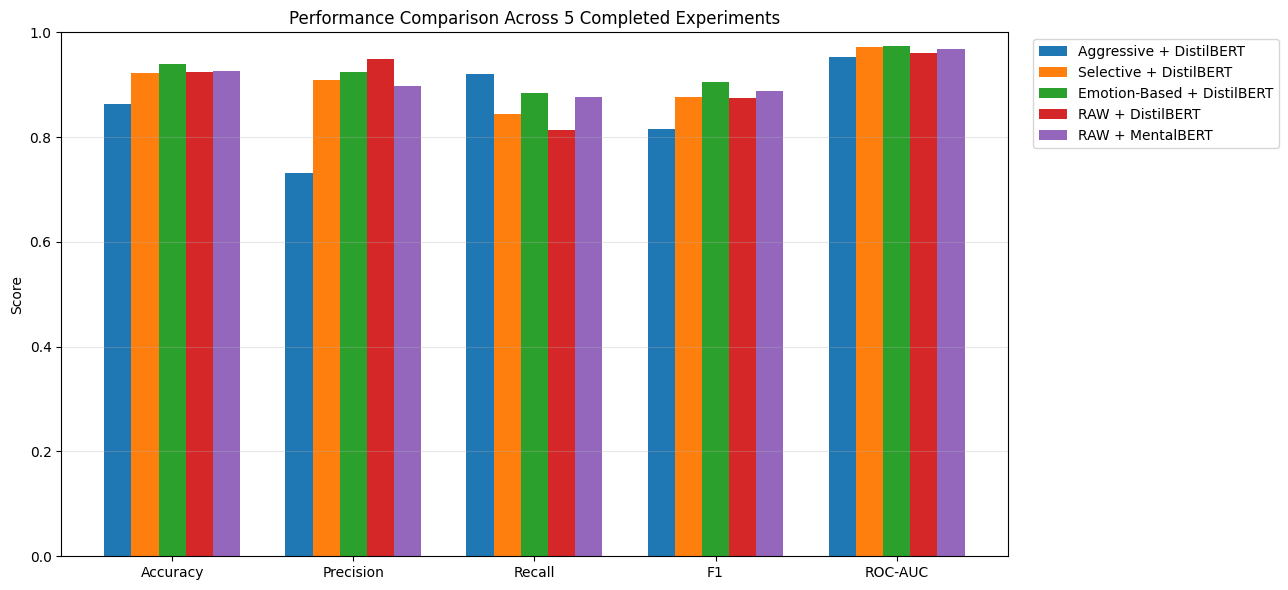

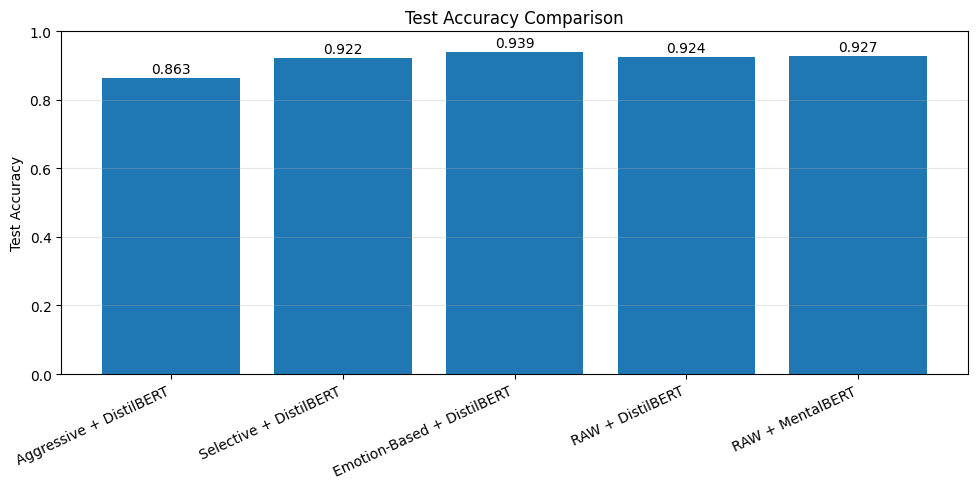

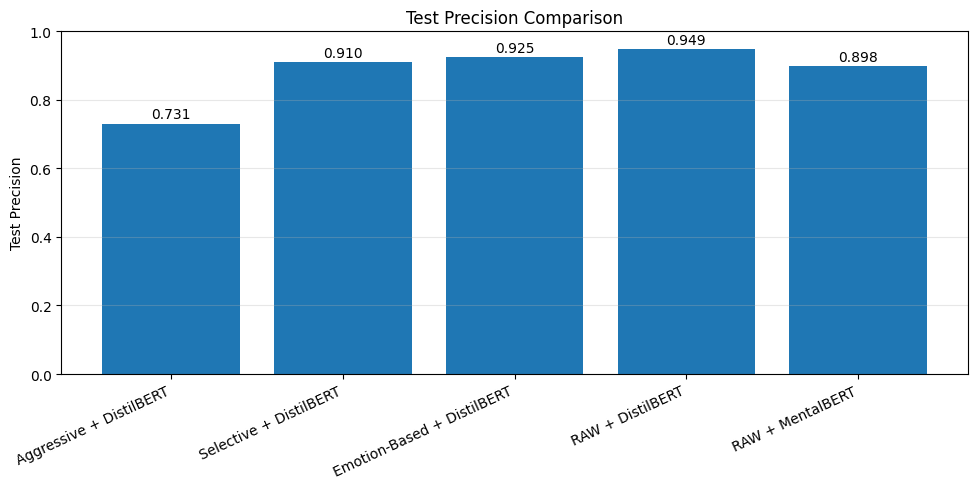

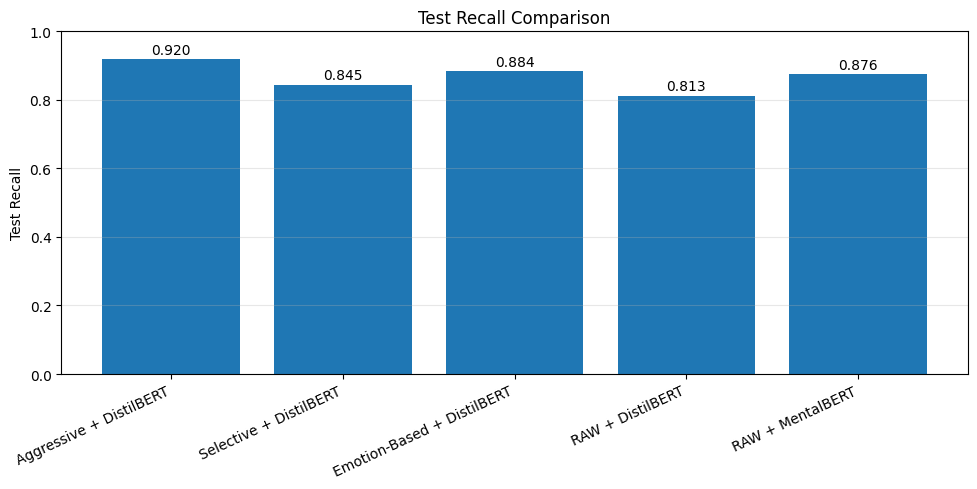

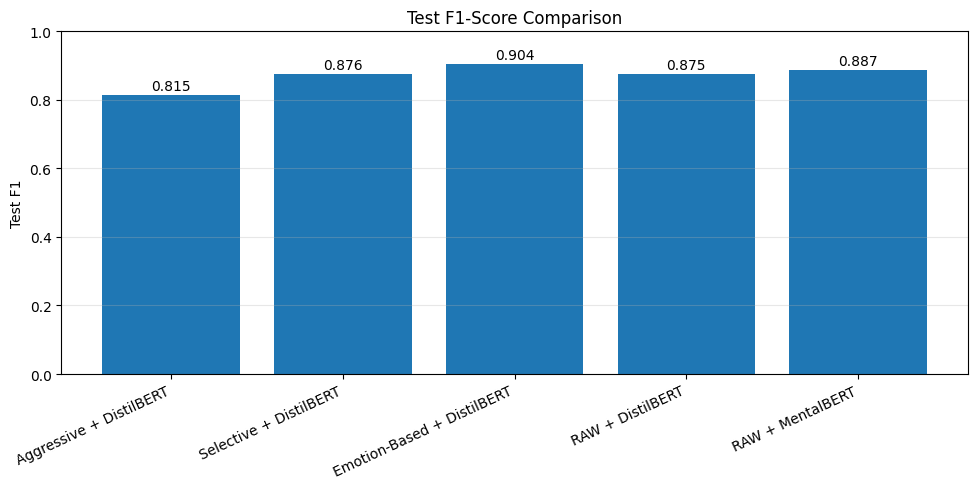

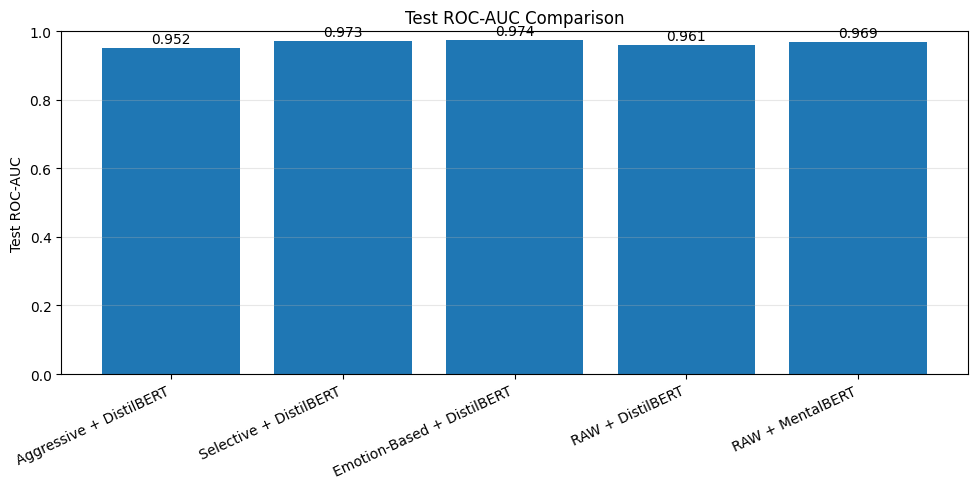

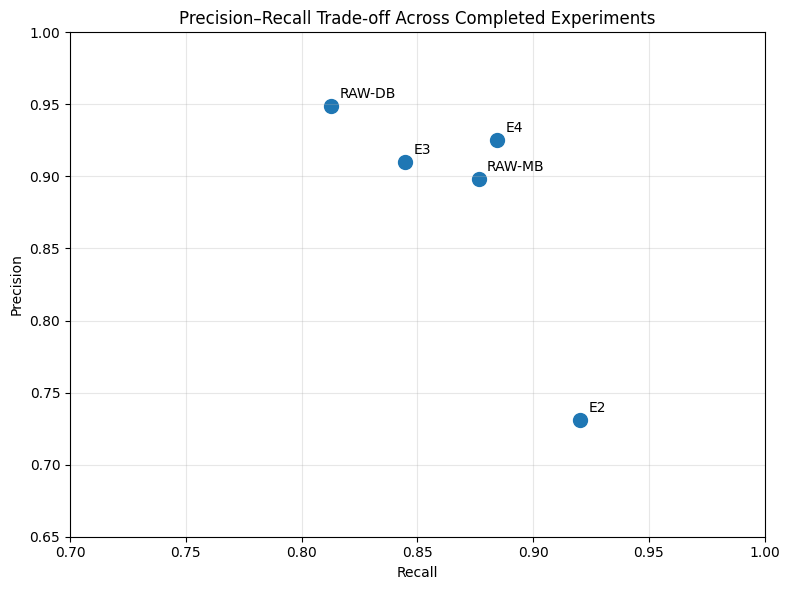

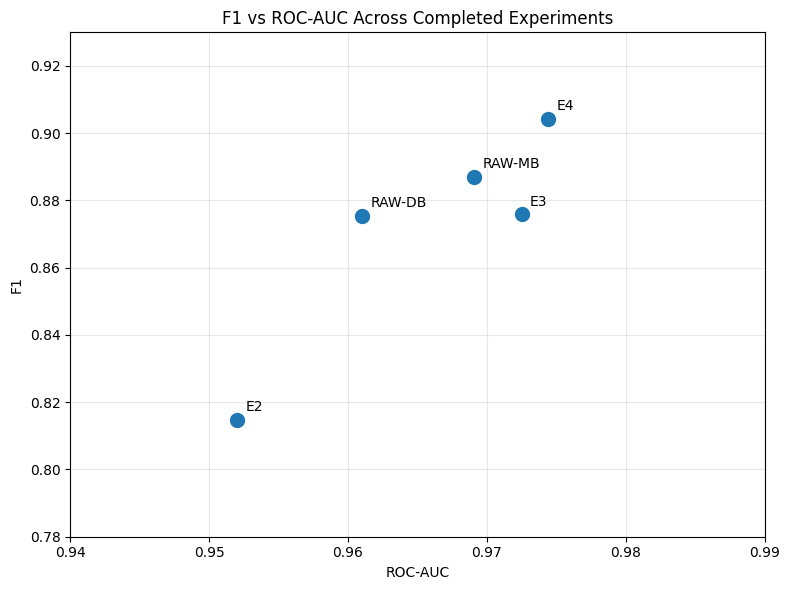

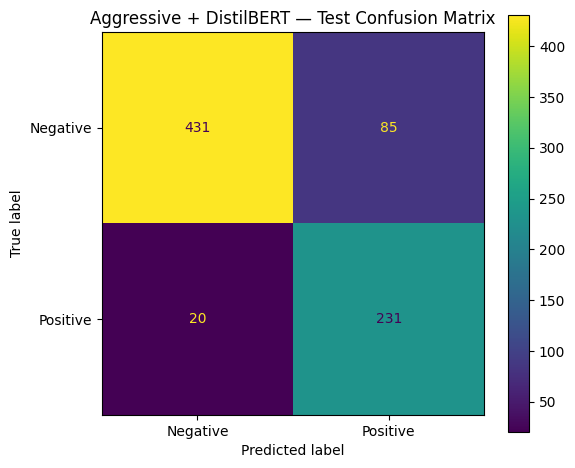

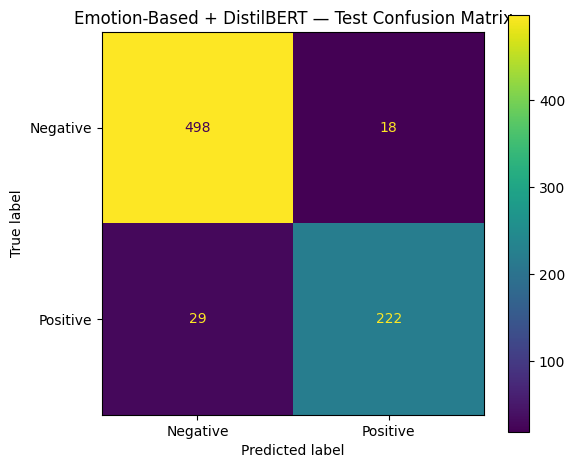

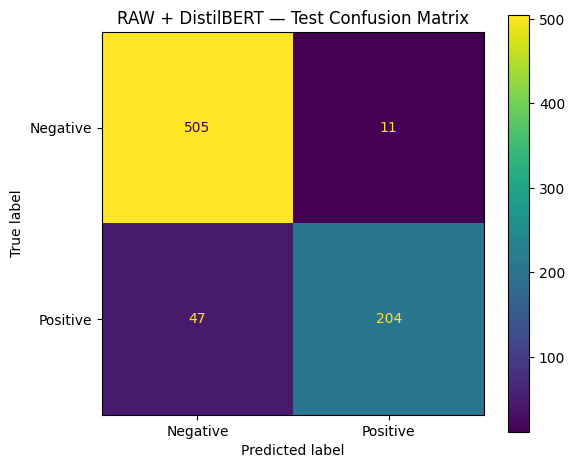

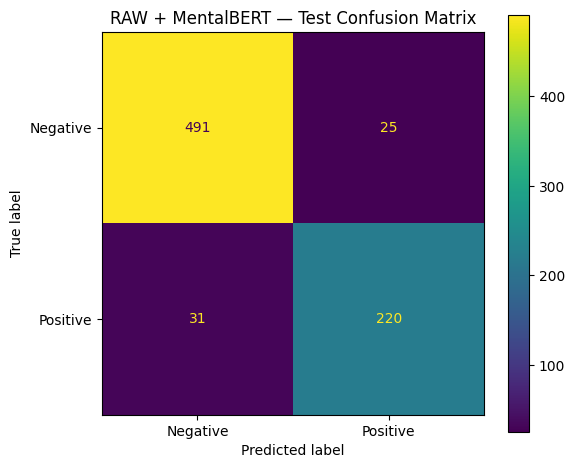

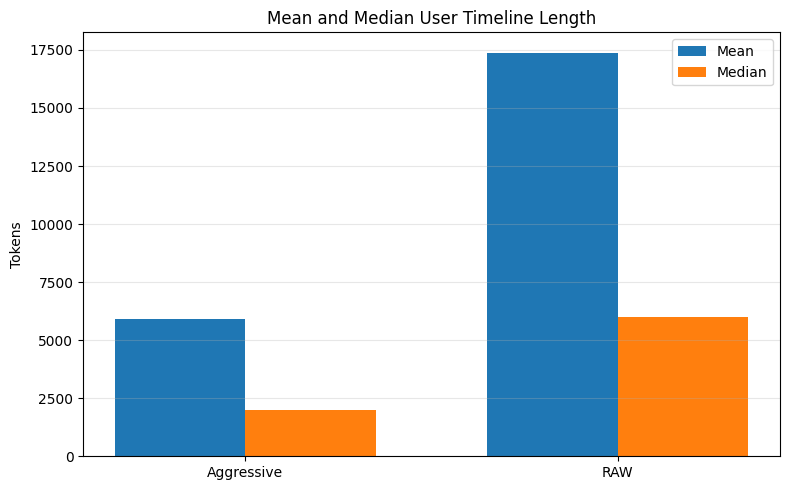

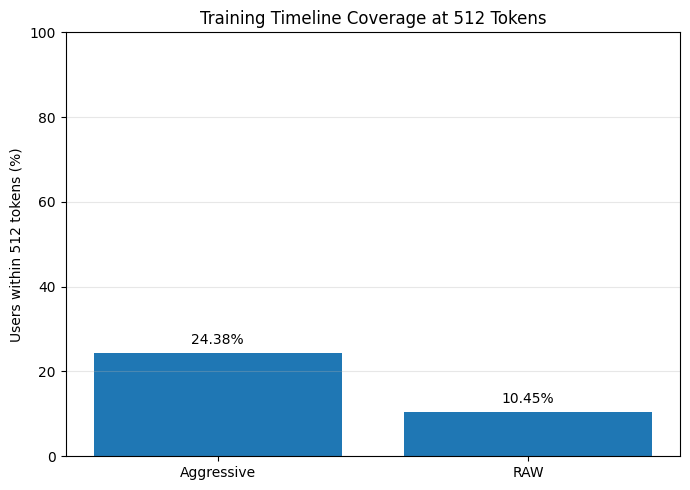

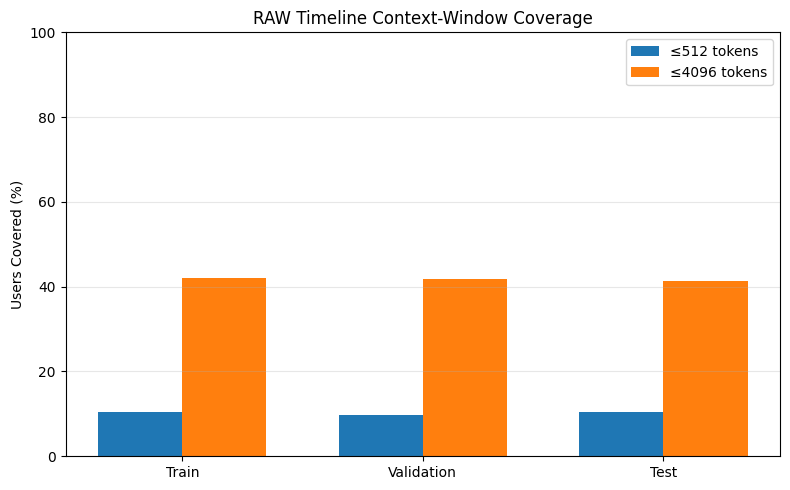

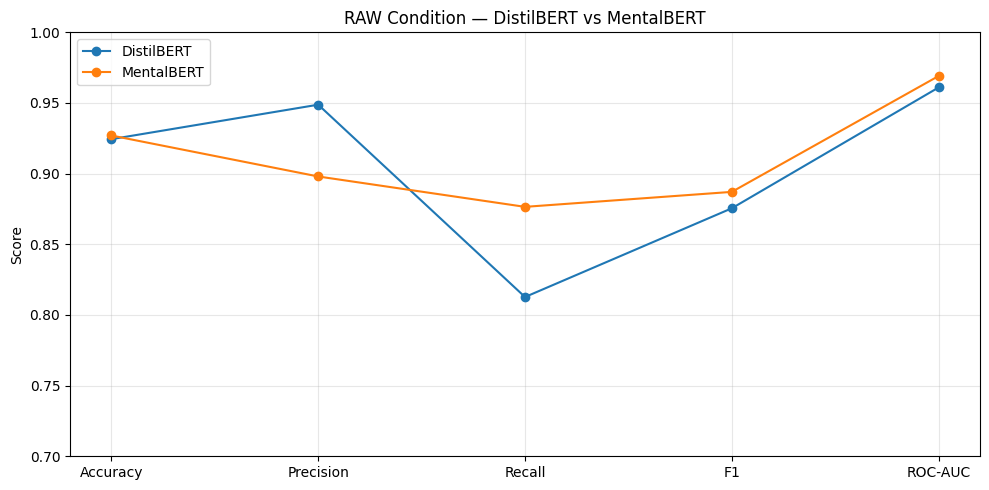


GRAPH PACKAGE COMPLETE
Graphs saved in: /kaggle/working/master_5_experiment_graphs
Total PNG figures: 16

✓ Overall metric comparison
✓ Accuracy
✓ Precision
✓ Recall
✓ F1
✓ ROC-AUC
✓ Precision–Recall trade-off
✓ F1 vs ROC-AUC
✓ 4 available confusion matrices
✓ RAW vs Aggressive token-length comparison
✓ 512-token coverage
✓ RAW 512 vs 4096 context coverage
✓ RAW DistilBERT vs MentalBERT
✓ All figures saved at 300 DPI


In [18]:
# ============================================================
# COMPLETE GRAPH PACKAGE — 5 COMPLETED EXPERIMENTS
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import ConfusionMatrixDisplay


# ============================================================
# OUTPUT DIRECTORY
# ============================================================

GRAPH_DIR = "/kaggle/working/master_5_experiment_graphs"

os.makedirs(
    GRAPH_DIR,
    exist_ok=True
)

print("=" * 70)
print("GENERATING GRAPH PACKAGE")
print("=" * 70)


# ============================================================
# MASTER RESULTS
# ============================================================

results = pd.DataFrame([

    {
        "Experiment": "E2",
        "Configuration": "Aggressive + DistilBERT",
        "Accuracy": 0.8631,
        "Precision": 0.7310,
        "Recall": 0.9203,
        "F1": 0.8148,
        "ROC-AUC": 0.9520
    },

    {
        "Experiment": "E3",
        "Configuration": "Selective + DistilBERT",
        "Accuracy": 0.9218,
        "Precision": 0.9099,
        "Recall": 0.8446,
        "F1": 0.8760,
        "ROC-AUC": 0.9725
    },

    {
        "Experiment": "E4",
        "Configuration": "Emotion-Based + DistilBERT",
        "Accuracy": 0.9387,
        "Precision": 0.9250,
        "Recall": 0.8845,
        "F1": 0.9043,
        "ROC-AUC": 0.9744
    },

    {
        "Experiment": "RAW-DB",
        "Configuration": "RAW + DistilBERT",
        "Accuracy": 0.9244,
        "Precision": 0.9488,
        "Recall": 0.8127,
        "F1": 0.8755,
        "ROC-AUC": 0.9610
    },

    {
        "Experiment": "RAW-MB",
        "Configuration": "RAW + MentalBERT",
        "Accuracy": 0.9270,
        "Precision": 0.8980,
        "Recall": 0.8765,
        "F1": 0.8871,
        "ROC-AUC": 0.9691
    }
])

print()
print(results.to_string(index=False))


# ============================================================
# GRAPH 1 — ALL METRICS COMPARISON
# ============================================================

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC"
]

x = np.arange(len(metrics))
width = 0.15

plt.figure(figsize=(13, 6))

for i in range(len(results)):

    values = [
        results.iloc[i][metric]
        for metric in metrics
    ]

    plt.bar(
        x + (i - 2) * width,
        values,
        width,
        label=results.iloc[i]["Configuration"]
    )

plt.xticks(
    x,
    metrics
)

plt.ylabel("Score")
plt.ylim(0, 1)

plt.title(
    "Performance Comparison Across 5 Completed Experiments"
)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "01_all_metrics_comparison.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 2 — ACCURACY
# ============================================================

plt.figure(figsize=(10, 5))

bars = plt.bar(
    results["Configuration"],
    results["Accuracy"]
)

plt.ylabel("Test Accuracy")
plt.ylim(0, 1)

plt.title(
    "Test Accuracy Comparison"
)

plt.xticks(
    rotation=25,
    ha="right"
)

plt.grid(
    axis="y",
    alpha=0.3
)

for bar, value in zip(
    bars,
    results["Accuracy"]
):

    plt.text(
        bar.get_x()
        + bar.get_width() / 2,
        value + 0.015,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "02_accuracy_comparison.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 3 — PRECISION
# ============================================================

plt.figure(figsize=(10, 5))

bars = plt.bar(
    results["Configuration"],
    results["Precision"]
)

plt.ylabel("Test Precision")
plt.ylim(0, 1)

plt.title(
    "Test Precision Comparison"
)

plt.xticks(
    rotation=25,
    ha="right"
)

plt.grid(
    axis="y",
    alpha=0.3
)

for bar, value in zip(
    bars,
    results["Precision"]
):

    plt.text(
        bar.get_x()
        + bar.get_width() / 2,
        value + 0.015,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "03_precision_comparison.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 4 — RECALL
# ============================================================

plt.figure(figsize=(10, 5))

bars = plt.bar(
    results["Configuration"],
    results["Recall"]
)

plt.ylabel("Test Recall")
plt.ylim(0, 1)

plt.title(
    "Test Recall Comparison"
)

plt.xticks(
    rotation=25,
    ha="right"
)

plt.grid(
    axis="y",
    alpha=0.3
)

for bar, value in zip(
    bars,
    results["Recall"]
):

    plt.text(
        bar.get_x()
        + bar.get_width() / 2,
        value + 0.015,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "04_recall_comparison.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 5 — F1 SCORE
# ============================================================

plt.figure(figsize=(10, 5))

bars = plt.bar(
    results["Configuration"],
    results["F1"]
)

plt.ylabel("Test F1")
plt.ylim(0, 1)

plt.title(
    "Test F1-Score Comparison"
)

plt.xticks(
    rotation=25,
    ha="right"
)

plt.grid(
    axis="y",
    alpha=0.3
)

for bar, value in zip(
    bars,
    results["F1"]
):

    plt.text(
        bar.get_x()
        + bar.get_width() / 2,
        value + 0.015,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "05_f1_comparison.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 6 — ROC-AUC
# ============================================================

plt.figure(figsize=(10, 5))

bars = plt.bar(
    results["Configuration"],
    results["ROC-AUC"]
)

plt.ylabel("Test ROC-AUC")
plt.ylim(0, 1)

plt.title(
    "Test ROC-AUC Comparison"
)

plt.xticks(
    rotation=25,
    ha="right"
)

plt.grid(
    axis="y",
    alpha=0.3
)

for bar, value in zip(
    bars,
    results["ROC-AUC"]
):

    plt.text(
        bar.get_x()
        + bar.get_width() / 2,
        value + 0.015,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "06_roc_auc_comparison.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 7 — PRECISION VS RECALL
# ============================================================

plt.figure(figsize=(8, 6))

plt.scatter(
    results["Recall"],
    results["Precision"],
    s=100
)

for _, row in results.iterrows():

    plt.annotate(
        row["Experiment"],
        (
            row["Recall"],
            row["Precision"]
        ),
        xytext=(6, 6),
        textcoords="offset points"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.xlim(0.7, 1.0)
plt.ylim(0.65, 1.0)

plt.title(
    "Precision–Recall Trade-off Across Completed Experiments"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "07_precision_recall_tradeoff.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 8 — F1 VS ROC-AUC
# ============================================================

plt.figure(figsize=(8, 6))

plt.scatter(
    results["ROC-AUC"],
    results["F1"],
    s=100
)

for _, row in results.iterrows():

    plt.annotate(
        row["Experiment"],
        (
            row["ROC-AUC"],
            row["F1"]
        ),
        xytext=(6, 6),
        textcoords="offset points"
    )

plt.xlabel("ROC-AUC")
plt.ylabel("F1")

plt.xlim(0.94, 0.99)
plt.ylim(0.78, 0.93)

plt.title(
    "F1 vs ROC-AUC Across Completed Experiments"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "08_f1_vs_roc_auc.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 9 — CONFUSION MATRIX: AGGRESSIVE
# ============================================================

cm_aggressive = np.array([
    [431, 85],
    [20, 231]
])

fig, ax = plt.subplots(figsize=(6, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_aggressive,
    display_labels=[
        "Negative",
        "Positive"
    ]
)

disp.plot(
    ax=ax,
    values_format="d"
)

ax.set_title(
    "Aggressive + DistilBERT — Test Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "09_cm_aggressive_distilbert.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 10 — CONFUSION MATRIX: EMOTION
# ============================================================

cm_emotion = np.array([
    [498, 18],
    [29, 222]
])

fig, ax = plt.subplots(figsize=(6, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_emotion,
    display_labels=[
        "Negative",
        "Positive"
    ]
)

disp.plot(
    ax=ax,
    values_format="d"
)

ax.set_title(
    "Emotion-Based + DistilBERT — Test Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "10_cm_emotion_distilbert.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 11 — CONFUSION MATRIX: RAW DISTILBERT
# ============================================================

cm_raw_db = np.array([
    [505, 11],
    [47, 204]
])

fig, ax = plt.subplots(figsize=(6, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_raw_db,
    display_labels=[
        "Negative",
        "Positive"
    ]
)

disp.plot(
    ax=ax,
    values_format="d"
)

ax.set_title(
    "RAW + DistilBERT — Test Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "11_cm_raw_distilbert.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 12 — CONFUSION MATRIX: RAW MENTALBERT
# ============================================================

cm_raw_mb = np.array([
    [491, 25],
    [31, 220]
])

fig, ax = plt.subplots(figsize=(6, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_raw_mb,
    display_labels=[
        "Negative",
        "Positive"
    ]
)

disp.plot(
    ax=ax,
    values_format="d"
)

ax.set_title(
    "RAW + MentalBERT — Test Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "12_cm_raw_mentalbert.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 13 — RAW vs AGGRESSIVE TOKEN LENGTH
# ============================================================

# Values obtained from the completed token-length analyses.

token_summary = pd.DataFrame({

    "Condition": [
        "Aggressive",
        "RAW"
    ],

    "Mean Tokens": [
        5891.59,
        17388.17
    ],

    "Median Tokens": [
        1983,
        5983
    ]
})

x = np.arange(
    len(token_summary)
)

width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    x - width / 2,
    token_summary["Mean Tokens"],
    width,
    label="Mean"
)

plt.bar(
    x + width / 2,
    token_summary["Median Tokens"],
    width,
    label="Median"
)

plt.xticks(
    x,
    token_summary["Condition"]
)

plt.ylabel("Tokens")
plt.title(
    "Mean and Median User Timeline Length"
)

plt.legend()
plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "13_raw_vs_aggressive_token_length.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 14 — 512-TOKEN COVERAGE
# ============================================================

coverage_512 = pd.DataFrame({

    "Condition": [
        "Aggressive",
        "RAW"
    ],

    "Train": [
        24.38,
        10.45
    ]
})

plt.figure(figsize=(7, 5))

bars = plt.bar(
    coverage_512["Condition"],
    coverage_512["Train"]
)

plt.ylabel(
    "Users within 512 tokens (%)"
)

plt.ylim(
    0,
    100
)

plt.title(
    "Training Timeline Coverage at 512 Tokens"
)

plt.grid(
    axis="y",
    alpha=0.3
)

for bar, value in zip(
    bars,
    coverage_512["Train"]
):

    plt.text(
        bar.get_x()
        + bar.get_width() / 2,
        value + 2,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "14_512_token_coverage.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 15 — RAW CONTEXT COVERAGE
# ============================================================

raw_context = pd.DataFrame({

    "Split": [
        "Train",
        "Validation",
        "Test"
    ],

    "512": [
        10.45,
        9.78,
        10.56
    ],

    "4096": [
        42.10,
        41.72,
        41.46
    ]
})

x = np.arange(
    len(raw_context)
)

width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    x - width / 2,
    raw_context["512"],
    width,
    label="≤512 tokens"
)

plt.bar(
    x + width / 2,
    raw_context["4096"],
    width,
    label="≤4096 tokens"
)

plt.xticks(
    x,
    raw_context["Split"]
)

plt.ylabel(
    "Users Covered (%)"
)

plt.ylim(
    0,
    100
)

plt.title(
    "RAW Timeline Context-Window Coverage"
)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "15_raw_context_window_coverage.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 16 — MODEL EFFECT: RAW DISTILBERT VS RAW MENTALBERT
# ============================================================

raw_model_df = pd.DataFrame({

    "Model": [
        "DistilBERT",
        "MentalBERT"
    ],

    "Accuracy": [
        0.9244,
        0.9270
    ],

    "Precision": [
        0.9488,
        0.8980
    ],

    "Recall": [
        0.8127,
        0.8765
    ],

    "F1": [
        0.8755,
        0.8871
    ],

    "ROC-AUC": [
        0.9610,
        0.9691
    ]
})

x = np.arange(5)

plt.figure(figsize=(10, 5))

for i, model in enumerate(
    raw_model_df["Model"]
):

    values = raw_model_df.iloc[
        i
    ][metrics].to_numpy()

    plt.plot(
        metrics,
        values,
        marker="o",
        label=model
    )

plt.ylabel("Score")
plt.ylim(0.7, 1.0)

plt.title(
    "RAW Condition — DistilBERT vs MentalBERT"
)

plt.legend()
plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "16_raw_model_comparison.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# SAVE MASTER GRAPH INDEX
# ============================================================

graph_index = pd.DataFrame({

    "Figure": [
        f"{i:02d}"
        for i in range(1, 17)
    ],

    "File": [
        filename
        for filename in sorted(
            os.listdir(GRAPH_DIR)
        )
        if filename.endswith(".png")
    ]
})

graph_index.to_csv(
    os.path.join(
        GRAPH_DIR,
        "graph_index.csv"
    ),
    index=False
)


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 70)
print("GRAPH PACKAGE COMPLETE")
print("=" * 70)

print(
    "Graphs saved in:",
    GRAPH_DIR
)

print(
    "Total PNG figures:",
    len([
        f
        for f in os.listdir(GRAPH_DIR)
        if f.endswith(".png")
    ])
)

print()
print("✓ Overall metric comparison")
print("✓ Accuracy")
print("✓ Precision")
print("✓ Recall")
print("✓ F1")
print("✓ ROC-AUC")
print("✓ Precision–Recall trade-off")
print("✓ F1 vs ROC-AUC")
print("✓ 4 available confusion matrices")
print("✓ RAW vs Aggressive token-length comparison")
print("✓ 512-token coverage")
print("✓ RAW 512 vs 4096 context coverage")
print("✓ RAW DistilBERT vs MentalBERT")
print("✓ All figures saved at 300 DPI")


In [19]:
print("=" * 120)
print("MENTALBERT RAW — FINAL RESULTS")
print("=" * 120)

print(f"{'Cleaning / Experiment':<25}"
      f"{'Training Accuracy':<20}"
      f"{'Validation Accuracy':<22}"
      f"{'Testing Accuracy':<20}"
      f"{'Precision':<15}"
      f"{'Recall':<15}"
      f"{'F1':<15}"
      f"{'ROC-AUC':<15}")

print("-" * 120)

print(f"{'RAW + MentalBERT':<25}"
      f"{0.9707*100:.2f}%{'':<13}"
      f"{0.9205*100:.2f}%{'':<15}"
      f"{0.9283:.4f}{'':<16}"
      f"{0.8740:.4f}{'':<11}"
      f"{0.9124:.4f}{'':<11}"
      f"{0.8928:.4f}{'':<11}"
      f"{0.9768:.4f}")

print("=" * 120)

MENTALBERT RAW — FINAL RESULTS
Cleaning / Experiment    Training Accuracy   Validation Accuracy   Testing Accuracy    Precision      Recall         F1             ROC-AUC        
------------------------------------------------------------------------------------------------------------------------
RAW + MentalBERT         97.07%             92.05%               0.9283                0.8740           0.9124           0.8928           0.9768


t-SNE REPRESENTATION ANALYSIS
MENTALBERT + RAW

Extracting fused model representations...
Processed batch 1/48
Processed batch 10/48
Processed batch 20/48
Processed batch 30/48
Processed batch 40/48
Processed batch 48/48

FUSED REPRESENTATION
Representation shape: (767, 832)
Number of test users: 767
Representation dimensions: 832
Negative users: 516
Positive users: 251

PCA REDUCTION
Original dimensions: 832
PCA dimensions: 50
Variance retained: 99.59%

t-SNE REDUCTION
t-SNE output shape: (767, 2)


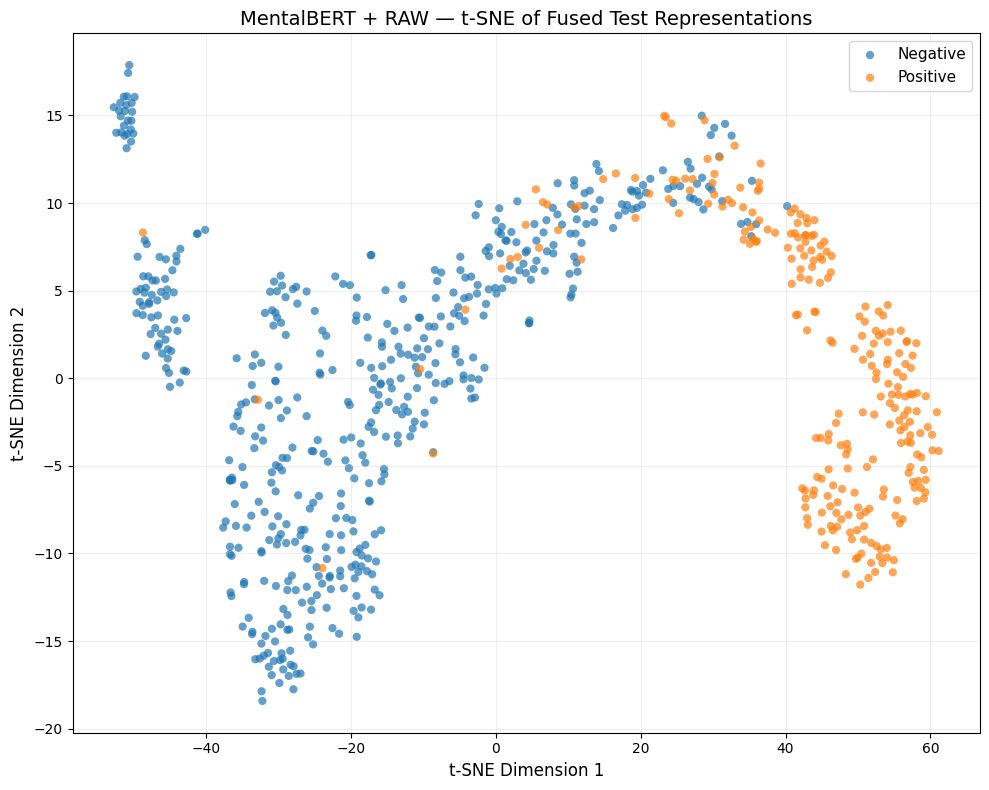


t-SNE ANALYSIS COMPLETE
✓ MentalBERT fused representation extracted
✓ Text representation = 768
✓ Metadata representation = 64
✓ Fusion = 832 dimensions
✓ Learned metadata gate used
✓ PCA reduction completed
✓ t-SNE reduction completed
✓ Coordinates saved:
/kaggle/working/mentalbert_raw_results/explainability/tsne/mentalbert_raw_tsne_coordinates.csv
✓ Graph saved:
/kaggle/working/mentalbert_raw_results/explainability/tsne/mentalbert_raw_tsne.png
✓ Graph displayed above
✓ Configuration saved


In [26]:
# ============================================================
# EXPLAINABILITY — CELL 1
# MENTALBERT + RAW
# t-SNE: FUSED REPRESENTATION → PCA → t-SNE
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

print("=" * 70)
print("t-SNE REPRESENTATION ANALYSIS")
print("MENTALBERT + RAW")
print("=" * 70)


# ============================================================
# FIXED EXPLAINABILITY SETTINGS
# ============================================================

EXPLAINABILITY_SEED = 42

PCA_COMPONENTS = 50

TSNE_COMPONENTS = 2
TSNE_PERPLEXITY = 30
TSNE_LEARNING_RATE = 200
TSNE_MAX_ITER = 1000

np.random.seed(
    EXPLAINABILITY_SEED
)

torch.manual_seed(
    EXPLAINABILITY_SEED
)


# ============================================================
# OUTPUT DIRECTORIES
# ============================================================

EXPLAINABILITY_DIR = os.path.join(
    MENTAL_RAW_RESULT_DIR,
    "explainability"
)

TSNE_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "tsne"
)

os.makedirs(
    TSNE_DIR,
    exist_ok=True
)


# ============================================================
# MODEL
# ============================================================

model_mental_raw.eval()


# ============================================================
# EXTRACT EXACT FUSED REPRESENTATIONS
# ============================================================

fused_representations = []
test_labels = []

print()
print("Extracting fused model representations...")

with torch.no_grad():

    for batch_idx, batch in enumerate(
        test_loader_mental_raw,
        start=1
    ):

        input_ids = batch[
            "input_ids"
        ].to(device)

        attention_mask = batch[
            "attention_mask"
        ].to(device)

        metadata = batch[
            "metadata"
        ].to(device)

        labels = batch[
            "labels"
        ].to(device)


        # ----------------------------------------------------
        # EXACT MENTALBERT MODEL OUTPUT
        # ----------------------------------------------------

        output = model_mental_raw(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )


        # ----------------------------------------------------
        # EXACT TEXT REPRESENTATION
        # ----------------------------------------------------

        text_representation = output[
            "text_representation"
        ]


        # ----------------------------------------------------
        # EXACT METADATA REPRESENTATION
        # ----------------------------------------------------

        metadata_representation = output[
            "metadata_representation"
        ]


        # ----------------------------------------------------
        # EXACT METADATA GATE
        # ----------------------------------------------------

        metadata_gate = output[
            "metadata_gate"
        ]

        gated_metadata = (
            metadata_gate
            * metadata_representation
        )


        # ----------------------------------------------------
        # EXACT MENTALBERT FUSION
        #
        # MentalBERT notebook uses:
        # 768 text + 64 gated metadata = 832
        # ----------------------------------------------------

        fused = torch.cat(
            [
                text_representation,
                gated_metadata
            ],
            dim=1
        )


        fused_representations.append(
            fused.cpu().numpy()
        )

        test_labels.extend(
            labels.cpu()
            .numpy()
            .tolist()
        )


        if (
            batch_idx == 1
            or batch_idx % 10 == 0
            or
            batch_idx ==
            len(
                test_loader_mental_raw
            )
        ):

            print(
                f"Processed batch "
                f"{batch_idx}/"
                f"{len(test_loader_mental_raw)}"
            )


# ============================================================
# COMBINE
# ============================================================

fused_representations = np.concatenate(
    fused_representations,
    axis=0
)

test_labels = np.array(
    test_labels
)


# ============================================================
# INTEGRITY
# ============================================================

print()
print("=" * 70)
print("FUSED REPRESENTATION")
print("=" * 70)

print(
    "Representation shape:",
    fused_representations.shape
)

print(
    "Number of test users:",
    len(test_labels)
)

print(
    "Representation dimensions:",
    fused_representations.shape[1]
)

print(
    "Negative users:",
    int(
        (test_labels == 0).sum()
    )
)

print(
    "Positive users:",
    int(
        (test_labels == 1).sum()
    )
)

assert (
    fused_representations.shape[0]
    ==
    len(test_labels)
)

assert (
    fused_representations.shape[1]
    ==
    832
)

assert np.isfinite(
    fused_representations
).all()


# ============================================================
# PCA
# ============================================================

print()
print("=" * 70)
print("PCA REDUCTION")
print("=" * 70)

pca_dimensions = min(
    PCA_COMPONENTS,
    fused_representations.shape[1]
)

pca = PCA(
    n_components=pca_dimensions,
    random_state=EXPLAINABILITY_SEED
)

pca_representation = pca.fit_transform(
    fused_representations
)

explained_variance = (
    pca.explained_variance_ratio_.sum()
)

print(
    "Original dimensions:",
    fused_representations.shape[1]
)

print(
    "PCA dimensions:",
    pca_representation.shape[1]
)

print(
    "Variance retained:",
    f"{explained_variance * 100:.2f}%"
)


# ============================================================
# t-SNE
# ============================================================

print()
print("=" * 70)
print("t-SNE REDUCTION")
print("=" * 70)

tsne = TSNE(
    n_components=TSNE_COMPONENTS,
    perplexity=TSNE_PERPLEXITY,
    learning_rate=TSNE_LEARNING_RATE,
    init="pca",
    random_state=EXPLAINABILITY_SEED,
    max_iter=TSNE_MAX_ITER
)

tsne_representation = tsne.fit_transform(
    pca_representation
)

print(
    "t-SNE output shape:",
    tsne_representation.shape
)


# ============================================================
# SAVE COORDINATES
# ============================================================

tsne_df = pd.DataFrame({

    "tsne_1":
        tsne_representation[:, 0],

    "tsne_2":
        tsne_representation[:, 1],

    "label":
        test_labels

})

tsne_df["class"] = tsne_df[
    "label"
].map({
    0: "Negative",
    1: "Positive"
})


tsne_csv_path = os.path.join(
    TSNE_DIR,
    "mentalbert_raw_tsne_coordinates.csv"
)

tsne_df.to_csv(
    tsne_csv_path,
    index=False
)


# ============================================================
# PUBLICATION-QUALITY PLOT
# ============================================================

plt.figure(
    figsize=(10, 8)
)

negative_mask = (
    test_labels == 0
)

positive_mask = (
    test_labels == 1
)


plt.scatter(
    tsne_representation[
        negative_mask,
        0
    ],
    tsne_representation[
        negative_mask,
        1
    ],
    s=35,
    alpha=0.70,
    label="Negative",
    edgecolors="none"
)


plt.scatter(
    tsne_representation[
        positive_mask,
        0
    ],
    tsne_representation[
        positive_mask,
        1
    ],
    s=35,
    alpha=0.70,
    label="Positive",
    edgecolors="none"
)


plt.xlabel(
    "t-SNE Dimension 1",
    fontsize=12
)

plt.ylabel(
    "t-SNE Dimension 2",
    fontsize=12
)

plt.title(
    "MentalBERT + RAW — "
    "t-SNE of Fused Test Representations",
    fontsize=14
)

plt.legend(
    fontsize=11
)

plt.grid(
    alpha=0.20
)

plt.tight_layout()


tsne_plot_path = os.path.join(
    TSNE_DIR,
    "mentalbert_raw_tsne.png"
)


# SAVE
plt.savefig(
    tsne_plot_path,
    dpi=300,
    bbox_inches="tight"
)


# DISPLAY
plt.show()

plt.close()


# ============================================================
# SAVE CONFIGURATION
# ============================================================

metadata_gate_final = float(
    torch.sigmoid(
        model_mental_raw.metadata_beta
    )
    .detach()
    .cpu()
)

tsne_config = {

    "model":
        "MentalBERT",

    "model_name":
        MENTALBERT_MODEL_NAME,

    "cleaning":
        "RAW",

    "dataset":
        "Held-out test set",

    "test_users":
        int(
            len(test_labels)
        ),

    "input_representation":
        "Fused classifier representation",

    "text_representation_dimension":
        int(
            text_representation.shape[1]
        ),

    "metadata_representation_dimension":
        int(
            metadata_representation.shape[1]
        ),

    "fused_representation_dimension":
        int(
            fused_representations.shape[1]
        ),

    "fusion":
        "768 + 64 = 832",

    "metadata_gate":
        metadata_gate_final,

    "pca_dimensions":
        int(
            pca_dimensions
        ),

    "pca_variance_retained":
        float(
            explained_variance
        ),

    "tsne_dimensions":
        int(
            TSNE_COMPONENTS
        ),

    "tsne_perplexity":
        int(
            TSNE_PERPLEXITY
        ),

    "tsne_learning_rate":
        TSNE_LEARNING_RATE,

    "tsne_max_iterations":
        int(
            TSNE_MAX_ITER
        ),

    "random_seed":
        EXPLAINABILITY_SEED
}


with open(
    os.path.join(
        TSNE_DIR,
        "mentalbert_raw_tsne_config.json"
    ),
    "w"
) as f:

    json.dump(
        tsne_config,
        f,
        indent=2
    )


# ============================================================
# FINAL OUTPUT
# ============================================================

print()
print("=" * 70)
print("t-SNE ANALYSIS COMPLETE")
print("=" * 70)

print(
    "✓ MentalBERT fused representation extracted"
)

print(
    "✓ Text representation = 768"
)

print(
    "✓ Metadata representation = 64"
)

print(
    "✓ Fusion = 832 dimensions"
)

print(
    "✓ Learned metadata gate used"
)

print(
    "✓ PCA reduction completed"
)

print(
    "✓ t-SNE reduction completed"
)

print(
    "✓ Coordinates saved:"
)

print(
    tsne_csv_path
)

print(
    "✓ Graph saved:"
)

print(
    tsne_plot_path
)

print(
    "✓ Graph displayed above"
)

print(
    "✓ Configuration saved"
)

GRAD-CAM EXPLAINABILITY
MENTALBERT + RAW

CUDA memory cleared before Grad-CAM

CALCULATING TEST PREDICTIONS
Processed 1/767
Processed 100/767
Processed 200/767
Processed 300/767
Processed 400/767
Processed 500/767
Processed 600/767
Processed 700/767
Processed 767/767

TEST PREDICTIONS READY
Test samples : 767

SELECTED CASES
TP : test index 1 | true=1 | pred=1 | probability=0.9697
TN : test index 0 | true=0 | pred=0 | probability=0.0141
FP : test index 27 | true=0 | pred=1 | probability=0.9950
FN : test index 45 | true=1 | pred=0 | probability=0.0252

PROCESSING TP
Test index : 1
Target class : 1
Raw Grad-CAM: min = -0.0006327004521153867 max = 0.004859217442572117


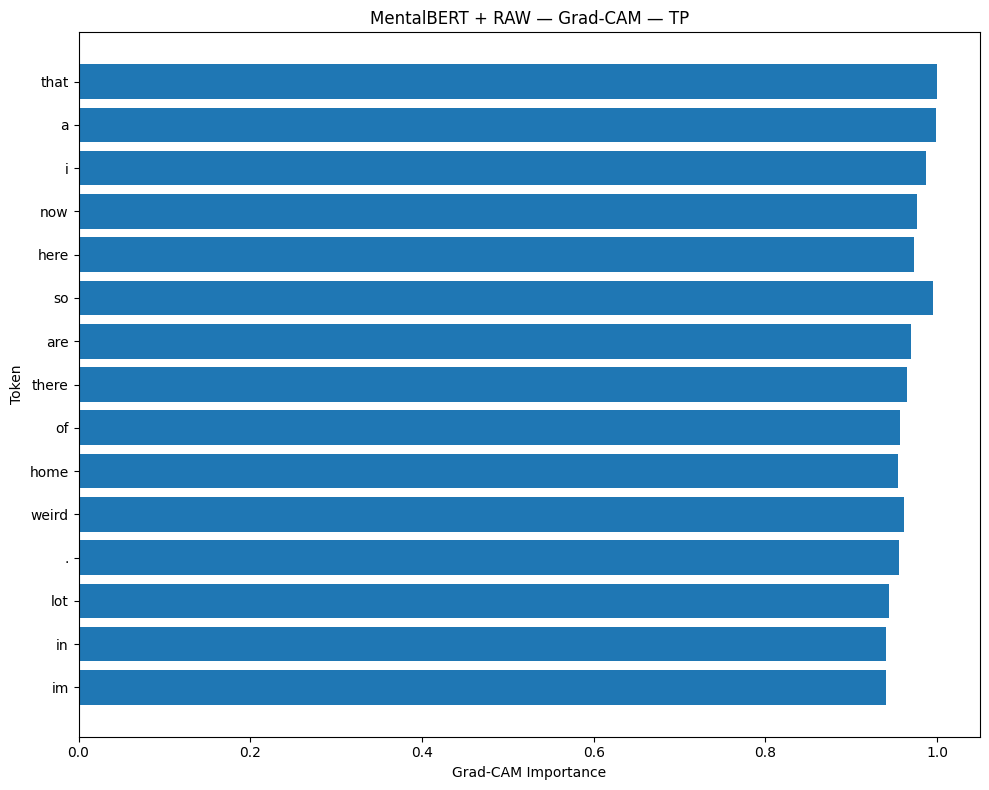

Saved: /kaggle/working/mentalbert_raw_results/explainability/gradcam/mentalbert_raw_gradcam_tp_tokens.csv

PROCESSING TN
Test index : 0
Target class : 0
Raw Grad-CAM: min = 0.0026506478898227215 max = 0.004460166208446026


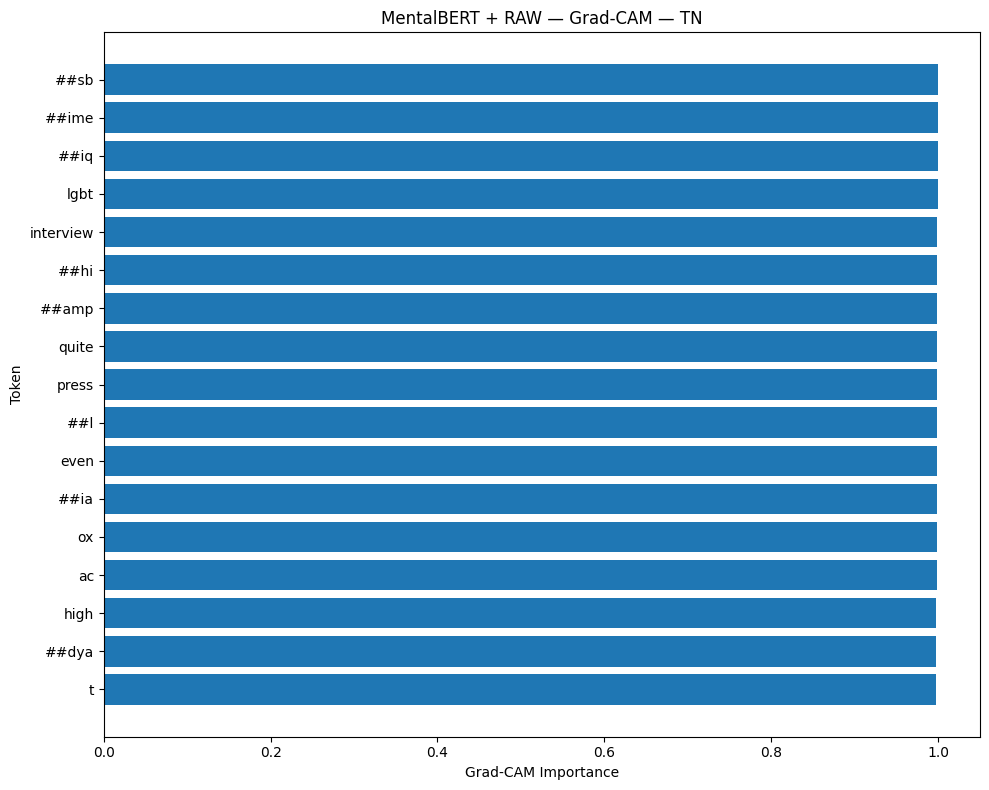

Saved: /kaggle/working/mentalbert_raw_results/explainability/gradcam/mentalbert_raw_gradcam_tn_tokens.csv

PROCESSING FP
Test index : 27
Target class : 1
Raw Grad-CAM: min = 0.002992988098412752 max = 0.0050781769677996635


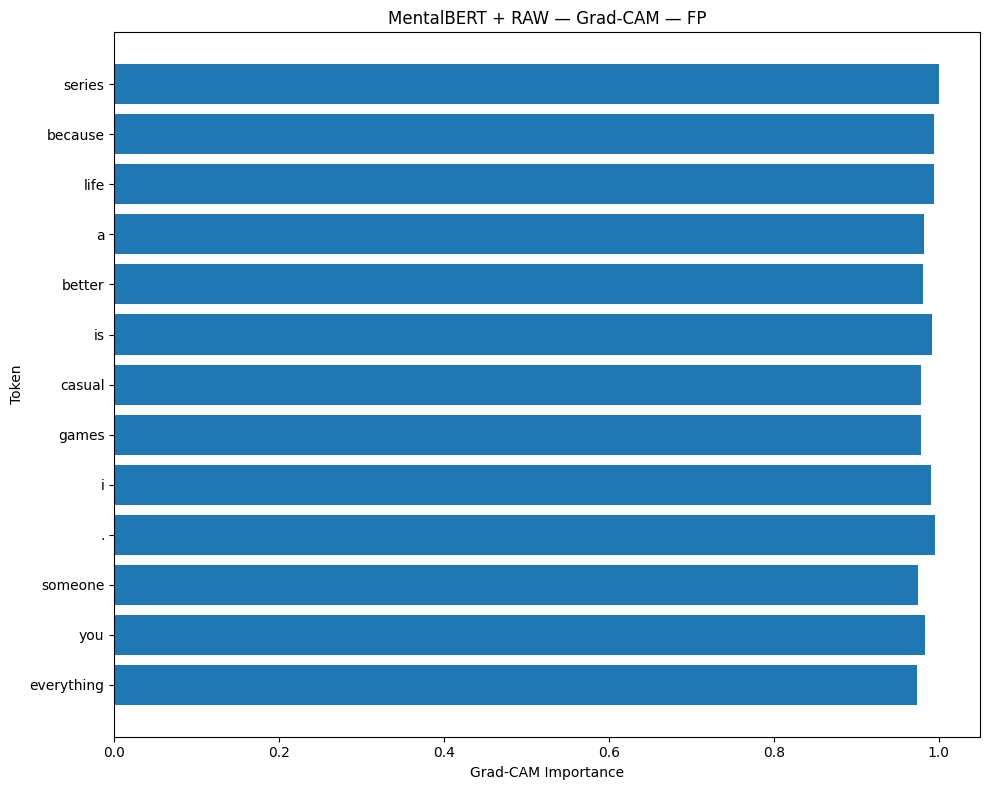

Saved: /kaggle/working/mentalbert_raw_results/explainability/gradcam/mentalbert_raw_gradcam_fp_tokens.csv

PROCESSING FN
Test index : 45
Target class : 0
Raw Grad-CAM: min = 0.0015062510501593351 max = 0.004238320514559746


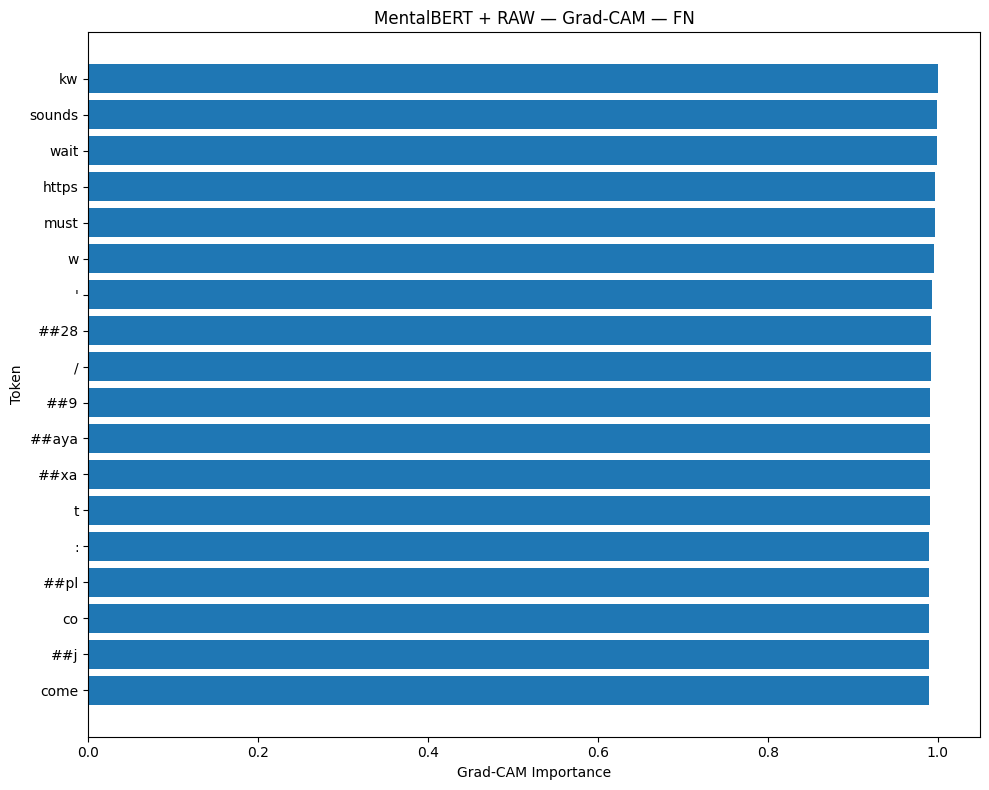

Saved: /kaggle/working/mentalbert_raw_results/explainability/gradcam/mentalbert_raw_gradcam_fn_tokens.csv

GRAD-CAM COMPLETE
Output directory:
/kaggle/working/mentalbert_raw_results/explainability/gradcam
Configuration saved:
/kaggle/working/mentalbert_raw_results/explainability/gradcam/mentalbert_raw_gradcam_config.json
Cases processed: ['TP', 'TN', 'FP', 'FN']
✓ Memory-safe test prediction
✓ TP explained using Positive class
✓ TN explained using Negative class
✓ FP explained using Positive class
✓ FN explained using Negative class
✓ CUDA memory cleaned


In [31]:
# ============================================================
# EXPLAINABILITY — CELL 2
# MENTALBERT + RAW
# GRAD-CAM: TOKEN-LEVEL LOCAL EXPLANATION
# MEMORY-SAFE VERSION
# ============================================================

import os
import json
import gc
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt


print("=" * 70)
print("GRAD-CAM EXPLAINABILITY")
print("MENTALBERT + RAW")
print("=" * 70)


# ============================================================
# CUDA MEMORY CLEANUP
# ============================================================

gc.collect()

if torch.cuda.is_available():

    torch.cuda.empty_cache()

    torch.cuda.ipc_collect()


print()
print("CUDA memory cleared before Grad-CAM")


# ============================================================
# FIXED GRAD-CAM SETTINGS
# ============================================================

GRADCAM_SEED = 42
GRADCAM_TOP_TOKENS = 20

np.random.seed(
    GRADCAM_SEED
)

torch.manual_seed(
    GRADCAM_SEED
)


# ============================================================
# OUTPUT DIRECTORIES
# ============================================================

EXPLAINABILITY_DIR = os.path.join(
    MENTAL_RAW_RESULT_DIR,
    "explainability"
)


GRADCAM_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "gradcam"
)


os.makedirs(
    GRADCAM_DIR,
    exist_ok=True
)


# ============================================================
# MODEL
# ============================================================

model_mental_raw.eval()


# Freeze model parameters
for parameter in model_mental_raw.parameters():

    parameter.requires_grad = False


# Clear any old gradients
model_mental_raw.zero_grad(
    set_to_none=True
)


# ============================================================
# STEP 1 — CALCULATE TEST PREDICTIONS
# MEMORY-SAFE:
# ONE TEST USER AT A TIME
# ============================================================

labels_np = []
preds_np = []
probs_np = []


print()
print("=" * 70)
print("CALCULATING TEST PREDICTIONS")
print("=" * 70)


num_test_samples = len(
    test_dataset_mental_raw
)


for test_index in range(
    num_test_samples
):

    sample = test_dataset_mental_raw[
        test_index
    ]


    input_ids = (
        sample[
            "input_ids"
        ]
        .unsqueeze(0)
        .to(device)
    )


    attention_mask = (
        sample[
            "attention_mask"
        ]
        .unsqueeze(0)
        .to(device)
    )


    metadata = (
        sample[
            "metadata"
        ]
        .unsqueeze(0)
        .to(device)
    )


    # --------------------------------------------------------
    # INFERENCE ONLY
    # --------------------------------------------------------

    with torch.inference_mode():

        output = model_mental_raw(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )


        logits = output[
            "logits"
        ]


        probabilities = torch.softmax(
            logits,
            dim=1
        )


        prediction = torch.argmax(
            logits,
            dim=1
        )


        labels_np.append(
            int(
                sample[
                    "labels"
                ].item()
            )
        )


        preds_np.append(
            int(
                prediction.item()
            )
        )


        probs_np.append(
            float(
                probabilities[
                    0,
                    1
                ].item()
            )
        )


    # --------------------------------------------------------
    # DELETE GPU TENSORS IMMEDIATELY
    # --------------------------------------------------------

    del (
        input_ids,
        attention_mask,
        metadata,
        output,
        logits,
        probabilities,
        prediction
    )


    # --------------------------------------------------------
    # PERIODIC CUDA CLEANUP
    # --------------------------------------------------------

    if (
        test_index % 25 == 0
    ):

        gc.collect()

        if torch.cuda.is_available():

            torch.cuda.empty_cache()


    if (
        test_index == 0
        or
        (test_index + 1) % 100 == 0
        or
        test_index == num_test_samples - 1
    ):

        print(
            f"Processed "
            f"{test_index + 1}/"
            f"{num_test_samples}"
        )


labels_np = np.array(
    labels_np
)


preds_np = np.array(
    preds_np
)


probs_np = np.array(
    probs_np
)


print()
print("=" * 70)
print("TEST PREDICTIONS READY")
print(
    f"Test samples : {len(labels_np)}"
)
print("=" * 70)


# ============================================================
# STEP 2 — SELECT TP / TN / FP / FN CASES
# ============================================================

selected_cases = {}


tp_candidates = np.where(
    (labels_np == 1) &
    (preds_np == 1)
)[0]


tn_candidates = np.where(
    (labels_np == 0) &
    (preds_np == 0)
)[0]


fp_candidates = np.where(
    (labels_np == 0) &
    (preds_np == 1)
)[0]


fn_candidates = np.where(
    (labels_np == 1) &
    (preds_np == 0)
)[0]


if len(
    tp_candidates
) > 0:

    selected_cases[
        "TP"
    ] = int(
        tp_candidates[0]
    )


if len(
    tn_candidates
) > 0:

    selected_cases[
        "TN"
    ] = int(
        tn_candidates[0]
    )


if len(
    fp_candidates
) > 0:

    selected_cases[
        "FP"
    ] = int(
        fp_candidates[0]
    )


if len(
    fn_candidates
) > 0:

    selected_cases[
        "FN"
    ] = int(
        fn_candidates[0]
    )


print()
print("=" * 70)
print("SELECTED CASES")
print("=" * 70)


for case_type, test_index in selected_cases.items():

    print(
        f"{case_type} : "
        f"test index {test_index} | "
        f"true={labels_np[test_index]} | "
        f"pred={preds_np[test_index]} | "
        f"probability={probs_np[test_index]:.4f}"
    )


# ============================================================
# STEP 3 — GRAD-CAM COMPUTATION
# ============================================================

def compute_mentalbert_raw_gradcam(
    test_index
):

    # --------------------------------------------------------
    # CLEAR MEMORY BEFORE EACH GRAD-CAM CASE
    # --------------------------------------------------------

    gc.collect()

    if torch.cuda.is_available():

        torch.cuda.empty_cache()


    sample = test_dataset_mental_raw[
        test_index
    ]


    input_ids = (
        sample[
            "input_ids"
        ]
        .unsqueeze(0)
        .to(device)
    )


    attention_mask = (
        sample[
            "attention_mask"
        ]
        .unsqueeze(0)
        .to(device)
    )


    metadata = (
        sample[
            "metadata"
        ]
        .unsqueeze(0)
        .to(device)
    )


    # --------------------------------------------------------
    # TARGET CLASS
    #
    # TP -> predicted class 1
    # TN -> predicted class 0
    # FP -> predicted class 1
    # FN -> predicted class 0
    # --------------------------------------------------------

    target_class = int(
        preds_np[
            test_index
        ]
    )


    # --------------------------------------------------------
    # CLEAR PREVIOUS GRADIENTS
    # --------------------------------------------------------

    model_mental_raw.zero_grad(
        set_to_none=True
    )


    # --------------------------------------------------------
    # MENTALBERT ENCODER
    #
    # Encoder is executed WITHOUT gradient graph.
    # We only need gradients from classifier output
    # back to the detached token representations.
    # This greatly reduces GPU memory.
    # --------------------------------------------------------

    with torch.no_grad():

        mentalbert_output = (
            model_mental_raw.mentalbert(
                input_ids=input_ids,
                attention_mask=attention_mask
            )
        )


    hidden_states = (
        mentalbert_output
        .last_hidden_state
        .detach()
    )


    del mentalbert_output


    hidden_states.requires_grad_(
        True
    )


    hidden_states.retain_grad()


    # --------------------------------------------------------
    # ATTENTION POOLING
    # --------------------------------------------------------

    attention_features = (
        model_mental_raw.attention_projection(
            hidden_states
        )
    )


    attention_scores = (
        model_mental_raw.attention_score(
            torch.tanh(
                attention_features
            )
        )
        .squeeze(-1)
    )


    attention_scores = (
        attention_scores.float()
    )


    attention_scores = (
        attention_scores.masked_fill(
            attention_mask == 0,
            torch.finfo(
                attention_scores.dtype
            ).min
        )
    )


    attention_weights = torch.softmax(
        attention_scores,
        dim=1
    )


    text_representation = (
        torch.sum(
            hidden_states
            * attention_weights.unsqueeze(-1),
            dim=1
        )
    )


    # --------------------------------------------------------
    # METADATA BRANCH
    # --------------------------------------------------------

    metadata_representation = (
        model_mental_raw.metadata_branch(
            metadata
        )
    )


    # --------------------------------------------------------
    # METADATA GATE
    # --------------------------------------------------------

    metadata_gate = torch.sigmoid(
        model_mental_raw.metadata_beta
    )


    gated_metadata = (
        metadata_gate
        * metadata_representation
    )


    # --------------------------------------------------------
    # FUSION
    # --------------------------------------------------------

    fused = torch.cat(
        [
            text_representation,
            gated_metadata
        ],
        dim=1
    )


    # --------------------------------------------------------
    # CLASSIFIER
    # --------------------------------------------------------

    logits = model_mental_raw.classifier(
        fused
    )


    # --------------------------------------------------------
    # TARGET LOGIT
    # --------------------------------------------------------

    target_logit = logits[
        :,
        target_class
    ]


    # --------------------------------------------------------
    # BACKWARD
    # --------------------------------------------------------

    target_logit.backward()


    gradients = (
        hidden_states.grad
    )


    # --------------------------------------------------------
    # GRAD-CAM
    # --------------------------------------------------------

    channel_weights = (
        gradients.mean(
            dim=1,
            keepdim=True
        )
    )


    raw_gradcam = (
        channel_weights
        * hidden_states
    ).sum(
        dim=-1
    )


    # --------------------------------------------------------
    # DIAGNOSTIC
    # --------------------------------------------------------

    raw_min = float(
        raw_gradcam.min()
        .detach()
        .cpu()
    )


    raw_max = float(
        raw_gradcam.max()
        .detach()
        .cpu()
    )


    print(
        f"Target class : {target_class}"
    )


    print(
        "Raw Grad-CAM:",
        "min =",
        raw_min,
        "max =",
        raw_max
    )


    # --------------------------------------------------------
    # POSITIVE GRAD-CAM
    # --------------------------------------------------------

    gradcam = torch.relu(
        raw_gradcam
    )


    # --------------------------------------------------------
    # SQUEEZE
    # --------------------------------------------------------

    gradcam = (
        gradcam
        .squeeze(0)
    )


    attention_weights = (
        attention_weights
        .squeeze(0)
    )


    valid_mask = (
        attention_mask
        .squeeze(0)
    )


    # --------------------------------------------------------
    # MOVE TO CPU
    # --------------------------------------------------------

    gradcam = (
        gradcam
        .detach()
        .cpu()
        .numpy()
    )


    attention_weights = (
        attention_weights
        .detach()
        .cpu()
        .numpy()
    )


    valid_mask = (
        valid_mask
        .detach()
        .cpu()
        .numpy()
    )


    # --------------------------------------------------------
    # REMOVE PADDING
    # --------------------------------------------------------

    gradcam = (
        gradcam
        * valid_mask
    )


    # --------------------------------------------------------
    # NORMALIZE POSITIVE ACTIVATIONS
    # --------------------------------------------------------

    if gradcam.max() > 0:

        gradcam = (
            gradcam
            /
            gradcam.max()
        )


    # --------------------------------------------------------
    # FALLBACK
    #
    # If all positive activations are zero,
    # use magnitude of raw Grad-CAM for visualization.
    # --------------------------------------------------------

    if gradcam.max() == 0:

        raw_gradcam_np = np.abs(
            raw_gradcam
            .squeeze(0)
            .detach()
            .cpu()
            .numpy()
        )


        raw_gradcam_np = (
            raw_gradcam_np
            * valid_mask
        )


        if raw_gradcam_np.max() > 0:

            gradcam = (
                raw_gradcam_np
                /
                raw_gradcam_np.max()
            )


    # --------------------------------------------------------
    # SAVE RESULTS BEFORE CLEANUP
    # --------------------------------------------------------

    result = {

        "gradcam":
            gradcam,

        "attention_weights":
            attention_weights,

        "input_ids":
            sample[
                "input_ids"
            ]
            .cpu()
            .numpy(),

        "attention_mask":
            sample[
                "attention_mask"
            ]
            .cpu()
            .numpy(),

        "true_label":
            int(
                labels_np[
                    test_index
                ]
            ),

        "predicted_label":
            int(
                preds_np[
                    test_index
                ]
            ),

        "target_class":
            target_class,

        "positive_probability":
            float(
                probs_np[
                    test_index
                ]
            )
    }


    # --------------------------------------------------------
    # DELETE GPU TENSORS
    # --------------------------------------------------------

    del (
        input_ids,
        attention_mask,
        metadata,
        hidden_states,
        attention_features,
        attention_scores,
        attention_weights,
        text_representation,
        metadata_representation,
        metadata_gate,
        gated_metadata,
        fused,
        logits,
        target_logit,
        gradients,
        channel_weights,
        raw_gradcam
    )


    gc.collect()

    if torch.cuda.is_available():

        torch.cuda.empty_cache()


    return result


# ============================================================
# STEP 4 — TOKEN INFORMATION
# ============================================================

def get_token_information(
    input_ids,
    attention_mask,
    gradcam,
    tokenizer,
    top_tokens=20
):

    token_ids = input_ids[
        attention_mask.astype(bool)
    ]


    importance = gradcam[
        attention_mask.astype(bool)
    ]


    tokens = tokenizer.convert_ids_to_tokens(
        token_ids.tolist()
    )


    token_information = []


    for token, score in zip(
        tokens,
        importance
    ):

        if token in tokenizer.all_special_tokens:

            continue


        token_information.append(
            {
                "token":
                    token,

                "importance":
                    float(score)
            }
        )


    token_information = sorted(
        token_information,
        key=lambda x:
            x["importance"],
        reverse=True
    )


    for rank, item in enumerate(
        token_information,
        start=1
    ):

        item[
            "rank"
        ] = rank


    return token_information[
        :top_tokens
    ]


# ============================================================
# STEP 5 — RUN TP / TN / FP / FN
# ============================================================

all_gradcam_results = []


for case_type, test_index in selected_cases.items():

    print()
    print("=" * 70)
    print(
        f"PROCESSING {case_type}"
    )
    print(
        f"Test index : {test_index}"
    )
    print("=" * 70)


    result = (
        compute_mentalbert_raw_gradcam(
            test_index
        )
    )


    token_information = (
        get_token_information(
            result[
                "input_ids"
            ],

            result[
                "attention_mask"
            ],

            result[
                "gradcam"
            ],

            mentalbert_raw_tokenizer,

            GRADCAM_TOP_TOKENS
        )
    )


    token_df = pd.DataFrame(
        token_information
    )


    # --------------------------------------------------------
    # SAVE TOKEN CSV
    # --------------------------------------------------------

    token_csv_path = os.path.join(
        GRADCAM_DIR,
        (
            "mentalbert_raw_gradcam_"
            f"{case_type.lower()}_tokens.csv"
        )
    )


    token_df.to_csv(
        token_csv_path,
        index=False
    )


    # --------------------------------------------------------
    # TOP TOKEN PLOT
    # --------------------------------------------------------

    plot_df = token_df.sort_values(
        "importance",
        ascending=True
    )


    plt.figure(
        figsize=(10, 8)
    )


    plt.barh(
        plot_df[
            "token"
        ],
        plot_df[
            "importance"
        ]
    )


    plt.xlabel(
        "Grad-CAM Importance"
    )


    plt.ylabel(
        "Token"
    )


    plt.title(
        (
            "MentalBERT + RAW — "
            f"Grad-CAM — {case_type}"
        )
    )


    plt.tight_layout()


    plot_path = os.path.join(
        GRADCAM_DIR,
        (
            "mentalbert_raw_gradcam_"
            f"{case_type.lower()}.png"
        )
    )


    plt.savefig(
        plot_path,
        dpi=300,
        bbox_inches="tight"
    )


    plt.show()

    plt.close()


    # --------------------------------------------------------
    # STORE RESULTS
    # --------------------------------------------------------

    all_gradcam_results.append(
        {

            "case_type":
                case_type,

            "test_index":
                test_index,

            "true_label":
                result[
                    "true_label"
                ],

            "predicted_label":
                result[
                    "predicted_label"
                ],

            "target_class":
                result[
                    "target_class"
                ],

            "positive_probability":
                result[
                    "positive_probability"
                ],

            "top_tokens":
                token_information
        }
    )


    print(
        f"Saved: {token_csv_path}"
    )


    # --------------------------------------------------------
    # CLEAN MEMORY BEFORE NEXT CASE
    # --------------------------------------------------------

    del (
        result,
        token_information,
        token_df,
        plot_df
    )


    gc.collect()

    if torch.cuda.is_available():

        torch.cuda.empty_cache()


# ============================================================
# STEP 6 — SAVE CONFIGURATION
# ============================================================

gradcam_config = {

    "model":
        "MentalBERT",

    "model_name":
        MENTALBERT_MODEL_NAME,

    "architecture":
        "MentalBERT + Metadata Branch",

    "cleaning":
        "RAW",

    "dataset":
        "Held-out test set",

    "method":
        "Transformer Grad-CAM",

    "target":
        "Predicted class logit",

    "target_classes":
        {
            "TP": "Positive",
            "TN": "Negative",
            "FP": "Positive",
            "FN": "Negative"
        },

    "hidden_dimension":
        int(
            model_mental_raw
            .mentalbert
            .config
            .hidden_size
        ),

    "text_representation_dimension":
        768,

    "metadata_representation_dimension":
        64,

    "fused_representation_dimension":
        832,

    "metadata_gate":
        "sigmoid(metadata_beta)",

    "cases":
        [
            "TP",
            "TN",
            "FP",
            "FN"
        ],

    "top_tokens_displayed":
        GRADCAM_TOP_TOKENS,

    "random_seed":
        GRADCAM_SEED,

    "model_training":
        "No additional training",

    "transformer_weights":
        "Frozen",

    "prediction_batch_size":
        1,

    "fallback_visualization":
        "Absolute raw Grad-CAM magnitude if positive activation is zero"
}


config_path = os.path.join(
    GRADCAM_DIR,
    "mentalbert_raw_gradcam_config.json"
)


with open(
    config_path,
    "w"
) as f:

    json.dump(
        gradcam_config,
        f,
        indent=4
    )


# ============================================================
# FINAL CUDA CLEANUP
# ============================================================

gc.collect()

if torch.cuda.is_available():

    torch.cuda.empty_cache()

    torch.cuda.ipc_collect()


# ============================================================
# FINAL SUMMARY
# ============================================================

print()
print("=" * 70)
print("GRAD-CAM COMPLETE")
print("=" * 70)


print(
    f"Output directory:\n"
    f"{GRADCAM_DIR}"
)


print(
    f"Configuration saved:\n"
    f"{config_path}"
)


print(
    "Cases processed:",
    list(
        selected_cases.keys()
    )
)


print(
    "✓ Memory-safe test prediction"
)


print(
    "✓ TP explained using Positive class"
)


print(
    "✓ TN explained using Negative class"
)


print(
    "✓ FP explained using Positive class"
)


print(
    "✓ FN explained using Negative class"
)


print(
    "✓ CUDA memory cleaned"
)


print("=" * 70)

SHAP ANALYSIS
MENTALBERT + RAW
✓ CUDA memory cleared
✓ Metadata features confirmed: 53
✓ MentalBERT + RAW model loaded
✓ Evaluation mode enabled
✓ Model parameters frozen for SHAP

SHAP BACKGROUND
Background samples: 50
Metadata dimensions: 53

SHAP TEST USERS
Negative users: 50
Positive users: 50
Total users: 100

GENERATING SHAP EXPLANATIONS

Processing user 1/100 (test index 448)
Fixed text representation: (1, 768)
Processed 1/100

Processing user 2/100 (test index 741)
Fixed text representation: (1, 768)

Processing user 3/100 (test index 656)
Fixed text representation: (1, 768)

Processing user 4/100 (test index 231)
Fixed text representation: (1, 768)

Processing user 5/100 (test index 743)
Fixed text representation: (1, 768)

Processing user 6/100 (test index 202)
Fixed text representation: (1, 768)

Processing user 7/100 (test index 306)
Fixed text representation: (1, 768)

Processing user 8/100 (test index 756)
Fixed text representation: (1, 768)

Processing user 9/100 (test i

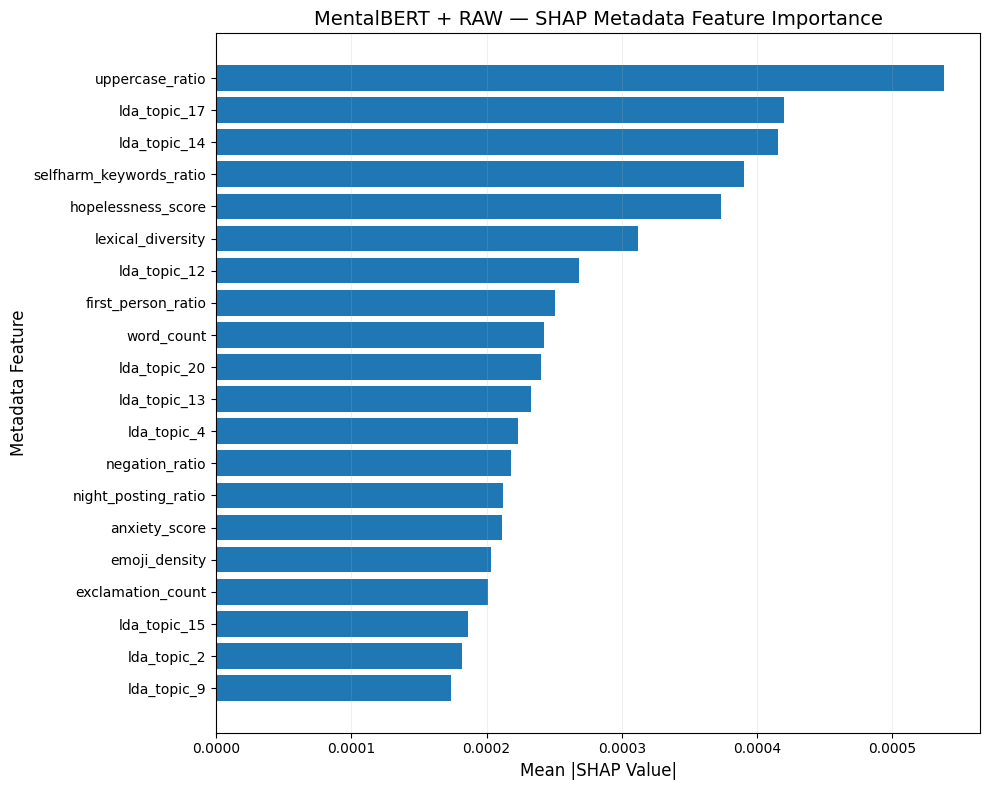

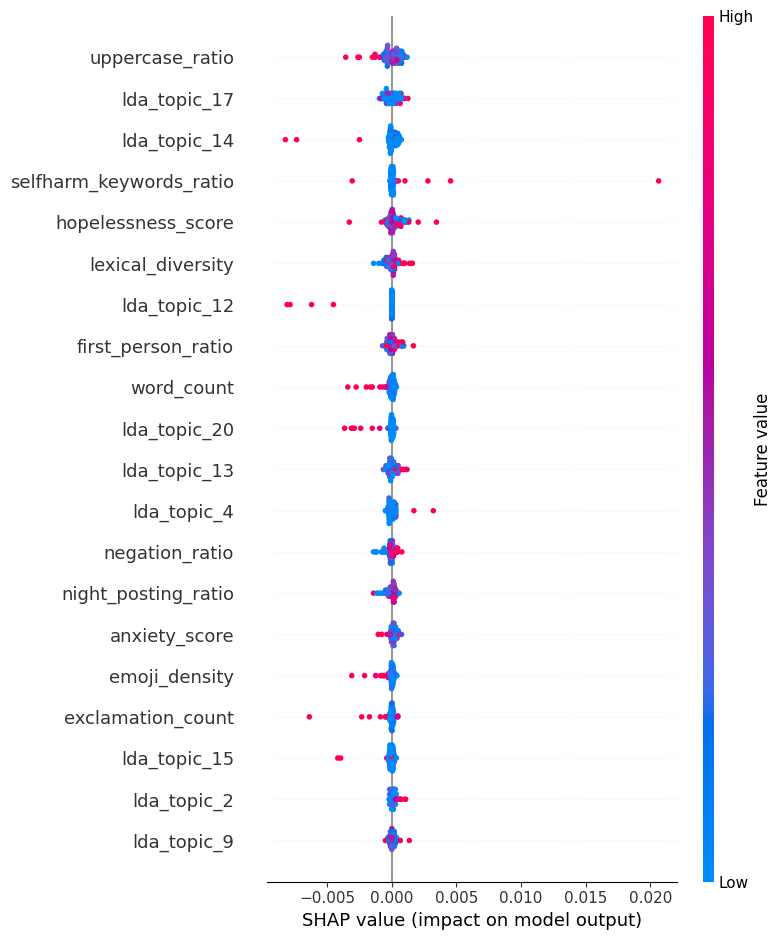


SHAP ANALYSIS COMPLETE
✓ 53 metadata features used
✓ 50 negative + 50 positive test users targeted
✓ Text representation fixed per user
✓ Metadata-only SHAP explanations generated
✓ Global feature importance calculated
✓ SHAP summary plot saved
✓ Top feature plot saved
✓ SHAP CSV saved
✓ Configuration saved

SHAP output directory: /kaggle/working/mentalbert_raw_results/explainability/shap


In [35]:
# ============================================================
# EXPLAINABILITY — CELL 3
# MENTALBERT + RAW
# SHAP: METADATA-LEVEL GLOBAL EXPLANATION
# MEMORY-SAFE VERSION
# ============================================================

import os
import json
import random
import gc
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import shap


print("=" * 70)
print("SHAP ANALYSIS")
print("MENTALBERT + RAW")
print("=" * 70)


# ============================================================
# CUDA MEMORY CLEANUP
# ============================================================

gc.collect()

if torch.cuda.is_available():

    torch.cuda.empty_cache()

    torch.cuda.ipc_collect()


print(
    "✓ CUDA memory cleared"
)


# ============================================================
# FIXED SHAP SETTINGS
# ============================================================

SHAP_SEED = 42
SHAP_BACKGROUND_SIZE = 50
SHAP_TEST_SIZE_PER_CLASS = 50
SHAP_TOP_FEATURES = 20

np.random.seed(
    SHAP_SEED
)

random.seed(
    SHAP_SEED
)

torch.manual_seed(
    SHAP_SEED
)


# ============================================================
# OUTPUT DIRECTORY
# ============================================================

EXPLAINABILITY_DIR = os.path.join(
    MENTAL_RAW_RESULT_DIR,
    "explainability"
)


SHAP_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "shap"
)


os.makedirs(
    SHAP_DIR,
    exist_ok=True
)


# ============================================================
# EXACT 53 METADATA FEATURE NAMES
# ============================================================

behavioral_features = [

    "posting_frequency",

    "follower_friend_ratio",

    "night_posting_ratio",

    "engagement",

    "followers_count",

    "friends_count",

    "statuses_count",

    "favourites_count"
]


linguistic_features = [

    "first_person_ratio",

    "negation_ratio",

    "uppercase_ratio",

    "punctuation_freq"
]


readability_features = [

    "flesch_reading_ease",

    "gunning_fog",

    "flesch_kincaid_grade"
]


emotional_features = [

    "sentiment_score",

    "emotion_score",

    "pos_emoji_count",

    "neg_emoji_count",

    "emoji_density",

    "exclamation_count"
]


psychological_features = [

    "depression_lexicon_score",

    "hopelessness_score",

    "loneliness_score",

    "anxiety_score",

    "sleep_words_ratio",

    "fatigue_words_ratio",

    "selfharm_keywords_ratio"
]


writing_style_features = [

    "avg_sentence_length",

    "lexical_diversity",

    "word_count",

    "avg_paragraph_length",

    "repeated_letters"
]


lda_features = [

    f"lda_topic_{i}"

    for i in range(
        1,
        21
    )
]


raw_metadata_features = (

    behavioral_features
    + linguistic_features
    + readability_features
    + emotional_features
    + psychological_features
    + writing_style_features
    + lda_features
)


assert len(
    raw_metadata_features
) == 53


print(
    f"✓ Metadata features confirmed: "
    f"{len(raw_metadata_features)}"
)


# ============================================================
# MODEL PREPARATION
# ============================================================

model_mental_raw.eval()


# ------------------------------------------------------------
# IMPORTANT:
# Freeze parameters so SHAP calculates gradients
# with respect to metadata only.
# ------------------------------------------------------------

for parameter in (
    model_mental_raw.parameters()
):

    parameter.requires_grad = False


model_mental_raw.zero_grad(
    set_to_none=True
)


print(
    "✓ MentalBERT + RAW model loaded"
)

print(
    "✓ Evaluation mode enabled"
)

print(
    "✓ Model parameters frozen for SHAP"
)


# ============================================================
# SHAP WRAPPER
#
# IMPORTANT MEMORY OPTIMIZATION:
#
# The text representation is already computed once
# for the current user.
#
# SHAP varies ONLY the 53 metadata features.
#
# Therefore MentalBERT does NOT run repeatedly
# inside GradientExplainer.
# ============================================================

class MetadataSHAPWrapper(
    nn.Module
):

    def __init__(
        self,
        model,
        fixed_text_representation
    ):

        super().__init__()

        self.model = model

        self.register_buffer(
            "fixed_text_representation",
            fixed_text_representation
        )


    def forward(
        self,
        metadata
    ):

        batch_size = (
            metadata.shape[0]
        )


        # ----------------------------------------------------
        # METADATA BRANCH
        # ----------------------------------------------------

        metadata_representation = (
            self.model.metadata_branch(
                metadata
            )
        )


        # ----------------------------------------------------
        # EXACT MENTALBERT METADATA GATE
        # ----------------------------------------------------

        metadata_gate = torch.sigmoid(
            self.model.metadata_beta
        )


        gated_metadata = (
            metadata_gate
            * metadata_representation
        )


        # ----------------------------------------------------
        # FIXED TEXT REPRESENTATION
        # ----------------------------------------------------

        text_representation = (
            self.fixed_text_representation
            .expand(
                batch_size,
                -1
            )
        )


        # ----------------------------------------------------
        # EXACT FUSION
        # ----------------------------------------------------

        fused = torch.cat(
            [
                text_representation,
                gated_metadata
            ],
            dim=1
        )


        # ----------------------------------------------------
        # CLASSIFIER
        # ----------------------------------------------------

        logits = self.model.classifier(
            fused
        )


        # Positive / depression class logit
        return logits[
            :,
            1:2
        ]


# ============================================================
# BACKGROUND METADATA
# TRAINING USERS ONLY
# ============================================================

background_metadata = (

    train_dataset_mental_raw.metadata[
        :SHAP_BACKGROUND_SIZE
    ]

    .clone()
    .detach()
    .float()
    .to(device)
)


print()
print("=" * 70)
print("SHAP BACKGROUND")
print("=" * 70)


print(
    "Background samples:",
    background_metadata.shape[0]
)


print(
    "Metadata dimensions:",
    background_metadata.shape[1]
)


assert (
    background_metadata.shape[0]
    ==
    SHAP_BACKGROUND_SIZE
)


assert (
    background_metadata.shape[1]
    ==
    53
)


# ============================================================
# TEST USERS
# 50 NEGATIVE + 50 POSITIVE
# ============================================================

test_labels = np.asarray(
    test_dataset_mental_raw.labels
)


negative_indices = np.where(
    test_labels == 0
)[0]


positive_indices = np.where(
    test_labels == 1
)[0]


np.random.seed(
    SHAP_SEED
)


negative_indices = np.random.choice(
    negative_indices,

    size=min(
        SHAP_TEST_SIZE_PER_CLASS,
        len(negative_indices)
    ),

    replace=False
)


positive_indices = np.random.choice(
    positive_indices,

    size=min(
        SHAP_TEST_SIZE_PER_CLASS,
        len(positive_indices)
    ),

    replace=False
)


selected_shap_indices = np.concatenate(
    [
        negative_indices,
        positive_indices
    ]
)


print()
print("=" * 70)
print("SHAP TEST USERS")
print("=" * 70)


print(
    "Negative users:",
    len(negative_indices)
)


print(
    "Positive users:",
    len(positive_indices)
)


print(
    "Total users:",
    len(selected_shap_indices)
)


# ============================================================
# COMPUTE SHAP VALUES
# ============================================================

all_shap_rows = []

all_user_importance = []


print()
print("=" * 70)
print("GENERATING SHAP EXPLANATIONS")
print("=" * 70)


for count, test_index in enumerate(
    selected_shap_indices,
    start=1
):

    test_index = int(
        test_index
    )


    # --------------------------------------------------------
    # CLEAN MEMORY BEFORE EACH USER
    # --------------------------------------------------------

    gc.collect()

    if torch.cuda.is_available():

        torch.cuda.empty_cache()


    # --------------------------------------------------------
    # GET TEST USER
    # --------------------------------------------------------

    sample = (
        test_dataset_mental_raw[
            test_index
        ]
    )


    input_ids = (
        sample[
            "input_ids"
        ]
        .unsqueeze(0)
        .to(device)
    )


    attention_mask = (
        sample[
            "attention_mask"
        ]
        .unsqueeze(0)
        .to(device)
    )


    metadata = (
        sample[
            "metadata"
        ]
        .unsqueeze(0)
        .to(device)
        .float()
    )


    true_label = int(
        sample[
            "labels"
        ].item()
    )


    # ========================================================
    # STEP 1 — COMPUTE FIXED TEXT REPRESENTATION ONCE
    # ========================================================
    #
    # This is the major memory optimization.
    #
    # SHAP does not need to recompute MentalBERT because
    # text is fixed for this user.
    # ========================================================

    with torch.no_grad():

        base_output = model_mental_raw(
            input_ids=input_ids,

            attention_mask=attention_mask,

            metadata=metadata
        )


        fixed_text_representation = (
            base_output[
                "text_representation"
            ]
            .detach()
        )


    print()
    print(
        f"Processing user "
        f"{count}/"
        f"{len(selected_shap_indices)} "
        f"(test index {test_index})"
    )


    print(
        "Fixed text representation:",
        tuple(
            fixed_text_representation.shape
        )
    )


    # --------------------------------------------------------
    # DELETE FULL MODEL OUTPUT
    # --------------------------------------------------------

    del base_output


    # ========================================================
    # STEP 2 — SHAP WRAPPER
    # ========================================================

    wrapper = MetadataSHAPWrapper(
        model=model_mental_raw,

        fixed_text_representation=
            fixed_text_representation
    ).to(device)


    wrapper.eval()


    # ========================================================
    # STEP 3 — SHAP EXPLAINER
    # ========================================================

    #
    # batch_size=1 keeps SHAP explanation calculations
    # memory-safe.
    #
    # The transformer is NOT inside this wrapper anymore.
    # Only the small metadata branch + classifier executes.
    #

    explainer = shap.GradientExplainer(
        wrapper,

        background_metadata,

        batch_size=1
    )


    # ========================================================
    # STEP 4 — COMPUTE SHAP VALUES
    # ========================================================

    shap_values = explainer.shap_values(
        metadata
    )


    # ========================================================
    # STEP 5 — SHAP VERSION HANDLING
    # ========================================================

    if isinstance(
        shap_values,
        list
    ):

        shap_array = np.asarray(
            shap_values[0]
        )

    else:

        shap_array = np.asarray(
            shap_values
        )


    shap_array = np.squeeze(
        shap_array
    )


    # ========================================================
    # SAFETY CHECK
    # ========================================================

    assert len(
        shap_array
    ) == len(
        raw_metadata_features
    )


    # ========================================================
    # SAVE USER-LEVEL IMPORTANCE
    # ========================================================

    user_importance = pd.DataFrame({

        "feature":
            raw_metadata_features,

        "shap_value":
            shap_array,

        "abs_shap_value":
            np.abs(
                shap_array
            )

    })


    user_importance = (
        user_importance

        .sort_values(
            "abs_shap_value",

            ascending=False
        )

        .reset_index(
            drop=True
        )
    )


    user_importance[
        "test_index"
    ] = test_index


    user_importance[
        "true_label"
    ] = true_label


    all_user_importance.append(
        user_importance
    )


    # ========================================================
    # SAVE ALL FEATURE RESULTS
    # ========================================================

    for rank, row in enumerate(

        user_importance.itertuples(
            index=False
        ),

        start=1
    ):

        all_shap_rows.append({

            "test_index":
                test_index,

            "true_label":
                true_label,

            "feature":
                row.feature,

            "shap_value":
                float(
                    row.shap_value
                ),

            "abs_shap_value":
                float(
                    row.abs_shap_value
                ),

            "rank":
                rank
        })


    # ========================================================
    # PROGRESS
    # ========================================================

    if (

        count == 1

        or

        count % 10 == 0

        or

        count ==
        len(
            selected_shap_indices
        )

    ):

        print(
            f"Processed "
            f"{count}/"
            f"{len(selected_shap_indices)}"
        )


    # ========================================================
    # CLEAN USER MEMORY
    # ========================================================

    del (

        input_ids,

        attention_mask,

        metadata,

        fixed_text_representation,

        wrapper,

        explainer,

        shap_values,

        shap_array,

        user_importance

    )


    gc.collect()


    if torch.cuda.is_available():

        torch.cuda.empty_cache()


# ============================================================
# COMBINE SHAP RESULTS
# ============================================================

shap_results_df = pd.DataFrame(
    all_shap_rows
)


shap_csv_path = os.path.join(
    SHAP_DIR,
    "mentalbert_raw_shap_values.csv"
)


shap_results_df.to_csv(
    shap_csv_path,
    index=False
)


# ============================================================
# GLOBAL FEATURE IMPORTANCE
# ============================================================

global_importance = (

    shap_results_df

    .groupby(
        "feature"
    )[
        "abs_shap_value"
    ]

    .mean()

    .sort_values(
        ascending=False
    )

    .reset_index()
)


global_importance.columns = [

    "feature",

    "mean_abs_shap_value"

]


global_importance[
    "rank"
] = (

    np.arange(
        len(
            global_importance
        )
    )

    + 1

)


global_importance_csv = os.path.join(
    SHAP_DIR,
    "mentalbert_raw_shap_feature_importance.csv"
)


global_importance.to_csv(
    global_importance_csv,
    index=False
)


# ============================================================
# TOP FEATURES
# ============================================================

top_features = (

    global_importance

    .head(
        SHAP_TOP_FEATURES
    )

    .copy()
)


print()
print("=" * 70)
print("TOP SHAP FEATURES")
print("=" * 70)


print(
    top_features[
        [
            "rank",

            "feature",

            "mean_abs_shap_value"
        ]
    ]

    .to_string(
        index=False
    )
)


# ============================================================
# PAPER-READY GLOBAL BAR PLOT
# ============================================================

plot_df = (
    top_features
    .iloc[::-1]
)


plt.figure(
    figsize=(10, 8)
)


plt.barh(
    plot_df[
        "feature"
    ],

    plot_df[
        "mean_abs_shap_value"
    ]
)


plt.xlabel(
    "Mean |SHAP Value|",

    fontsize=12
)


plt.ylabel(
    "Metadata Feature",

    fontsize=12
)


plt.title(
    (
        "MentalBERT + RAW — "
        "SHAP Metadata Feature Importance"
    ),

    fontsize=14
)


plt.grid(
    axis="x",

    alpha=0.20
)


plt.tight_layout()


global_plot_path = os.path.join(
    SHAP_DIR,

    "mentalbert_raw_shap_global_feature_importance.png"
)


plt.savefig(
    global_plot_path,

    dpi=300,

    bbox_inches="tight"
)


plt.show()

plt.close()


# ============================================================
# SHAP SUMMARY / BEESWARM
# ============================================================

# Reconstruct matrix:
# users × features

shap_matrix = np.zeros(
    (
        len(
            selected_shap_indices
        ),

        len(
            raw_metadata_features
        )
    ),

    dtype=np.float32
)


for row_index, test_index in enumerate(
    selected_shap_indices
):

    user_rows = shap_results_df[

        shap_results_df[
            "test_index"
        ]

        == int(
            test_index
        )

    ]


    feature_map = dict(

        zip(

            user_rows[
                "feature"
            ],

            user_rows[
                "shap_value"
            ]

        )
    )


    for feature_index, feature in enumerate(
        raw_metadata_features
    ):

        shap_matrix[
            row_index,
            feature_index
        ] = feature_map.get(
            feature,
            0.0
        )


metadata_matrix = np.asarray(

    [

        test_dataset_mental_raw
        .metadata[
            int(
                test_index
            )
        ]
        .cpu()
        .numpy()

        for test_index in
        selected_shap_indices

    ],

    dtype=np.float32
)


plt.figure(
    figsize=(10, 8)
)


shap.summary_plot(

    shap_matrix,

    metadata_matrix,

    feature_names=
        raw_metadata_features,

    max_display=
        SHAP_TOP_FEATURES,

    show=False
)


plt.tight_layout()


summary_plot_path = os.path.join(

    SHAP_DIR,

    "mentalbert_raw_shap_summary.png"

)


plt.savefig(

    summary_plot_path,

    dpi=300,

    bbox_inches="tight"

)


plt.show()

plt.close()


# ============================================================
# SAVE USER INFORMATION
# ============================================================

user_information = []


for test_index in selected_shap_indices:

    test_index = int(
        test_index
    )


    user_information.append({

        "test_index":
            test_index,

        "true_label":
            int(

                test_dataset_mental_raw

                .labels[
                    test_index
                ]

                .item()

            )

    })


user_information_df = pd.DataFrame(
    user_information
)


user_information_path = os.path.join(

    SHAP_DIR,

    "mentalbert_raw_shap_user_information.csv"

)


user_information_df.to_csv(

    user_information_path,

    index=False

)


# ============================================================
# SAVE CONFIGURATION
# ============================================================

shap_config = {

    "model":
        "MentalBERT",

    "model_name":
        MENTALBERT_MODEL_NAME,

    "cleaning":
        "RAW",

    "dataset":
        "Held-out test set",

    "method":
        "SHAP GradientExplainer",

    "explanation_target":
        "Positive/depression class logit",

    "explanation_type":
        "Metadata-level explanation",

    "metadata_features":
        53,

    "background_size":
        SHAP_BACKGROUND_SIZE,

    "test_size_per_class":
        SHAP_TEST_SIZE_PER_CLASS,

    "total_test_users":
        int(
            len(
                selected_shap_indices
            )
        ),

    "top_features_displayed":
        SHAP_TOP_FEATURES,

    "random_seed":
        SHAP_SEED,

    "model_training":
        "No additional training",

    "transformer_weights":
        "Frozen",

    "text_representation":
        "Computed once per user and fixed during SHAP",

    "fusion":
        "768 + gated 64 = 832"
}


config_path = os.path.join(

    SHAP_DIR,

    "mentalbert_raw_shap_config.json"

)


with open(

    config_path,

    "w"

) as f:

    json.dump(

        shap_config,

        f,

        indent=2

    )


# ============================================================
# FINAL CUDA CLEANUP
# ============================================================

gc.collect()


if torch.cuda.is_available():

    torch.cuda.empty_cache()

    torch.cuda.ipc_collect()


# ============================================================
# COMPLETE
# ============================================================

print()
print("=" * 70)
print("SHAP ANALYSIS COMPLETE")
print("=" * 70)


print(
    "✓ 53 metadata features used"
)


print(
    "✓ 50 negative + 50 positive "
    "test users targeted"
)


print(
    "✓ Text representation fixed "
    "per user"
)


print(
    "✓ Metadata-only SHAP "
    "explanations generated"
)


print(
    "✓ Global feature importance calculated"
)


print(
    "✓ SHAP summary plot saved"
)


print(
    "✓ Top feature plot saved"
)


print(
    "✓ SHAP CSV saved"
)


print(
    "✓ Configuration saved"
)


print()


print(
    "SHAP output directory:",
    SHAP_DIR
)

LIME EXPLAINABILITY
MENTALBERT + RAW
✓ CUDA memory cleared
✓ MentalBERT + RAW model loaded
✓ Evaluation mode enabled
✓ Model parameters frozen

CALCULATING TEST PREDICTIONS
Processed 1/767
Processed 100/767
Processed 200/767
Processed 300/767
Processed 400/767
Processed 500/767
Processed 600/767
Processed 700/767
Processed 767/767

TEST PREDICTIONS READY
Test samples: 767

SELECTED CASES
TP : test index 1 | true=1 | pred=1 | probability=0.9697
TN : test index 0 | true=0 | pred=0 | probability=0.0141
FP : test index 27 | true=0 | pred=1 | probability=0.9950
FN : test index 45 | true=1 | pred=0 | probability=0.0252

GENERATING LIME EXPLANATIONS

Processing TP (test index 1)...
Text length: 1871 characters
✓ TP explanation complete

Processing TN (test index 0)...
Text length: 1985 characters
✓ TN explanation complete

Processing FP (test index 27)...
Text length: 460 characters
✓ FP explanation complete

Processing FN (test index 45)...
Text length: 1582 characters
✓ FN explanation compl


TN — LIME LOCAL EXPLANATION



FP — LIME LOCAL EXPLANATION



FN — LIME LOCAL EXPLANATION


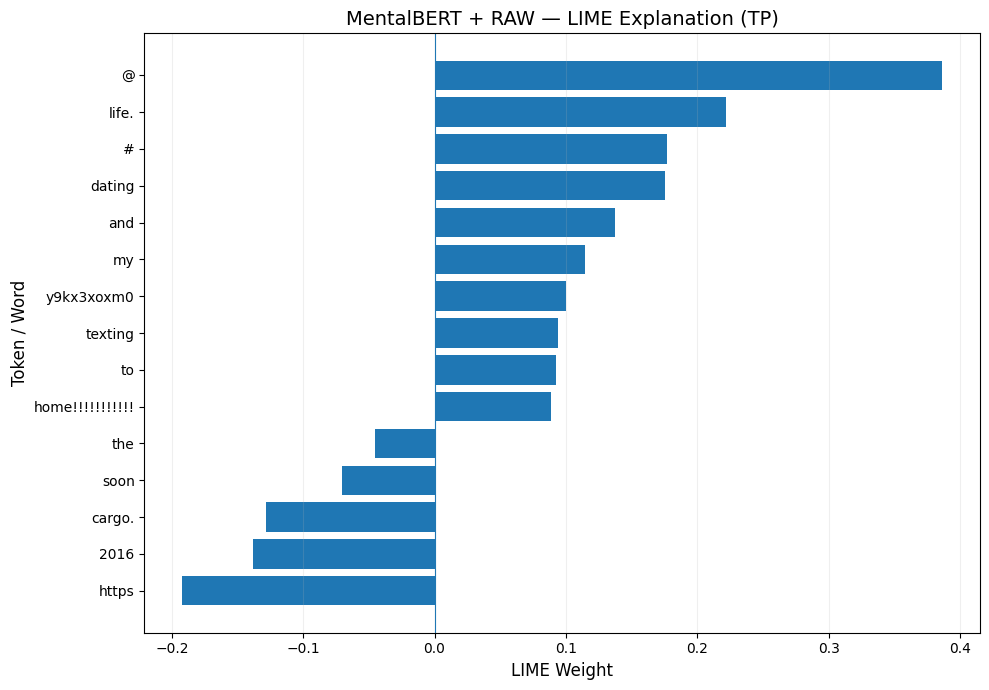

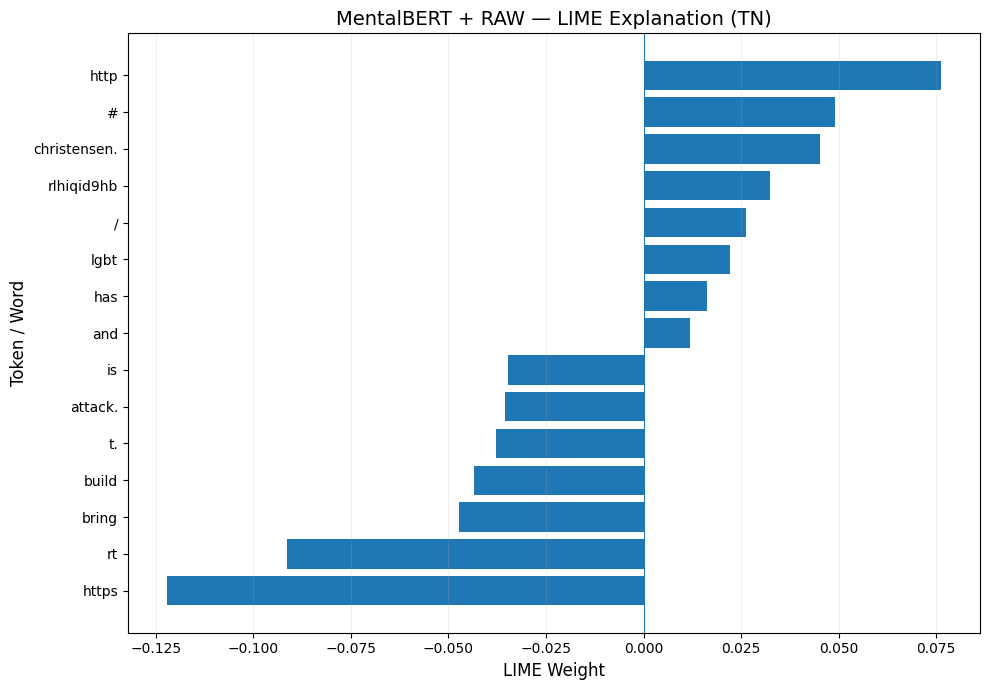

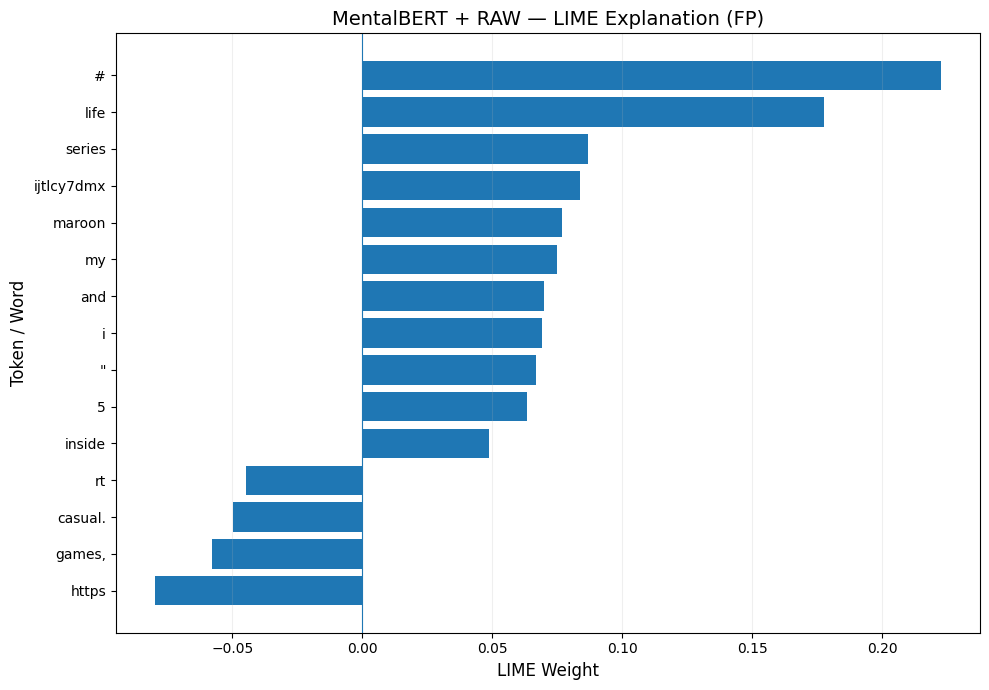

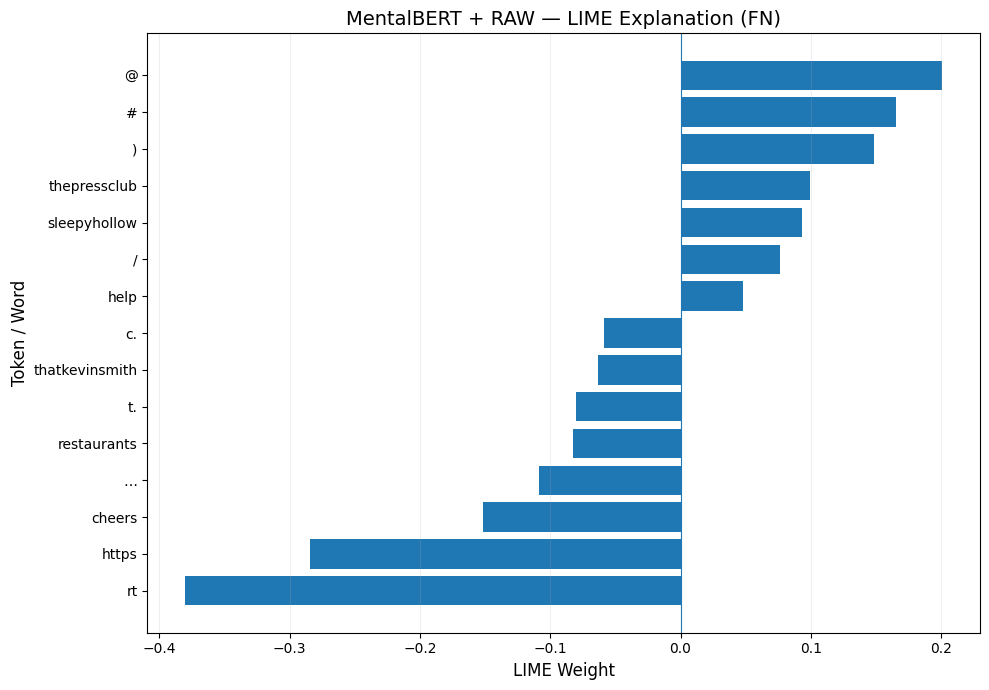


LIME ANALYSIS COMPLETE
✓ TP, TN, FP, FN cases explained
✓ Same trained MentalBERT + RAW model used
✓ Metadata held fixed per user
✓ 1000 LIME perturbations per case
✓ Top 15 features extracted
✓ Memory-safe perturbation inference used
✓ LIME results saved
✓ HTML explanations saved
✓ Paper-ready LIME plots saved and displayed

LIME output directory: /kaggle/working/mentalbert_raw_results/explainability/lime


In [36]:
# ============================================================
# EXPLAINABILITY — LIME
# MENTALBERT + RAW
# TOKEN / WORD-LEVEL LOCAL EXPLANATION
# MEMORY-SAFE VERSION
# ============================================================

import os
import json
import gc
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from lime.lime_text import LimeTextExplainer
from IPython.display import display, HTML


print("=" * 70)
print("LIME EXPLAINABILITY")
print("MENTALBERT + RAW")
print("=" * 70)


# ============================================================
# CUDA MEMORY CLEANUP
# ============================================================

gc.collect()

if torch.cuda.is_available():

    torch.cuda.empty_cache()

    torch.cuda.ipc_collect()


print(
    "✓ CUDA memory cleared"
)


# ============================================================
# FIXED LIME SETTINGS
# ============================================================

LIME_SEED = 42
LIME_NUM_SAMPLES = 1000
LIME_NUM_FEATURES = 15

# Memory-safe:
# one perturbation batch at a time
LIME_BATCH_SIZE = 1


np.random.seed(
    LIME_SEED
)


torch.manual_seed(
    LIME_SEED
)


# ============================================================
# OUTPUT DIRECTORY
# ============================================================

EXPLAINABILITY_DIR = os.path.join(
    MENTAL_RAW_RESULT_DIR,
    "explainability"
)


LIME_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "lime"
)


os.makedirs(
    LIME_DIR,
    exist_ok=True
)


# ============================================================
# MODEL
# ============================================================

model_mental_raw.eval()


# Freeze model parameters
for parameter in model_mental_raw.parameters():

    parameter.requires_grad = False


model_mental_raw.zero_grad(
    set_to_none=True
)


print(
    "✓ MentalBERT + RAW model loaded"
)


print(
    "✓ Evaluation mode enabled"
)


print(
    "✓ Model parameters frozen"
)


# ============================================================
# TEST PREDICTIONS
# MEMORY-SAFE:
# ONE USER AT A TIME
# ============================================================

labels_np = []
preds_np = []
probs_np = []


print()
print("=" * 70)
print("CALCULATING TEST PREDICTIONS")
print("=" * 70)


num_test_samples = len(
    test_dataset_mental_raw
)


for test_index in range(
    num_test_samples
):

    sample = test_dataset_mental_raw[
        test_index
    ]


    input_ids = (
        sample[
            "input_ids"
        ]
        .unsqueeze(0)
        .to(device)
    )


    attention_mask = (
        sample[
            "attention_mask"
        ]
        .unsqueeze(0)
        .to(device)
    )


    metadata = (
        sample[
            "metadata"
        ]
        .unsqueeze(0)
        .to(device)
    )


    with torch.inference_mode():

        output = model_mental_raw(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )


        logits = output[
            "logits"
        ]


        probabilities = torch.softmax(
            logits,
            dim=1
        )


        prediction = torch.argmax(
            logits,
            dim=1
        )


        labels_np.append(
            int(
                sample[
                    "labels"
                ].item()
            )
        )


        preds_np.append(
            int(
                prediction.item()
            )
        )


        probs_np.append(
            float(
                probabilities[
                    0,
                    1
                ].item()
            )
        )


    del (
        input_ids,
        attention_mask,
        metadata,
        output,
        logits,
        probabilities,
        prediction
    )


    if (
        test_index % 25 == 0
    ):

        gc.collect()

        if torch.cuda.is_available():

            torch.cuda.empty_cache()


    if (
        test_index == 0

        or

        (test_index + 1) % 100 == 0

        or

        test_index ==
        num_test_samples - 1
    ):

        print(
            f"Processed "
            f"{test_index + 1}/"
            f"{num_test_samples}"
        )


labels_np = np.asarray(
    labels_np
)


preds_np = np.asarray(
    preds_np
)


probs_np = np.asarray(
    probs_np
)


print()
print("=" * 70)
print("TEST PREDICTIONS READY")
print("=" * 70)


print(
    "Test samples:",
    len(labels_np)
)


# ============================================================
# SELECT TP / TN / FP / FN
# ============================================================

selected_cases = {}


tp_candidates = np.where(
    (labels_np == 1)
    &
    (preds_np == 1)
)[0]


tn_candidates = np.where(
    (labels_np == 0)
    &
    (preds_np == 0)
)[0]


fp_candidates = np.where(
    (labels_np == 0)
    &
    (preds_np == 1)
)[0]


fn_candidates = np.where(
    (labels_np == 1)
    &
    (preds_np == 0)
)[0]


if len(
    tp_candidates
) > 0:

    selected_cases[
        "TP"
    ] = int(
        tp_candidates[0]
    )


if len(
    tn_candidates
) > 0:

    selected_cases[
        "TN"
    ] = int(
        tn_candidates[0]
    )


if len(
    fp_candidates
) > 0:

    selected_cases[
        "FP"
    ] = int(
        fp_candidates[0]
    )


if len(
    fn_candidates
) > 0:

    selected_cases[
        "FN"
    ] = int(
        fn_candidates[0]
    )


print()
print("=" * 70)
print("SELECTED CASES")
print("=" * 70)


for case_name, test_index in selected_cases.items():

    print(
        f"{case_name} : "
        f"test index {test_index} | "
        f"true={labels_np[test_index]} | "
        f"pred={preds_np[test_index]} | "
        f"probability={probs_np[test_index]:.4f}"
    )


# ============================================================
# GET TEST TEXT
# ============================================================
#
# Reconstruct the original text from the exact tokenized
# input already stored in the MentalBERT RAW test dataset.
#
# No external dataframe variable is required.
# ============================================================

def get_test_text(
    test_index
):

    sample = (
        test_dataset_mental_raw[
            int(test_index)
        ]
    )


    token_ids = (
        sample[
            "input_ids"
        ]
        .cpu()
        .tolist()
    )


    text = (
        mentalbert_raw_tokenizer.decode(
            token_ids,
            skip_special_tokens=True,
            clean_up_tokenization_spaces=True
        )
    )


    return str(
        text
    )


# ============================================================
# CREATE LIME PREDICTOR
# TEXT VARIES
# METADATA REMAINS FIXED
# ============================================================

def make_lime_predictor(
    test_index
):

    sample = (
        test_dataset_mental_raw[
            int(test_index)
        ]
    )


    fixed_metadata = (
        sample[
            "metadata"
        ]
        .unsqueeze(0)
        .float()
        .to(device)
    )


    def predictor(
        texts
    ):

        all_probabilities = []


        # ----------------------------------------------------
        # PROCESS ONE PERTURBATION AT A TIME
        # ----------------------------------------------------

        for start in range(
            0,
            len(texts),
            LIME_BATCH_SIZE
        ):

            batch_texts = texts[
                start:
                start + LIME_BATCH_SIZE
            ]


            # ------------------------------------------------
            # TOKENIZE LIME TEXT
            # ------------------------------------------------

            encoded = (
                mentalbert_raw_tokenizer(
                    list(batch_texts),

                    padding="max_length",

                    truncation=True,

                    max_length=MAX_LENGTH,

                    return_attention_mask=True,

                    return_tensors="pt"
                )
            )


            lime_input_ids = (
                encoded[
                    "input_ids"
                ]
                .to(device)
            )


            lime_attention_mask = (
                encoded[
                    "attention_mask"
                ]
                .to(device)
            )


            batch_metadata = (
                fixed_metadata.expand(
                    len(batch_texts),
                    -1
                )
            )


            # ------------------------------------------------
            # MEMORY-SAFE INFERENCE
            # ------------------------------------------------

            with torch.inference_mode():

                output = (
                    model_mental_raw(
                        input_ids=
                            lime_input_ids,

                        attention_mask=
                            lime_attention_mask,

                        metadata=
                            batch_metadata
                    )
                )


                probabilities = torch.softmax(
                    output[
                        "logits"
                    ],
                    dim=1
                )


            # ------------------------------------------------
            # MOVE RESULT TO CPU
            # ------------------------------------------------

            all_probabilities.append(
                probabilities
                .cpu()
                .numpy()
            )


            # ------------------------------------------------
            # DELETE GPU TENSORS
            # ------------------------------------------------

            del (
                lime_input_ids,
                lime_attention_mask,
                batch_metadata,
                output,
                probabilities,
                encoded
            )


            gc.collect()


            if torch.cuda.is_available():

                torch.cuda.empty_cache()


        # ----------------------------------------------------
        # RETURN N × 2 PROBABILITY MATRIX
        # ----------------------------------------------------

        return np.vstack(
            all_probabilities
        )


    return predictor


# ============================================================
# LIME EXPLAINER
# ============================================================

explainer = LimeTextExplainer(

    class_names=[
        "Negative",
        "Positive"
    ],

    split_expression=r"\s+",

    random_state=LIME_SEED
)


# ============================================================
# RUN LIME FOR FOUR CASES
# ============================================================

all_explanations = {}


print()
print("=" * 70)
print("GENERATING LIME EXPLANATIONS")
print("=" * 70)


for case_name, test_index in selected_cases.items():

    print()
    print(
        "=" * 60
    )

    print(
        f"Processing {case_name} "
        f"(test index {test_index})..."
    )

    print(
        "=" * 60
    )


    # --------------------------------------------------------
    # ORIGINAL TEXT
    # --------------------------------------------------------

    text = get_test_text(
        test_index
    )


    print(
        "Text length:",
        len(text),
        "characters"
    )


    # --------------------------------------------------------
    # LIME PREDICTOR
    # --------------------------------------------------------

    predictor = make_lime_predictor(
        test_index
    )


    # --------------------------------------------------------
    # LIME EXPLANATION
    # --------------------------------------------------------

    explanation = (
        explainer.explain_instance(

            text,

            predictor,

            labels=(1,),

            num_features=
                LIME_NUM_FEATURES,

            num_samples=
                LIME_NUM_SAMPLES
        )
    )


    all_explanations[
        case_name
    ] = explanation


    print(
        f"✓ {case_name} explanation complete"
    )


    # --------------------------------------------------------
    # CLEAN MEMORY
    # --------------------------------------------------------

    del (
        predictor,
        text,
        explanation
    )


    gc.collect()


    if torch.cuda.is_available():

        torch.cuda.empty_cache()


# ============================================================
# SAVE LIME RESULTS
# ============================================================

all_lime_rows = []


for case_name, explanation in (
    all_explanations.items()
):


    explanation_list = (
        explanation.as_list(
            label=1
        )
    )


    for rank, (
        word,
        weight
    ) in enumerate(

        explanation_list,

        start=1
    ):


        all_lime_rows.append({

            "case":
                case_name,

            "test_index":
                selected_cases[
                    case_name
                ],

            "true_label":
                int(
                    labels_np[
                        selected_cases[
                            case_name
                        ]
                    ]
                ),

            "predicted_label":
                int(
                    preds_np[
                        selected_cases[
                            case_name
                        ]
                    ]
                ),

            "positive_probability":
                float(
                    probs_np[
                        selected_cases[
                            case_name
                        ]
                    ]
                ),

            "rank":
                rank,

            "word":
                word,

            "lime_weight":
                float(
                    weight
                )

        })


lime_results_df = pd.DataFrame(
    all_lime_rows
)


lime_csv_path = os.path.join(

    LIME_DIR,

    "mentalbert_raw_lime_results.csv"

)


lime_results_df.to_csv(

    lime_csv_path,

    index=False

)


# ============================================================
# DISPLAY + SAVE HTML
# ============================================================

print()
print("=" * 70)
print("LIME EXPLANATIONS")
print("=" * 70)


for case_name, explanation in (
    all_explanations.items()
):


    print()
    print(
        "=" * 60
    )


    print(
        f"{case_name} — "
        f"LIME LOCAL EXPLANATION"
    )


    print(
        "=" * 60
    )


    display(
        HTML(
            explanation.as_html(
                labels=[1]
            )
        )
    )


    html_path = os.path.join(

        LIME_DIR,

        (
            "mentalbert_raw_lime_"
            f"{case_name}.html"
        )

    )


    with open(

        html_path,

        "w",

        encoding="utf-8"

    ) as f:


        f.write(
            explanation.as_html(
                labels=[1]
            )
        )


# ============================================================
# PAPER-FRIENDLY LIME BAR PLOTS
# ============================================================

for case_name, explanation in (
    all_explanations.items()
):


    explanation_list = (
        explanation.as_list(
            label=1
        )
    )


    plot_df = pd.DataFrame(

        explanation_list,

        columns=[
            "word",
            "weight"
        ]

    )


    plot_df = (
        plot_df
        .sort_values(
            "weight"
        )
    )


    plt.figure(
        figsize=(10, 7)
    )


    plt.barh(
        plot_df[
            "word"
        ],

        plot_df[
            "weight"
        ]
    )


    plt.axvline(
        0,

        linewidth=0.8
    )


    plt.xlabel(
        "LIME Weight",

        fontsize=12
    )


    plt.ylabel(
        "Token / Word",

        fontsize=12
    )


    plt.title(
        (
            "MentalBERT + RAW — "
            f"LIME Explanation ({case_name})"
        ),

        fontsize=14
    )


    plt.grid(
        axis="x",

        alpha=0.20
    )


    plt.tight_layout()


    plot_path = os.path.join(

        LIME_DIR,

        (
            "mentalbert_raw_lime_"
            f"{case_name}.png"
        )

    )


    plt.savefig(

        plot_path,

        dpi=300,

        bbox_inches="tight"

    )


    plt.show()

    plt.close()


# ============================================================
# SAVE CASE INFORMATION
# ============================================================

case_info_rows = []


for case_name, test_index in (
    selected_cases.items()
):


    case_info_rows.append({

        "case":
            case_name,

        "test_index":
            int(
                test_index
            ),

        "true_label":
            int(
                labels_np[
                    test_index
                ]
            ),

        "predicted_label":
            int(
                preds_np[
                    test_index
                ]
            ),

        "positive_probability":
            float(
                probs_np[
                    test_index
                ]
            ),

        "text_length_characters":
            len(
                get_test_text(
                    test_index
                )
            )

    })


case_info_df = pd.DataFrame(
    case_info_rows
)


case_info_path = os.path.join(

    LIME_DIR,

    "mentalbert_raw_lime_case_information.csv"

)


case_info_df.to_csv(

    case_info_path,

    index=False

)


# ============================================================
# SAVE CONFIGURATION
# ============================================================

lime_config = {

    "model":
        "MentalBERT",

    "model_name":
        MENTALBERT_MODEL_NAME,

    "cleaning":
        "RAW",

    "dataset":
        "Held-out test set",

    "target":
        "Positive/depression class",

    "representative_cases":
        [
            "TP",
            "TN",
            "FP",
            "FN"
        ],

    "case_selection":
        "First matching test example in fixed test order",

    "random_seed":
        LIME_SEED,

    "num_samples":
        LIME_NUM_SAMPLES,

    "num_features":
        LIME_NUM_FEATURES,

    "batch_size":
        LIME_BATCH_SIZE,

    "metadata":
        "Fixed for each explained user",

    "text_perturbation":
        "LIME word-level perturbations",

    "max_length":
        MAX_LENGTH,

    "model_training":
        "No additional training",

    "transformer_weights":
        "Frozen",

    "memory_mode":
        "One perturbation at a time"

}


config_path = os.path.join(

    LIME_DIR,

    "mentalbert_raw_lime_config.json"

)


with open(

    config_path,

    "w"

) as f:


    json.dump(

        lime_config,

        f,

        indent=2

    )


# ============================================================
# FINAL CUDA CLEANUP
# ============================================================

gc.collect()


if torch.cuda.is_available():

    torch.cuda.empty_cache()

    torch.cuda.ipc_collect()


# ============================================================
# COMPLETE
# ============================================================

print()
print("=" * 70)
print("LIME ANALYSIS COMPLETE")
print("=" * 70)


print(
    "✓ TP, TN, FP, FN cases explained"
)


print(
    "✓ Same trained MentalBERT + RAW model used"
)


print(
    "✓ Metadata held fixed per user"
)


print(
    f"✓ {LIME_NUM_SAMPLES} LIME perturbations per case"
)


print(
    f"✓ Top {LIME_NUM_FEATURES} features extracted"
)


print(
    "✓ Memory-safe perturbation inference used"
)


print(
    "✓ LIME results saved"
)


print(
    "✓ HTML explanations saved"
)


print(
    "✓ Paper-ready LIME plots saved and displayed"
)


print()


print(
    "LIME output directory:",
    LIME_DIR
)